In [1]:
# Import libraries
import numpy as np
import pandas as pd
from collections import Counter, defaultdict
import matplotlib.pyplot as plt
from IPython.display import display, HTML
from sklearn.cluster import DBSCAN
from sklearn.decomposition import PCA
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity, cosine_distances
from sklearn.preprocessing import OneHotEncoder, normalize
from sklearn.metrics import pair_confusion_matrix, silhouette_score
from PIL import Image
import torchvision.models as models
import torchvision.transforms as transforms
import requests
from io import BytesIO
import os
import json
import torch
import hdbscan

In [2]:
!pip install -qq hdbscan
!pip install -qq rapidfuzz

# **EDA & preprocessing**

In [3]:
# Read data
df = pd.read_json('sneakers_sample_19062025.txt', lines=False)

print(df.head())

                                                data  \
0  {'EAN': [], 'size': '44', 'brand': 'ASICS', 'c...   
1  {'EAN': [], 'size': '44', 'brand': 'VANS', 'co...   
2  {'EAN': [], 'size': '44.5', 'brand': 'ADIDAS',...   
3  {'EAN': [], 'size': '42', 'brand': 'NIKE', 'co...   
4  {'EAN': [], 'size': '11/EU 46', 'brand': 'PUMA...   

                      mirakl_product_id             creation_date  \
0  d96975c5-0bea-41f6-a4a8-fdac53f374f3  2024-01-09T12:09:20.568Z   
1  6f302b78-9a86-484e-894f-bb39220931a3  2023-11-09T13:08:33.276Z   
2  70006973-aa9f-4176-9f38-0ba2c5a1b06f  2025-03-29T08:43:47.421Z   
3  6b010b1d-7475-44dc-ad56-502769d2e742  2024-01-04T12:29:59.343Z   
4  cf04d217-bfd6-4743-ae4b-bc98712959ca  2025-02-13T14:31:57.524Z   

                update_date                           product_sku  \
0  2024-11-06T13:03:01.469Z  d96975c5-0bea-41f6-a4a8-fdac53f374f3   
1  2025-02-12T12:21:44.083Z  6f302b78-9a86-484e-894f-bb39220931a3   
2  2025-03-30T21:07:23.464Z  70006973-aa9

In [4]:
df.head()

,data,mirakl_product_id,creation_date,update_date,product_sku,validation,synchronization,catalogs,product_urls,sources,selling_authorization,data_origin
0,"{'EAN': [], 'size': '44', 'brand': 'ASICS', 'c...",d96975c5-0bea-41f6-a4a8-fdac53f374f3,2024-01-09T12:09:20.568Z,2024-11-06T13:03:01.469Z,d96975c5-0bea-41f6-a4a8-fdac53f374f3,"{'status': 'VALID', 'validation_errors': []}",{'status': 'SYNCHRONIZED'},[],[],"[{'provider_code': '2077', 'provider_sku': '10...","{'restricted': False, 'authorized_selling_shop...","{'name [en_GB]': {'origin': 'PROVIDER', 'provi..."
1,"{'EAN': [], 'size': '44', 'brand': 'VANS', 'co...",6f302b78-9a86-484e-894f-bb39220931a3,2023-11-09T13:08:33.276Z,2025-02-12T12:21:44.083Z,6f302b78-9a86-484e-894f-bb39220931a3,"{'status': 'VALID', 'validation_errors': []}",{'status': 'SYNCHRONIZED'},[],[],"[{'provider_code': '2002', 'provider_sku': 'VN...","{'restricted': False, 'authorized_selling_shop...","{'name [en_GB]': {'origin': 'PROVIDER', 'provi..."
2,"{'EAN': [], 'size': '44.5', 'brand': 'ADIDAS',...",70006973-aa9f-4176-9f38-0ba2c5a1b06f,2025-03-29T08:43:47.421Z,2025-03-30T21:07:23.464Z,70006973-aa9f-4176-9f38-0ba2c5a1b06f,"{'status': 'VALID', 'validation_errors': []}",{'status': 'SYNCHRONIZED'},[],[],"[{'provider_code': '2167', 'provider_sku': 'IH...","{'restricted': False, 'authorized_selling_shop...","{'name [en_GB]': {'origin': 'PROVIDER', 'provi..."
3,"{'EAN': [], 'size': '42', 'brand': 'NIKE', 'co...",6b010b1d-7475-44dc-ad56-502769d2e742,2024-01-04T12:29:59.343Z,2024-11-06T13:00:53.470Z,6b010b1d-7475-44dc-ad56-502769d2e742,"{'status': 'VALID', 'validation_errors': []}",{'status': 'SYNCHRONIZED'},[],[],"[{'provider_code': '2077', 'provider_sku': 'CT...","{'restricted': False, 'authorized_selling_shop...","{'name [en_GB]': {'origin': 'PROVIDER', 'provi..."
4,"{'EAN': [], 'size': '11/EU 46', 'brand': 'PUMA...",cf04d217-bfd6-4743-ae4b-bc98712959ca,2025-02-13T14:31:57.524Z,2025-03-01T00:03:24.205Z,cf04d217-bfd6-4743-ae4b-bc98712959ca,"{'status': 'VALID', 'validation_errors': []}",{'status': 'SYNCHRONIZED'},[],[],"[{'provider_code': '3390', 'provider_sku': '46...","{'restricted': False, 'authorized_selling_shop...","{'name [en_GB]': {'origin': 'PROVIDER', 'provi..."


### Create separate dataframes

In [5]:
# Load the JSON file
with open('sneakers_sample_19062025.txt', 'r', encoding='utf-8') as f:    # added encoding = utf8 otherwise: decoding error
    raw_data = json.load(f)

# Create separate dataframes
meta_rows = []
data_rows = []
sources_rows = []

# Exclude some fields that are not necessary for our tasks
exclude_fields = {
    'creation_date', 'update_date',
    'validation', 'synchronization',
    'catalogs', 'selling_authorization', "product_urls"
}

for entry in raw_data:
    # Top-level fields
    meta = {
        key: entry[key] for key in entry
        if key not in exclude_fields and key not in ['data', 'sources']
    }
    meta_rows.append(meta)
    
    # Extract nested fields (if they exist)
    if 'data' in entry:
        data_rows.append(entry['data'])
    if 'sources' in entry and isinstance(entry['sources'], list):
        for source in entry['sources']:
            # Optionally, attach product ID to track back
            source['mirakl_product_id'] = entry.get('mirakl_product_id')
            sources_rows.append(source)

# Convert all parts to DataFrames
df_meta = pd.DataFrame(meta_rows)
df_data = pd.json_normalize(data_rows)
df_sources = pd.DataFrame(sources_rows)

# Preview
print("Meta columns:", df_meta.columns.tolist())
print("Data columns:", df_data.columns.tolist())
print("Sources sample:", df_sources.head())

Meta columns: ['mirakl_product_id', 'product_sku', 'data_origin']
Data columns: ['EAN', 'size', 'brand', 'color', 'category', 'returnable', 'name [el_CY]', 'name [en_GB]', 'updateOnDelta', 'refinementColor', 'variantGroupCode', 'jiniusSkuMatchCode', 'shortDescription [el_CY]', 'shortDescription [en_GB]', 'mainImage.source', 'mainImage.original_url', 'secondary_image_1.source', 'secondary_image_1.original_url', 'secondary_image_2.source', 'secondary_image_2.original_url', 'secondary_image_3.source', 'secondary_image_3.original_url', 'longDescription [en_GB]', 'longDescription [el_CY]', 'shoeType', 'shoeShape', 'fashionMaterial', 'shoeWidth', 'heelHeight', 'name', 'heelType', 'longDescription', 'shortDescription']
Sources sample:   provider_code                               provider_sku  \
0          2077        1071A091-101--EUM-18--WHITE / BLACK   
1          2002                   VN0A3MTJT2J1--417--BLACK   
2          2167                                IH6003-44.5   
3          207

In [6]:
df_data

,EAN,size,brand,color,category,returnable,name [el_CY],name [en_GB],updateOnDelta,refinementColor,...,longDescription [el_CY],shoeType,shoeShape,fashionMaterial,shoeWidth,heelHeight,name,heelType,longDescription,shortDescription
0,[],44,ASICS,White / Black,FaMeShSneakers,true,Gel-rocket 11 mens volleyball/indoor shoes,Gel-rocket 11 mens volleyball/indoor shoes,None,white,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,[],44,VANS,Black,FaMeShSneakers,true,Mens filmore suede,Mens filmore suede,None,black,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,[],44.5,ADIDAS,NaN,FaMeShSneakers,true,Ih6003,Adidas response,NaN,white,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,[],42,NIKE,White / Black / Volt,FaMeShSneakers,true,React vision worldwide mens,React vision worldwide mens,None,white,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,[],11/EU 46,PUMA,Black/white,FaMeShSneakers,true,Puma men's x-ray 3 sd,Puma men's x-ray 3 sd,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5818,[],37,BUFFALO,White / Silver / Black,FaWoShSneakers,true,Triple hollow sneakers,Triple hollow sneakers,None,white,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5819,[],39,ADIDAS ORIGINALS,White,FaWoShSneakers,true,Adidas sambae w,Adidas sambae w,NaN,white,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5820,[],41,GUESS,White,FaWoShSneakers,true,Elbina sneakers,Elbina sneakers,None,white,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5821,[],36.5,NEW BALANCE,Cloud White / Burgundy,FaWoShSneakers,true,327 sportstyle sneakers,327 sportstyle sneakers,None,miscellaneous,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [7]:
df_meta

,mirakl_product_id,product_sku,data_origin
0,d96975c5-0bea-41f6-a4a8-fdac53f374f3,d96975c5-0bea-41f6-a4a8-fdac53f374f3,"{'name [en_GB]': {'origin': 'PROVIDER', 'provi..."
1,6f302b78-9a86-484e-894f-bb39220931a3,6f302b78-9a86-484e-894f-bb39220931a3,"{'name [en_GB]': {'origin': 'PROVIDER', 'provi..."
2,70006973-aa9f-4176-9f38-0ba2c5a1b06f,70006973-aa9f-4176-9f38-0ba2c5a1b06f,"{'name [en_GB]': {'origin': 'PROVIDER', 'provi..."
3,6b010b1d-7475-44dc-ad56-502769d2e742,6b010b1d-7475-44dc-ad56-502769d2e742,"{'name [en_GB]': {'origin': 'PROVIDER', 'provi..."
4,cf04d217-bfd6-4743-ae4b-bc98712959ca,cf04d217-bfd6-4743-ae4b-bc98712959ca,"{'name [en_GB]': {'origin': 'PROVIDER', 'provi..."
...,...,...,...
5818,acdb8093-c93c-49d7-af05-f04cae009f99,acdb8093-c93c-49d7-af05-f04cae009f99,"{'name [en_GB]': {'origin': 'PROVIDER', 'provi..."
5819,e733c608-da84-49f1-a3ae-52a025b1cb3d,e733c608-da84-49f1-a3ae-52a025b1cb3d,"{'name [en_GB]': {'origin': 'PROVIDER', 'provi..."
5820,6d8cf85e-93bd-47ea-8a59-3e43fe4ef732,6d8cf85e-93bd-47ea-8a59-3e43fe4ef732,"{'name [en_GB]': {'origin': 'PROVIDER', 'provi..."
5821,e2d00db3-27b2-4996-89e2-5c1579af5d39,e2d00db3-27b2-4996-89e2-5c1579af5d39,"{'name [en_GB]': {'origin': 'PROVIDER', 'provi..."


We observe that `data_origin` column is nested.

In [8]:
# Flatten 'data_origin' column
data_origin_df = pd.json_normalize(df_meta['data_origin'])

# Add prefixes so we know where they came from
data_origin_df = data_origin_df.add_prefix('origin_')

# Drop original nested columns from df_meta
df_meta = df_meta.drop(columns=['data_origin'])

# Merge the flattened parts back
df_meta = pd.concat([df_meta, data_origin_df], axis=1)

In [9]:
df_meta

,mirakl_product_id,product_sku,origin_name [en_GB].origin,origin_name [en_GB].provider_code,origin_name [el_CY].origin,origin_name [el_CY].provider_code,origin_color.origin,origin_color.provider_code,origin_shortDescription [el_CY].origin,origin_shortDescription [el_CY].provider_code,...,origin_heelHeight.origin,origin_heelHeight.provider_code,origin_longDescription.origin,origin_longDescription.provider_code,origin_shortDescription.origin,origin_shortDescription.provider_code,origin_name.origin,origin_name.provider_code,origin_heelType.origin,origin_heelType.provider_code
0,d96975c5-0bea-41f6-a4a8-fdac53f374f3,d96975c5-0bea-41f6-a4a8-fdac53f374f3,PROVIDER,2077,PROVIDER,2077,PROVIDER,2077,PROVIDER,2077,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,6f302b78-9a86-484e-894f-bb39220931a3,6f302b78-9a86-484e-894f-bb39220931a3,PROVIDER,2002,PROVIDER,2002,PROVIDER,2002,PROVIDER,2002,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,70006973-aa9f-4176-9f38-0ba2c5a1b06f,70006973-aa9f-4176-9f38-0ba2c5a1b06f,PROVIDER,2167,PROVIDER,2167,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,6b010b1d-7475-44dc-ad56-502769d2e742,6b010b1d-7475-44dc-ad56-502769d2e742,PROVIDER,2077,PROVIDER,2077,PROVIDER,2077,PROVIDER,2077,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,cf04d217-bfd6-4743-ae4b-bc98712959ca,cf04d217-bfd6-4743-ae4b-bc98712959ca,PROVIDER,3390,PROVIDER,3390,PROVIDER,3390,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5818,acdb8093-c93c-49d7-af05-f04cae009f99,acdb8093-c93c-49d7-af05-f04cae009f99,PROVIDER,2077,PROVIDER,2077,PROVIDER,2077,PROVIDER,2077,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5819,e733c608-da84-49f1-a3ae-52a025b1cb3d,e733c608-da84-49f1-a3ae-52a025b1cb3d,PROVIDER,3429,PROVIDER,3429,PROVIDER,3429,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5820,6d8cf85e-93bd-47ea-8a59-3e43fe4ef732,6d8cf85e-93bd-47ea-8a59-3e43fe4ef732,PROVIDER,2002,PROVIDER,2002,PROVIDER,2002,PROVIDER,2002,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5821,e2d00db3-27b2-4996-89e2-5c1579af5d39,e2d00db3-27b2-4996-89e2-5c1579af5d39,PROVIDER,2077,PROVIDER,2077,PROVIDER,2077,PROVIDER,2077,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [10]:
df_sources

,provider_code,provider_sku,mirakl_product_id
0,2077,1071A091-101--EUM-18--WHITE / BLACK,d96975c5-0bea-41f6-a4a8-fdac53f374f3
1,2002,VN0A3MTJT2J1--417--BLACK,6f302b78-9a86-484e-894f-bb39220931a3
2,2167,IH6003-44.5,70006973-aa9f-4176-9f38-0ba2c5a1b06f
3,2077,CT2927-100--USAM-09--WHITE / BLACK / VOLT,6b010b1d-7475-44dc-ad56-502769d2e742
4,3390,468781-1870785842,cf04d217-bfd6-4743-ae4b-bc98712959ca
...,...,...,...
5818,2077,1636155--EUM-05--WHITE / SILVER / BLACK,acdb8093-c93c-49d7-af05-f04cae009f99
5819,3429,JI1349--1310--WHITE,e733c608-da84-49f1-a3ae-52a025b1cb3d
5820,2002,FLJELBLEA12WHBEI--401--WHITE,6d8cf85e-93bd-47ea-8a59-3e43fe4ef732
5821,2077,WS327-KA--EUM-04--CLOUD WHITE / BURGUNDY,e2d00db3-27b2-4996-89e2-5c1579af5d39


Our algorithms are **evaluated** on a manually labeled sample dataset. The labels correspond to variant groupings, which means that **only Task 2 can currently be evaluated**. However, Task 1 could be evaluated in a similar manner, provided we have a sample dataset labeled specifically for that task.

In [11]:
# Load the sample to evaluate the groups
sample_df = pd.read_csv("sample.csv")

Now that we have separate flattened dataframes we can investigate whether we have missing values and in which fields.

In [12]:
df_data.isna().sum()

EAN                                  0
size                                 0
brand                               11
color                               15
category                             0
returnable                           0
name [el_CY]                       608
name [en_GB]                         0
updateOnDelta                     5819
refinementColor                    733
variantGroupCode                     0
jiniusSkuMatchCode                   0
shortDescription [el_CY]          1336
shortDescription [en_GB]             0
mainImage.source                     0
mainImage.original_url               4
secondary_image_1.source           290
secondary_image_1.original_url     292
secondary_image_2.source           437
secondary_image_2.original_url     437
secondary_image_3.source           737
secondary_image_3.original_url     737
longDescription [en_GB]           5585
longDescription [el_CY]           5716
shoeType                          5681
shoeShape                

In [13]:
df_meta.isna().sum()

mirakl_product_id                                   0
product_sku                                         0
origin_name [en_GB].origin                          0
origin_name [en_GB].provider_code                 153
origin_name [el_CY].origin                        608
origin_name [el_CY].provider_code                 682
origin_color.origin                                15
origin_color.provider_code                        155
origin_shortDescription [el_CY].origin           1336
origin_shortDescription [el_CY].provider_code    1340
origin_secondary_image_2.origin                   437
origin_secondary_image_2.provider_code            446
origin_secondary_image_1.origin                   288
origin_secondary_image_1.provider_code            306
origin_shortDescription [en_GB].origin              0
origin_shortDescription [en_GB].provider_code      61
origin_secondary_image_3.origin                   737
origin_secondary_image_3.provider_code            741
origin_mainImage.origin     

In [14]:
df_sources.isna().sum()

provider_code        0
provider_sku         0
mirakl_product_id    0
dtype: int64

From the above we observe that some important fields (such as color, brand, descriptions) contain missing values.

In [15]:
# check the values of jiniusSkuMatchCode column
df_data["jiniusSkuMatchCode"].describe() 

count     5823
unique       1
top         []
freq      5823
Name: jiniusSkuMatchCode, dtype: object

`jiniusSkuMatchCode` column is only has empty lists, although it appeared to have no missing values.

In [16]:
#check the number of records with empty EAN
df_data["EAN"].describe()

count     5823
unique     487
top         []
freq      5337
Name: EAN, dtype: object

In [17]:
df_data["EAN"].apply(lambda x: x == []).sum()

5337

From the 5823 observations, 5337 of them have empty EAN code and the remaining have a unique EAN code. So no products are grouped by the EAN code.

In [18]:
df_data['brand'].isna().sum()

11

In [19]:
df_data[df_data['brand'].isna()][['name [en_GB]','name', 'color', 'category', 'shortDescription', 'brand']]

,name [en_GB],name,color,category,shortDescription,brand
1075,C8979,NaN,Black,FaMeShSneakers,NaN,NaN
2258,C8979,NaN,All White,FaMeShSneakers,NaN,NaN
2559,C8979,NaN,Black,FaMeShSneakers,NaN,NaN
2941,C895,NaN,White,FaWoShSneakers,NaN,NaN
3856,C895,NaN,Black,FaWoShSneakers,NaN,NaN
4193,C667,NaN,White,FaWoShSneakers,NaN,NaN
4469,C872,NaN,White,FaWoShSneakers,NaN,NaN
4777,C8962,NaN,Black,FaWoShSneakers,NaN,NaN
5033,C667,NaN,White,FaWoShSneakers,NaN,NaN
5451,C666,NaN,White,FaWoShSneakers,NaN,NaN


In [20]:
df_data[df_data['brand'] == 'CALVIN KLEIN JEANS']

,EAN,size,brand,color,category,returnable,name [el_CY],name [en_GB],updateOnDelta,refinementColor,...,longDescription [el_CY],shoeType,shoeShape,fashionMaterial,shoeWidth,heelHeight,name,heelType,longDescription,shortDescription
148,[],45,CALVIN KLEIN JEANS,Black / White,FaMeShSneakers,true,Basket cupsole low leather sneakers,Basket cupsole low leather sneakers,None,white,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
335,[],45,CALVIN KLEIN JEANS,White,FaMeShSneakers,true,Retro tennis low laceup mtl,Retro tennis low laceup mtl,None,white,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
660,[],45,CALVIN KLEIN JEANS,White,FaMeShSneakers,true,Senakers,Senakers,None,white,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
675,[],42,CALVIN KLEIN JEANS,Black,FaMeShSneakers,true,Chunky cupsole authentic shoe,Chunky cupsole authentic shoe,None,black,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1204,[],43,CALVIN KLEIN JEANS,White,FaMeShSneakers,true,Chunky cupsole mono leather,Chunky cupsole mono leather,None,white,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1297,[],44,CALVIN KLEIN JEANS,Black,FaMeShSneakers,true,Retro tennis low laceup mtl,Retro tennis low laceup mtl,None,black,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1992,[],41,CALVIN KLEIN JEANS,White,FaMeShSneakers,true,Claic cupsole iconic nylon shoe,Claic cupsole iconic nylon shoe,NaN,white,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3580,[],40,CALVIN KLEIN JEANS,Black,FaWoShSneakers,true,Chunky cupsole laceup leather shoe,Chunky cupsole laceup leather shoe,None,black,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5088,[],40,CALVIN KLEIN JEANS,White,FaWoShSneakers,true,Retro tennis su-mesh wn,Retro tennis su-mesh wn,None,white,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [21]:
df_data[df_data['brand'] == 'CALVIN KLEIN']

,EAN,size,brand,color,category,returnable,name [el_CY],name [en_GB],updateOnDelta,refinementColor,...,longDescription [el_CY],shoeType,shoeShape,fashionMaterial,shoeWidth,heelHeight,name,heelType,longDescription,shortDescription
4411,[5299901986314],36,CALVIN KLEIN,White,FaWoShSneakers,true,Eva runner low lace shoes,Eva runner low lace shoes,None,white,...,NaN,0090,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


The outputs above reveal inconsistencies in brand naming (e.g., *LIU JO SHOES* vs *LIU JO*). To ensure consistency, we apply a brand name mapping that standardizes all variations.

In [22]:
df_data['brand'].unique()

array(['ASICS', 'VANS', 'ADIDAS', 'NIKE', 'PUMA', 'CONVERSE',
       'ADIDAS ORIGINALS', 'UNDER ARMOUR', 'SAUCONY', 'REEBOK', 'JORDAN',
       'DIESEL', 'CHAMPION', 'NEW BALANCE', 'FRED PERRY', 'SKECHERS',
       'ON RUNNING', 'EA7', 'JOMA', 'CARRERA', "LEVI'S", 'VEJA',
       'PEPE SHOES', 'TALBOT SHOES', 'U.S. POLO ASSN.',
       'PEPE JEANS LONDON', 'TOMMY HILFIGER', 'CALVIN KLEIN JEANS', 'DC',
       'STEFAN', 'ANTONY MORATO', 'TOMMY JEANS', 'KAPPA', 'LYLE & SCOTT',
       'HACKETT', 'KARL KANI', 'SERGIO TACCHINI', 'TAMARIS', 'REVERSE',
       'BAZAAR CHARM', 'MORK EXCLUSIVE', 'LACOSTE', 'SOUTHPORT',
       'SALOMON', 'GAUDI', 'JACK & JONES', 'FUNKY BUDDHA', 'HUGO BOSS',
       'FENOMILANO', 'FILA', 'RHAPSODY', 'BOSTON SPORT CLUB', 'MIMSOGA',
       'SUN68', 'LIU JO SHOES', 'LOTTO', 'PLATO', 'MIZUNO', 'ADMIRAL',
       'BROOKS', 'SIKSILK', 'NICO', 'ICE PLAY', 'BHPC', 'GUESS DENIM',
       'PARIS', 'NO NAME ATHENS', 'GUESS', 'ATLANTA', nan,
       'BE YOU, U.S. POLO ASSN', 'THE NORT

In [23]:
brand_mapping = {
    'ADIDAS ORIGINALS': 'ADIDAS',
    'CALVIN KLEIN JEANS': 'CALVIN KLEIN',
    'LIU JO SHOES': 'LIU JO',
    'GUESS DENIM': 'GUESS',
    'TOMMY JEANS': 'TOMMY HILFIGER',
    'PEPE JEANS LONDON': 'PEPE JEANS',
    'BE YOU, U.S. POLO ASSN': 'U.S. POLO ASSN.',
    'BHPC': 'BEVERLY HILLS POLO CLUB',
    'EA7': 'EMPORIO ARMANI',
    'NO NAME ATHENS': 'NO NAME'
}

In [24]:
df_data_copy = df_data.copy()

df_data_copy['brand_label'] = df_data_copy['brand'].replace(brand_mapping)

In [25]:
df_data['brand'].nunique()

128

In [26]:
df_data_copy['brand'].nunique()

128

In [27]:
df_data_copy['brand_label'].nunique()

121

In [28]:
df_data_copy[df_data_copy['brand_label'] == 'ADIDAS']['name [en_GB]'].unique()

array(['Adidas response', 'Adidas gazelle shoes', 'Swift run 22',
       'Adistar 2 men', 'Midcity mid',
       "Adidas men's supernova stride shoes", 'Duramo speed men',
       'Adidas gazelle indoor', 'Gazelle shoes', 'Cloudfoam go lounge',
       'Midcity low', 'Strutter', 'Response runner unisex',
       'Response super mens', 'Adidas grand court base 2.0',
       'Stan smith vegan', 'Forest grove sneakers', 'Znsored hi mens',
       'Fukasa run', 'Cloudfoam comfy', 'Urban court',
       'Adidas alphaboost v1', 'Alphabounce + c', 'Samba classic',
       'Copa mundial', 'Ozelle', 'Adistar 3', 'X_plrphase',
       'Ultimashow 2.0',
       'Adidas questar             greone/cblack/grethr', 'Advantage 2.0',
       'Adidas copa pure.3 tf', 'Grand court 2.0', 'Samba og',
       'Adidas handball spezial', 'Handball spezial', 'Runfalcon 3.0',
       'Runfalcon 5', 'Adidas men duramo sl', 'Copa pure.1 firm ground',
       "Adidas men's duramo speed shoes", 'Park st',
       'Adidas men runf

## Task 1: Match identical products

#### **Approach 1:** Group products using existing fields

In this approach, we assume that products with identical `brand`, `color`, `category`, `'name` and `description` are identical products, so we perform a grouping based on these attributes.

In [29]:
# inspect features
print(df_data.columns)

Index(['EAN', 'size', 'brand', 'color', 'category', 'returnable',
       'name [el_CY]', 'name [en_GB]', 'updateOnDelta', 'refinementColor',
       'variantGroupCode', 'jiniusSkuMatchCode', 'shortDescription [el_CY]',
       'shortDescription [en_GB]', 'mainImage.source',
       'mainImage.original_url', 'secondary_image_1.source',
       'secondary_image_1.original_url', 'secondary_image_2.source',
       'secondary_image_2.original_url', 'secondary_image_3.source',
       'secondary_image_3.original_url', 'longDescription [en_GB]',
       'longDescription [el_CY]', 'shoeType', 'shoeShape', 'fashionMaterial',
       'shoeWidth', 'heelHeight', 'name', 'heelType', 'longDescription',
       'shortDescription'],
      dtype='object')


In [30]:
#column "name" is empty in almost all rows
df_data["name"].isna().sum()/df_data.shape[0]

0.9958784131890778

In [31]:
#find the only products with non-empty "name" column
df_data[df_data["name"].notna()]

,EAN,size,brand,color,category,returnable,name [el_CY],name [en_GB],updateOnDelta,refinementColor,...,longDescription [el_CY],shoeType,shoeShape,fashionMaterial,shoeWidth,heelHeight,name,heelType,longDescription,shortDescription
1340,[198376576226],43,SKECHERS,Black,FaMeShSneakers,true,Skechers 118317 men shoes,Skechers 118317 men shoes,NaN,black,...,SKECHERS 118317 MEN SHOES / GLIDE STEP,0030,NaN,NaN,medium,NaN,SKECHERS 118317 MEN SHOES / GLIDE STEP,other,SKECHERS 118317 MEN SHOES / GLIDE STEP,SKECHERS 118317 MEN SHOES
1458,[198376147365],41,SKECHERS,Black,FaMeShSneakers,true,210890 bbk skechers men shoes,210890 bbk skechers men shoes,NaN,black,...,210890 BBK SKECHERS MEN SHOES/ SLIP IN,0030,NaN,NaN,medium,NaN,210890 BBK SKECHERS MEN SHOES,other,210890 BBK SKECHERS MEN SHOES/ SLIP IN,210890 BBK SKECHERS MEN SHOES
1805,[196989378503],42,SKECHERS,Grey,FaMeShSneakers,true,Skechers 232700 gry men shoes,Skechers 232700 grymen shoes,NaN,grey,...,SKECHERS 232700 GRY MEN SHOES / ARCH FIT,0020,NaN,NaN,medium,NaN,SKECHERS 232700 GRY MEN SHOES / ARCH FIT,other,SKECHERS 232700 GRY MEN SHOES / ARCH FIT,SKECHERS 232700 GRY MEN SHOES
1853,[196989378527],43,SKECHERS,Grey,FaMeShSneakers,true,Skechers 232700 gry men shoes,Skechers 232700 grymen shoes,NaN,grey,...,SKECHERS 232700 GRY MEN SHOES / ARCH FIT,0020,NaN,NaN,medium,NaN,SKECHERS 232700 GRY MEN SHOES / ARCH FIT,other,SKECHERS 232700 GRY MEN SHOES / ARCH FIT,SKECHERS 232700 GRY MEN SHOES
2443,[198376147419],43,SKECHERS,Black,FaMeShSneakers,true,210890 bbk skechers men shoes,210890 bbk skechers men shoes,NaN,black,...,210890 BBK SKECHERS MEN SHOES/ SLIP IN,0030,NaN,NaN,medium,NaN,210890 BBK SKECHERS MEN SHOES,other,210890 BBK SKECHERS MEN SHOES/ SLIP IN,210890 BBK SKECHERS MEN SHOES
3112,[197976864054],41,SKECHERS,Black,FaWoShSneakers,true,Skechers 150370 bbk women shoes,Skechers 150370 bbk women shoes,None,black,...,SKECHERS 150370 BBK WOMEN SHOES / AIR SOLE,0020,NaN,NaN,medium,NaN,SKECHERS 150370 BBK WOMEN SHOES,other,SKECHERS 150370 BBK WOMEN SHOES / AIR SOLE,SKECHERS 150370 BBK WOMEN SHOES
3455,[196989863429],38,SKECHERS,Black/gold,FaWoShSneakers,true,Skechers 117513 women shoes,Skechers 117513 women shoes,None,black,...,SKECHERS 117513 WOMEN SHOES / MEMORY FOAM,0020,NaN,NaN,medium,NaN,SKECHERS 117513 WOMEN SHOES / BOBS SPORT,other,SKECHERS 117513 WOMEN SHOES / MEMORY FOAM,SKECHERS 117513 WOMEN SHOES
3457,[196989863405],37,SKECHERS,Black/gold,FaWoShSneakers,true,Skechers 117513 women shoes,Skechers 117513 women shoes,None,black,...,SKECHERS 117513 WOMEN SHOES / MEMORY FOAM,0020,NaN,NaN,medium,NaN,SKECHERS 117513 WOMEN SHOES / BOBS SPORT,other,SKECHERS 117513 WOMEN SHOES / MEMORY FOAM,SKECHERS 117513 WOMEN SHOES
3498,[198376755850],39,SKECHERS,Beige/silver,FaWoShSneakers,true,Skechers 150246 ntsl women shoes,Skechers 150246 ntsl women shoes,NaN,beige,...,SKECHERS 150246 NTSL WOMEN SHOES / MEMORY FOAM,0020,NaN,NaN,medium,NaN,SKECHERS 150246 NTSL WOMEN SHOES,other,SKECHERS 150246 NTSL WOMEN SHOES / MEMORY FOAM,SKECHERS 150246 NTSL WOMEN SHOES
3550,[198739014495],41,SKECHERS,Black,FaWoShSneakers,true,Skechers 150562 bklv women shoes,Skechers 150562 bklv women shoes,NaN,black,...,SKECHERS 150562 BKLV WOMEN SHOES / MEMORY FOAM,0020,NaN,NaN,medium,NaN,SKECHERS 150562 BKLV WOMEN SHOES,other,SKECHERS 150562 BKLV WOMEN SHOES / MEMORY FOAM,SKECHERS 150562 BKLV WOMEN SHOES


In [32]:
#check if some name [el_CY] are missing
df_data["name [el_CY]"].isna().sum()

608

In [33]:
#check if some name [en_GB] are missing
df_data["name [en_GB]"].isna().sum() #no missing values

0

Given that `name [el_CY]` has missing values in some rows, while `name [en_GB]` not, it is better not to use the Greek name in the following grouping to provide more accurate results. 

A similar check for English and Greek descriptions.

In [34]:
#check if some shortDescription [el_CY] are missing
df_data["shortDescription [el_CY]"].isna().sum() 

1336

In [35]:
#check if some shortDescription [en_GB] are missing
df_data["shortDescription [en_GB]"].isna().sum() #no missing values

0

Again, some Greek descriptions are missing, while there are no missing English descriptions. So it would be better to use only English.

In [36]:
# may adjust these to be more/less strict!
group_keys = [     
    'brand',
    'color',   
    'category',
    'name [en_GB]',
    'shortDescription [en_GB]'] # provided that short descriptions are the same, there is no need to include long descriptions


# Group and count occurrences
group_sizes_en = df_data.groupby(group_keys).size().reset_index(name='count')

# Filter groups that occur more than once
duplicates_en = group_sizes_en[group_sizes_en['count'] > 1]

# Get full rows that belong to these duplicate groups
identical_products_en = df_data.merge(duplicates_en[group_keys], on=group_keys, how='inner')

# Assign group IDs
identical_products_en['product_group_id'] = identical_products_en.groupby(group_keys).ngroup()

# Create separate DataFrames for each group
grouped_dict_en = {
    f"group_{group_id}": group_df.drop(columns="product_group_id")
    for group_id, group_df in identical_products_en.groupby("product_group_id")
}

# Preview first 5 groups with only group keys + product_group_id
for group_id, df in list(grouped_dict_en.items())[:5]:
    print(f"\n===== Group: {group_id} =====")
    print(df[group_keys])


===== Group: group_0 =====
      brand      color        category name [en_GB]  \
103  ADIDAS  Aluminium  FaMeShSneakers       Ozelle   
104  ADIDAS  Aluminium  FaMeShSneakers       Ozelle   

                              shortDescription [en_GB]  
103  Regular fit<br>Lace closure<br>Textile upper<b...  
104  Regular fit<br>Lace closure<br>Textile upper<b...  

===== Group: group_1 =====
      brand  color        category name [en_GB]  \
199  ADIDAS  Beige  FaMeShSneakers   Adizero sl   
200  ADIDAS  Beige  FaMeShSneakers   Adizero sl   
201  ADIDAS  Beige  FaMeShSneakers   Adizero sl   

                              shortDescription [en_GB]  
199  <br>Lace closure for premium lockdown<br>Part ...  
200  <br>Lace closure for premium lockdown<br>Part ...  
201  <br>Lace closure for premium lockdown<br>Part ...  

===== Group: group_2 =====
      brand  color        category          name [en_GB]  \
741  ADIDAS  Black  FaMeShSneakers  Adidas men alphaedge   
742  ADIDAS  Black  FaMeSh

In [37]:
# add a column named 'task1_approach1' that has the group id for the current task and approach
df_data['task1_approach1'] = df_data.groupby(group_keys).ngroup()
df_data

,EAN,size,brand,color,category,returnable,name [el_CY],name [en_GB],updateOnDelta,refinementColor,...,shoeType,shoeShape,fashionMaterial,shoeWidth,heelHeight,name,heelType,longDescription,shortDescription,task1_approach1
0,[],44,ASICS,White / Black,FaMeShSneakers,true,Gel-rocket 11 mens volleyball/indoor shoes,Gel-rocket 11 mens volleyball/indoor shoes,None,white,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1041.0
1,[],44,VANS,Black,FaMeShSneakers,true,Mens filmore suede,Mens filmore suede,None,black,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,4423.0
2,[],44.5,ADIDAS,NaN,FaMeShSneakers,true,Ih6003,Adidas response,NaN,white,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,[],42,NIKE,White / Black / Volt,FaMeShSneakers,true,React vision worldwide mens,React vision worldwide mens,None,white,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2839.0
4,[],11/EU 46,PUMA,Black/white,FaMeShSneakers,true,Puma men's x-ray 3 sd,Puma men's x-ray 3 sd,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,3168.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5818,[],37,BUFFALO,White / Silver / Black,FaWoShSneakers,true,Triple hollow sneakers,Triple hollow sneakers,None,white,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1132.0
5819,[],39,ADIDAS ORIGINALS,White,FaWoShSneakers,true,Adidas sambae w,Adidas sambae w,NaN,white,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,882.0
5820,[],41,GUESS,White,FaWoShSneakers,true,Elbina sneakers,Elbina sneakers,None,white,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1589.0
5821,[],36.5,NEW BALANCE,Cloud White / Burgundy,FaWoShSneakers,true,327 sportstyle sneakers,327 sportstyle sneakers,None,miscellaneous,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2028.0


In [38]:
# count products with empty group ids
df_data['task1_approach1'].isna().sum()  

26

From the above output we observe that some products have not been grouped using Approach 1. Further exploration of these products:

In [39]:
#explore the products that have not been grouped
df_data[df_data['task1_approach1'].isna()].head()

,EAN,size,brand,color,category,returnable,name [el_CY],name [en_GB],updateOnDelta,refinementColor,...,shoeType,shoeShape,fashionMaterial,shoeWidth,heelHeight,name,heelType,longDescription,shortDescription,task1_approach1
2,[],44.5,ADIDAS,NaN,FaMeShSneakers,true,Ih6003,Adidas response,NaN,white,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
123,[],42,TALBOT SHOES,NaN,FaMeShSneakers,true,Joma men,Joma men,None,NaN,...,0090,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
402,[],46,TALBOT SHOES,NaN,FaMeShSneakers,true,Joma men,Joma men,None,NaN,...,0090,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
605,[],45.5,ADIDAS,NaN,FaMeShSneakers,true,Id8760,Adidas galaxy 7,NaN,black,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
868,[],42.5,ON RUNNING,NaN,FaMeShSneakers,true,On running cloud 5,On running cloud 5,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


From the above output we observe that, even though the products with indices 123 and 402 are the same, they have not been grouped together. I suspect that this might be due to having missing colors and Python might treat them as not having the same color. Let's investigate this assumption:

In [40]:
df_data.iloc[123,3] == df_data.iloc[402,3]

False

So the above verifies that the above assumption is true. Following, we group without considering colors to capture variants **(Task 2)**.

In [41]:
# Check number of grouped created
df_data["task1_approach1"].nunique()

4608

In [42]:
df_data.shape

(5823, 34)

Out of the 5823 records, **approach 1** created 4608 groups. This means that we grouped some products that are identical w.r.t. the previous fields. However very few groups were created and the following analysis reveals that additional products can be grouped together. So there is no need to further explore this naive grouping approach.

## Task 2: Match similar products with different variants

#### **Approach 1:** Group products using existing fields

The idea is similar to that of **Task 1**. Here we remove `color` from group keys. This results in groups of identical products in the same/ different colors.

In [43]:
# may adjust these to be more/less strict!
group_keys = [
    'brand',
    'category',
    'name [en_GB]',
    'shortDescription [en_GB]']

# Group and count occurrences
group_sizes_en = df_data.groupby(group_keys).size().reset_index(name='count')

# Filter groups that occur more than once
duplicates_en = group_sizes_en[group_sizes_en['count'] > 1]

# Get full rows that belong to these duplicate groups
identical_products_en = df_data.merge(duplicates_en[group_keys], on=group_keys, how='inner')

# Assign group IDs
identical_products_en['product_group_id'] = identical_products_en.groupby(group_keys).ngroup()

# Create separate DataFrames for each group
grouped_dict_en = {
    f"group_{group_id}": group_df.drop(columns="product_group_id")
    for group_id, group_df in identical_products_en.groupby("product_group_id")
}

# Preview first 5 groups with only group keys + product_group_id
for group_id, df in list(grouped_dict_en.items())[:5]:
    print(f"\n===== Group: {group_id} =====")
    print(df[group_keys])


===== Group: group_0 =====
      brand        category name [en_GB]  \
560  ADIDAS  FaMeShSneakers  4dfwd 2 men   
561  ADIDAS  FaMeShSneakers  4dfwd 2 men   

                              shortDescription [en_GB]  
560  <br>Lace closure<br>adidas PRIMEKNIT textile u...  
561  <br>Lace closure<br>adidas PRIMEKNIT textile u...  

===== Group: group_1 =====
      brand        category  name [en_GB]  \
457  ADIDAS  FaMeShSneakers  4dfwd 2 mens   
458  ADIDAS  FaMeShSneakers  4dfwd 2 mens   

                              shortDescription [en_GB]  
457  <br>Lace closure<br>adidas PRIMEKNIT textile u...  
458  <br>Lace closure<br>adidas PRIMEKNIT textile u...  

===== Group: group_2 =====
      brand        category name [en_GB] shortDescription [en_GB]
499  ADIDAS  FaMeShSneakers  4dfwd 4 men              4DFWD 4 Men
500  ADIDAS  FaMeShSneakers  4dfwd 4 men              4DFWD 4 Men
501  ADIDAS  FaMeShSneakers  4dfwd 4 men              4DFWD 4 Men
502  ADIDAS  FaMeShSneakers  4dfwd 4 men 

In [44]:
# add a column with the group id
df_data['task2_approach1'] = df_data.groupby(group_keys).ngroup()
df_data

,EAN,size,brand,color,category,returnable,name [el_CY],name [en_GB],updateOnDelta,refinementColor,...,shoeShape,fashionMaterial,shoeWidth,heelHeight,name,heelType,longDescription,shortDescription,task1_approach1,task2_approach1
0,[],44,ASICS,White / Black,FaMeShSneakers,true,Gel-rocket 11 mens volleyball/indoor shoes,Gel-rocket 11 mens volleyball/indoor shoes,None,white,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1041.0,843.0
1,[],44,VANS,Black,FaMeShSneakers,true,Mens filmore suede,Mens filmore suede,None,black,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,4423.0,3737.0
2,[],44.5,ADIDAS,NaN,FaMeShSneakers,true,Ih6003,Adidas response,NaN,white,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,107.0
3,[],42,NIKE,White / Black / Volt,FaMeShSneakers,true,React vision worldwide mens,React vision worldwide mens,None,white,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2839.0,2099.0
4,[],11/EU 46,PUMA,Black/white,FaMeShSneakers,true,Puma men's x-ray 3 sd,Puma men's x-ray 3 sd,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,3168.0,2609.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5818,[],37,BUFFALO,White / Silver / Black,FaWoShSneakers,true,Triple hollow sneakers,Triple hollow sneakers,None,white,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1132.0,933.0
5819,[],39,ADIDAS ORIGINALS,White,FaWoShSneakers,true,Adidas sambae w,Adidas sambae w,NaN,white,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,882.0,681.0
5820,[],41,GUESS,White,FaWoShSneakers,true,Elbina sneakers,Elbina sneakers,None,white,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1589.0,1332.0
5821,[],36.5,NEW BALANCE,Cloud White / Burgundy,FaWoShSneakers,true,327 sportstyle sneakers,327 sportstyle sneakers,None,miscellaneous,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2028.0,1755.0


In [45]:
# investigate for products with missing group
df_data['task2_approach1'].isna().sum() 

11

Again, some products were not grouped. Further investigate them:

In [46]:
#explore the products that have not been grouped
df_data[df_data['task2_approach1'].isna()].head()

,EAN,size,brand,color,category,returnable,name [el_CY],name [en_GB],updateOnDelta,refinementColor,...,shoeShape,fashionMaterial,shoeWidth,heelHeight,name,heelType,longDescription,shortDescription,task1_approach1,task2_approach1
1075,[],45,NaN,Black,FaMeShSneakers,true,C8979,C8979,None,black,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2258,[],43,NaN,All White,FaMeShSneakers,true,C8979,C8979,None,white,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2559,[],40,NaN,Black,FaMeShSneakers,true,C8979,C8979,None,black,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2941,[],39,NaN,White,FaWoShSneakers,true,C895,C895,None,white,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3856,[],36,NaN,Black,FaWoShSneakers,true,C895,C895,None,black,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [47]:
# Check number of grouped created
df_data["task2_approach1"].nunique()

3900

From the above output we observe that products 1075, 2258, 2559 are the same (with different color) but were not grouped. The issue is that brand is missing so they could not be grouped.  
**Problem that we observe with Approach 1 (in both tasks):** Some products, despite being identical/variants, fail to be grouped. This is because some fields (that are used in grouping) contain missing values. However this corresponds to only a few cases and it can be fixed manually, or we could be less strict and group only based on fields with no missing values.   
We do not proceed with further exploration of approach 1 for the same reason as in Task 1.

**Approach 1** is the naive approach and doesn't require any evaluation: products that were grouped are indeed identical (task 1) or variants (task 2). Following, we explore some other approaches including image and language processing.

## Tasks: Match identical/variant products

#### **Approach 2:** Group products using image processing and vectorizing existing fields

In this second approach, we process the images provided for each product and create an embedding for the image. We also use existing features (`brand`, `color`, `shoeType`, `product_name`) and create the corresponding embeddings. All embeddings were created using the **TF-IDF vectorizer**. Using those embeddings we find the similarities among different products and we cluster using **DBSCAN**. We tried several parameters to check which work best. We evaluate the clusters created using **Silhouette score** (unsupervised) and on the sample (supervised).

In this approach we don't separate into task 1 and task 2 because the process is identical in both tasks. The only difference is the choice of parameters that give the best performance on each task. As mentioned earlier, we can only evaluate (and therefore identify the best performing parameters for) **Task 2**.

As an evaluation metric we use the **Micro-average precision** because we have class imbalance. Micro-average accounts for class imbalance by treating each instance equally (instead of treating every class equally). In this way we aim to **minimize the total of False Positives** (i.e. the total of misgrouped products).

In [48]:
# extract the image URL and store it in a new column named "image_url"
df = pd.read_json('sneakers_sample_19062025.txt', lines=False)
df["image_url"] = df["data"].apply(lambda x: x.get("mainImage", {}).get("source") or x.get("mainImage", {}).get("original_url"))

In [49]:
df.head()

,data,mirakl_product_id,creation_date,update_date,product_sku,validation,synchronization,catalogs,product_urls,sources,selling_authorization,data_origin,image_url
0,"{'EAN': [], 'size': '44', 'brand': 'ASICS', 'c...",d96975c5-0bea-41f6-a4a8-fdac53f374f3,2024-01-09T12:09:20.568Z,2024-11-06T13:03:01.469Z,d96975c5-0bea-41f6-a4a8-fdac53f374f3,"{'status': 'VALID', 'validation_errors': []}",{'status': 'SYNCHRONIZED'},[],[],"[{'provider_code': '2077', 'provider_sku': '10...","{'restricted': False, 'authorized_selling_shop...","{'name [en_GB]': {'origin': 'PROVIDER', 'provi...",https://media-prod-eu-1.mirakl.net/SOURCE/0b6a...
1,"{'EAN': [], 'size': '44', 'brand': 'VANS', 'co...",6f302b78-9a86-484e-894f-bb39220931a3,2023-11-09T13:08:33.276Z,2025-02-12T12:21:44.083Z,6f302b78-9a86-484e-894f-bb39220931a3,"{'status': 'VALID', 'validation_errors': []}",{'status': 'SYNCHRONIZED'},[],[],"[{'provider_code': '2002', 'provider_sku': 'VN...","{'restricted': False, 'authorized_selling_shop...","{'name [en_GB]': {'origin': 'PROVIDER', 'provi...",https://media-prod-eu-1.mirakl.net/SOURCE/acb3...
2,"{'EAN': [], 'size': '44.5', 'brand': 'ADIDAS',...",70006973-aa9f-4176-9f38-0ba2c5a1b06f,2025-03-29T08:43:47.421Z,2025-03-30T21:07:23.464Z,70006973-aa9f-4176-9f38-0ba2c5a1b06f,"{'status': 'VALID', 'validation_errors': []}",{'status': 'SYNCHRONIZED'},[],[],"[{'provider_code': '2167', 'provider_sku': 'IH...","{'restricted': False, 'authorized_selling_shop...","{'name [en_GB]': {'origin': 'PROVIDER', 'provi...",https://media-prod-eu-1.mirakl.net/SOURCE/a618...
3,"{'EAN': [], 'size': '42', 'brand': 'NIKE', 'co...",6b010b1d-7475-44dc-ad56-502769d2e742,2024-01-04T12:29:59.343Z,2024-11-06T13:00:53.470Z,6b010b1d-7475-44dc-ad56-502769d2e742,"{'status': 'VALID', 'validation_errors': []}",{'status': 'SYNCHRONIZED'},[],[],"[{'provider_code': '2077', 'provider_sku': 'CT...","{'restricted': False, 'authorized_selling_shop...","{'name [en_GB]': {'origin': 'PROVIDER', 'provi...",https://media-prod-eu-1.mirakl.net/SOURCE/14fc...
4,"{'EAN': [], 'size': '11/EU 46', 'brand': 'PUMA...",cf04d217-bfd6-4743-ae4b-bc98712959ca,2025-02-13T14:31:57.524Z,2025-03-01T00:03:24.205Z,cf04d217-bfd6-4743-ae4b-bc98712959ca,"{'status': 'VALID', 'validation_errors': []}",{'status': 'SYNCHRONIZED'},[],[],"[{'provider_code': '3390', 'provider_sku': '46...","{'restricted': False, 'authorized_selling_shop...","{'name [en_GB]': {'origin': 'PROVIDER', 'provi...",https://media-prod-eu-1.mirakl.net/SOURCE/e101...


In [50]:
'''
import pandas as pd
import requests
from PIL import Image
from io import BytesIO
import torch
from transformers import CLIPProcessor, CLIPModel
from sklearn.metrics.pairwise import cosine_similarity
import numpy as np

# Load JSON
df = pd.read_json('sneakers_sample_19062025.txt', lines=False)

# Extract image URLs
df['image_url'] = df['data'].apply(lambda x: x.get('mainImage', {}).get('original_url', ''))

# Load CLIP model
device = 'cuda' if torch.cuda.is_available() else 'cpu'
model = CLIPModel.from_pretrained("openai/clip-vit-base-patch32").to(device)
processor = CLIPProcessor.from_pretrained("openai/clip-vit-base-patch32")

# Function to extract image embedding
def get_embedding(url):
    try:
        response = requests.get(url, timeout=10)
        img = Image.open(BytesIO(response.content)).convert('RGB')
        inputs = processor(images=img, return_tensors="pt").to(device)
        with torch.no_grad():
            image_features = model.get_image_features(**inputs)
        return image_features.squeeze().cpu().numpy()
    except Exception as e:
        print(f" Failed to load: {url} — {e}")
        return None

# Get image embeddings
print("Extracting embeddings...")
df['embedding'] = df['image_url'].apply(get_embedding)
df = df[df['embedding'].notnull()]  # drop failed images

# Convert to matrix
embeddings = np.vstack(df['embedding'].to_list())

# Compute similarity matrix
similarity = cosine_similarity(embeddings)

# Find top 3 similar images for each
df['top_matches'] = [
    df.iloc[np.argsort(-similarity[i])[1:4]][['image_url', 'data']].to_dict(orient='records')
    for i in range(len(df))
]

# Display variant groups
for i, row in df.iterrows():
    print(f"\n Product: {row['data'].get('name [en_GB]', 'N/A')} ({row['image_url']})")
    for match in row['top_matches']:
        print(f"    Similar: {match['data'].get('name [en_GB]', 'N/A')} - {match['image_url']}")
'''

'\nimport pandas as pd\nimport requests\nfrom PIL import Image\nfrom io import BytesIO\nimport torch\nfrom transformers import CLIPProcessor, CLIPModel\nfrom sklearn.metrics.pairwise import cosine_similarity\nimport numpy as np\n\n# Load JSON\ndf = pd.read_json(\'sneakers_sample_19062025.txt\', lines=False)\n\n# Extract image URLs\ndf[\'image_url\'] = df[\'data\'].apply(lambda x: x.get(\'mainImage\', {}).get(\'original_url\', \'\'))\n\n# Load CLIP model\ndevice = \'cuda\' if torch.cuda.is_available() else \'cpu\'\nmodel = CLIPModel.from_pretrained("openai/clip-vit-base-patch32").to(device)\nprocessor = CLIPProcessor.from_pretrained("openai/clip-vit-base-patch32")\n\n# Function to extract image embedding\ndef get_embedding(url):\n    try:\n        response = requests.get(url, timeout=10)\n        img = Image.open(BytesIO(response.content)).convert(\'RGB\')\n        inputs = processor(images=img, return_tensors="pt").to(device)\n        with torch.no_grad():\n            image_features =

### Image Embeddings

(no need to run the following cells again, we load the embeddings and similarity matrix)

In [51]:
# # Load model (no classifier head)
# # Loading ResNet50 (pretrained on ImageNet)
# # Removing the final classification layer (so we get image features instead of class probabilities)
# # Sets the model to evaluation mode (.eval())
# device = torch.device("cpu")
# model = models.resnet50(weights=models.ResNet50_Weights.DEFAULT)
# model = torch.nn.Sequential(*list(model.children())[:-1])
# model.eval()

# # Preprocessing
# # Resize images to 224x224 and converting to tensor
# # Normalizing using ImageNet mean & std (required for pretrained models)
# transform = transforms.Compose([
#     transforms.Resize((224, 224)),
#     transforms.ToTensor(),
#     transforms.Normalize(
#         mean=[0.485, 0.456, 0.406],
#         std=[0.229, 0.224, 0.225]
#     )
# ])

# # Define all fallback image columns, many products have multiple image sources
# # The code tries each of these in order until it finds one that works
# fallback_cols = [
#     'mainImage.original_url',
#     'secondary_image_1.original_url',
#     'secondary_image_2.original_url',
#     'secondary_image_3.original_url'
# ]

# # Initialize storage
# image_features = [] # To store embeddings
# image_ids = [] # To track product ID for each image
# broken_image_rows = [] # Log failed attempts

# # Loop through df_data, one product per row
# for idx, row in df_data.iterrows():
#     success = False
#     last_url_attempted = None

#     # Try each of the 4 image columns one by one, and skip if the URL is missing or invalid.
#     for col in fallback_cols:
#         url = row.get(col)
#         if not isinstance(url, str) or not url.startswith('http'):
#             continue

#         last_url_attempted = url

#         try:
#             response = requests.get(url, timeout=15)

#             # Downloading the image with a timeout.
#             # Rejecting the result if it's HTML pretending to be an image (Avoid 404 HTML pretending to be a JPG )
#             if response.status_code != 200 or b'<html' in response.content[:100].lower():
#                 raise ValueError("HTML or bad status")

#             # Try to open as image, loading the image as RGB.
#             # Applying the transform and sends it to the model.
#             # Extracting a 2048-d feature vector for each image.
#             img = Image.open(BytesIO(response.content)).convert('RGB')
#             img_tensor = transform(img).unsqueeze(0).to(device)

#             with torch.no_grad():
#                 features = model(img_tensor).squeeze().numpy()

#             # If image processed successfully, storing its vector and ID.
#             # If it failed, moving to the next fallback column.
#             image_features.append(features)
#             image_ids.append(row.get('mirakl_product_id', f"row_{idx}"))

#             print(f"Row {idx}: Loaded image from '{col}'")
#             success = True
#             break  # Stop after first success

#         except Exception as e:
#             print(f"Row {idx}: ❌ '{col}' failed: {e}")
            
#     # If none of the fallback columns worked, logging the row index and last attempted URL.
#     if not success:
#         broken_image_rows.append({
#             'row_idx': idx,
#             'product_id': row.get('mirakl_product_id'),
#             'last_attempted_url': last_url_attempted
#         })
#         print(f"Row {idx}: ❌ All fallbacks failed.")

# # Saving broken image info for review, all failures to a CSV so we can check and maybe repair them later
# pd.DataFrame(broken_image_rows).to_csv("broken_images.csv", index=False)

# # cosine similarity on valid image embeddings, converting list of feature vectors to NumPy array
# # (Calculating cosine similarity between every pair of images)
# image_features = np.array(image_features)
# image_sim_matrix = cosine_similarity(image_features)

# # image_sim_matrix[i, j] = similarity between image i and j

In [52]:
# url = df_data.loc[85, 'mainImage.original_url']
# r = requests.get(url)
# print("Status:", r.status_code)
# print("Type:", r.headers.get("Content-Type"))

# # trying to display raw content if not a valid image
# try:
#     img = Image.open(BytesIO(r.content))
#     plt.imshow(img)
#     plt.axis('off')
#     plt.show()
# except Exception as e:
#     print("PIL error:", e)
#     print("Raw content (first 300 chars):", r.content[:300])

In [53]:
# url = df_data.loc[8, 'mainImage.original_url']
# r = requests.get(url)

# print("Status Code:", r.status_code)
# print("Content-Type:", r.headers.get("Content-Type"))
# print("First 300 chars of response:")
# print(r.text[:300])  # to show if it's HTML or an error page

In [54]:
# # Save embeddings and corresponding IDs
# np.save("image_features.npy", image_features)
# pd.Series(image_ids).to_csv("image_ids.csv", index=False)

In [55]:
# load the image embeddings
image_features = np.load("image_features.npy")
image_ids = pd.read_csv("image_ids.csv").iloc[:, 0].tolist()

In [56]:
# Compute the cosine similarity matrix between all product image embeddings
image_sim_matrix = cosine_similarity(image_features)

In [57]:
image_sim_matrix.shape

(5679, 5679)

In [58]:
image_features.shape

(5679, 2048)

From the total of 5823 products, 5679 have at least one valid image URL. Each image embedding has length 2048.

In [59]:
# Build DataFrame for image embeddings and valid metadata
image_df = pd.DataFrame({
    'image_id': image_ids,
    'features': list(image_features)
})

# Create reverse mapping from 'row_i' fallback to real row index
image_df['row_idx'] = image_df['image_id'].apply(
    lambda x: int(x.split('_')[1]) if isinstance(x, str) and x.startswith('row_') else -1)

# Get metadata rows for valid images
df_filtered = []
for i, row in image_df.iterrows():
    if row['row_idx'] >= 0:
        meta = df_data.iloc[row['row_idx']].copy()
    else:
        meta = df_data[df_data['task1_approach1'] == row['image_id']].iloc[0].copy()
    df_filtered.append(meta)

# Convert back to DataFrame
df_filtered = pd.DataFrame(df_filtered).reset_index(drop=True)

# Update image features matrix
image_features = np.stack(image_df['features'].to_numpy())

In [60]:
image_df.head()

,image_id,features,row_idx
0,row_0,"[0.0, 0.0, 0.0, 0.0, 0.021618342, 0.0, 0.0, 0....",0
1,row_1,"[0.0, 0.0, 0.014974779, 0.039054606, 0.2362951...",1
2,row_3,"[0.0, 0.0, 0.037595145, 0.1022926, 0.14256164,...",3
3,row_4,"[0.0, 0.0, 0.0, 0.0, 0.14014705, 0.0, 0.0, 0.0...",4
4,row_5,"[0.0, 0.0, 0.01151118, 0.0, 0.5357198, 0.0, 0....",5


`filtered_df` only has the rows for which the products have at least one valid image. `image_df` includes the embedding for each image and the corresponding index (mirakle id was used for indexing).

In [61]:
print(df_data.columns.tolist())

['EAN', 'size', 'brand', 'color', 'category', 'returnable', 'name [el_CY]', 'name [en_GB]', 'updateOnDelta', 'refinementColor', 'variantGroupCode', 'jiniusSkuMatchCode', 'shortDescription [el_CY]', 'shortDescription [en_GB]', 'mainImage.source', 'mainImage.original_url', 'secondary_image_1.source', 'secondary_image_1.original_url', 'secondary_image_2.source', 'secondary_image_2.original_url', 'secondary_image_3.source', 'secondary_image_3.original_url', 'longDescription [en_GB]', 'longDescription [el_CY]', 'shoeType', 'shoeShape', 'fashionMaterial', 'shoeWidth', 'heelHeight', 'name', 'heelType', 'longDescription', 'shortDescription', 'task1_approach1', 'task2_approach1']


In [62]:
print(df_meta.columns.tolist())

['mirakl_product_id', 'product_sku', 'origin_name [en_GB].origin', 'origin_name [en_GB].provider_code', 'origin_name [el_CY].origin', 'origin_name [el_CY].provider_code', 'origin_color.origin', 'origin_color.provider_code', 'origin_shortDescription [el_CY].origin', 'origin_shortDescription [el_CY].provider_code', 'origin_secondary_image_2.origin', 'origin_secondary_image_2.provider_code', 'origin_secondary_image_1.origin', 'origin_secondary_image_1.provider_code', 'origin_shortDescription [en_GB].origin', 'origin_shortDescription [en_GB].provider_code', 'origin_secondary_image_3.origin', 'origin_secondary_image_3.provider_code', 'origin_mainImage.origin', 'origin_mainImage.provider_code', 'origin_returnable.origin', 'origin_size.origin', 'origin_size.provider_code', 'origin_refinementColor.origin', 'origin_category.origin', 'origin_category.provider_code', 'origin_updateOnDelta.origin', 'origin_brand.origin', 'origin_brand.provider_code', 'origin_returnable.provider_code', 'origin_long

In [63]:
print(df_sources.columns.tolist())

['provider_code', 'provider_sku', 'mirakl_product_id']


In [64]:
df_filtered.shape #correclty includes only the rows of df_data that have a valid image

(5679, 35)

### Attribute embeddings

Using only the products with valid images we create the embeddings the features:

In [65]:
# Structured features
structured_features = df_filtered[['brand', 'color', 'shoeType']].fillna('').astype(str).agg(' '.join, axis=1)
structured_vec = TfidfVectorizer().fit_transform(structured_features)
structured_sim_matrix = cosine_similarity(structured_vec)

# Text sim subset (use only valid ones)
df_filtered['product_name'] = df_filtered['name [en_GB]'].fillna('').astype(str)
tfidf_matrix = TfidfVectorizer(stop_words='english').fit_transform(df_filtered['product_name'])
text_sim_matrix = cosine_similarity(tfidf_matrix)

# Combine all
combined_sim = (
    0.4 * text_sim_matrix +                       
    0.5 * cosine_similarity(image_features) +      
    0.1 * structured_sim_matrix)

In [66]:
structured_sim_matrix.shape

(5679, 5679)

In [67]:
# fix potential overflows and negatives
combined_sim = np.clip(combined_sim, 0, 1)
combined_dist = 1 - combined_sim

# DBSCAN clustering with eps = 0.5
clustering = DBSCAN(eps=0.5, min_samples=2, metric='precomputed')
labels = clustering.fit_predict(combined_dist)

# Store results
df_filtered['approach2'] = labels

In [68]:
df_filtered['approach2'].unique()

array([ 0,  1, -1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11, 12, 13, 14, 15,
       16, 17, 18, 19], dtype=int64)

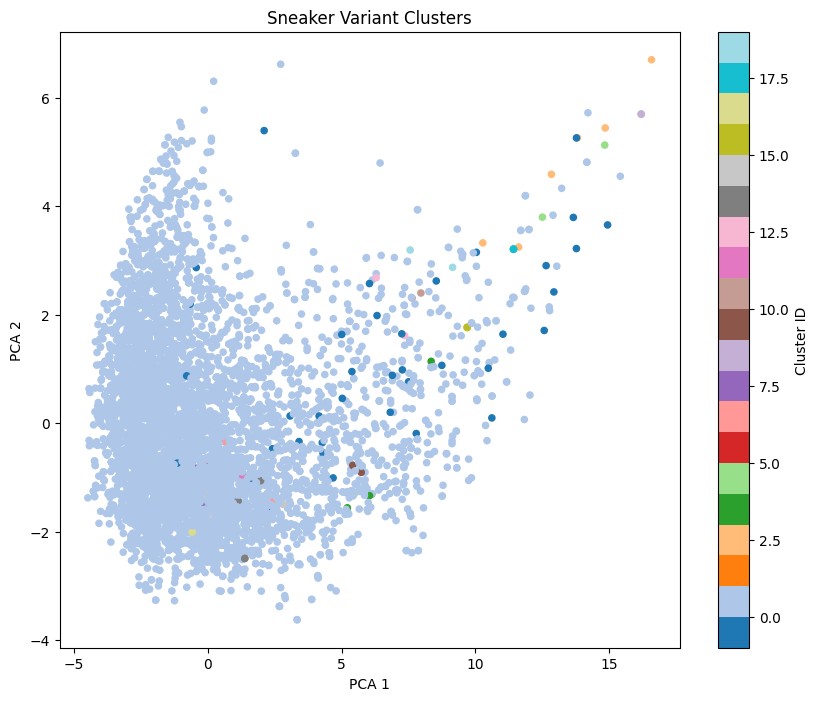

In [69]:
# Reduce similarity to distance
distance_matrix = 1 - combined_sim

# Use PCA
pca = PCA(n_components=2)
X_pca = pca.fit_transform(distance_matrix)

# Plot
plt.figure(figsize=(10, 8))
plt.scatter(X_pca[:, 0], X_pca[:, 1], c=df_filtered['approach2'], cmap='tab20', s=20)
plt.title("Sneaker Variant Clusters")
plt.xlabel("PCA 1")
plt.ylabel("PCA 2")
plt.colorbar(label="Cluster ID")
plt.show()

### **Evaluate clustering for eps = 0.5**

Compute **Silhouette score**:

In [70]:
# extract labels
labels = df_filtered['approach2'].to_numpy()

# Remove noise points (products that have not been clustered)
mask = labels != -1

# Ensure diagonal is zero for silhouette computation
np.fill_diagonal(combined_dist, 0)

if mask.sum() > 1:
    score = silhouette_score(combined_dist[mask][:, mask], labels[mask], metric='precomputed')
    print("Silhouette Score (no noise):", round(score, 4))
else:
    print("Not enough clustered points to compute silhouette score.")

Silhouette Score (no noise): -0.049


Not a good clustering. Now evaluate using a labeled sample of the dataset:

Evaluate on **labeled sample**:

In [71]:
sample_df.columns

Index(['EAN', 'size', 'brand', 'color', 'category', 'heelType', 'shoeType',
       'shoeWidth', 'heelHeight', 'returnable', 'name [el_CY]', 'name [en_GB]',
       'updateOnDelta', 'refinementColor', 'variantGroupCode',
       'jiniusSkuMatchCode', 'longDescription [el_CY]',
       'shortDescription [en_GB]', 'mainImage.source',
       'mainImage.original_url', 'shortDescription [el_CY]',
       'secondary_image_1.source', 'secondary_image_1.original_url',
       'secondary_image_2.source', 'secondary_image_2.original_url',
       'secondary_image_3.source', 'secondary_image_3.original_url',
       'longDescription [en_GB]', 'fashionMaterial', 'name', 'longDescription',
       'shortDescription', 'mirakl_product_id', 'group_id1', 'name [en_GB',
       'group_id2', 'final_group_id', 'final_group_id_clip_strict',
       'manual_group_id', 'manual_group_name'],
      dtype='object')

In [72]:
sample_df['manual_group_id'].value_counts()

manual_group_id
148.0    14
233.0    11
7.0      10
88.0      9
25.0      8
         ..
352.0     1
91.0      1
2.0       1
92.0      1
609.0     1
Name: count, Length: 609, dtype: int64

In [73]:
# Load CLIP image embeddings of the sample
clip_embeddings = np.load("clip_embeddings.npy")

# Load product IDs of the sample
clip_ids = pd.read_csv("clip_ids.csv")["mirakl_product_id"].tolist()

# Step 1: Structured features
structured_features = sample_df[['brand', 'color', 'shoeType']].fillna('').astype(str).agg(' '.join, axis=1)
structured_vec = TfidfVectorizer().fit_transform(structured_features)
structured_sim_matrix = cosine_similarity(structured_vec)

# Step 2: Text similarity from product name
sample_df['product_name'] = sample_df['name [en_GB]'].fillna('').astype(str)
tfidf_matrix = TfidfVectorizer(stop_words='english').fit_transform(sample_df['product_name'])
text_sim_matrix = cosine_similarity(tfidf_matrix)

# Step 3: Load and align image features
clip_embeddings = np.load("clip_embeddings.npy")
clip_ids = pd.read_csv("clip_ids.csv")["mirakl_product_id"].tolist()

# Ensure alignment between sample_df and clip_embeddings
# Step 3a: Create index mapping
id_to_idx = {pid: i for i, pid in enumerate(clip_ids)}
sample_indices = sample_df['mirakl_product_id'].map(id_to_idx)

# Step 3b: Filter invalid ones (just in case)
valid_mask = sample_indices.notna()
sample_df = sample_df[valid_mask].reset_index(drop=True)
sample_indices = sample_indices[valid_mask].astype(int).tolist()

# Step 3c: Subset the image features
image_features_subset = clip_embeddings[sample_indices]
image_sim_matrix = cosine_similarity(image_features_subset)

# Step 4: Combine similarities
combined_sim = (
    0.4 * text_sim_matrix +
    0.5 * image_sim_matrix +
    0.1 * structured_sim_matrix
)
combined_sim = np.clip(combined_sim, 0, 1)
combined_dist = 1 - combined_sim

# Step 5: DBSCAN
clustering = DBSCAN(eps=0.5, min_samples=2, metric='precomputed')
labels = clustering.fit_predict(combined_dist)

# Step 6: Store result
sample_df['sample_group_id'] = labels

In [74]:
# Compute the pairwise confusion matrix
conf_matrix = pair_confusion_matrix(sample_df['manual_group_id'], sample_df['sample_group_id'])

TP = conf_matrix[1, 1]
FP = conf_matrix[0, 1]
FN = conf_matrix[1, 0]
TN = conf_matrix[0, 0]

# Micro-average precision
micro_precision = TP / (TP + FP) if (TP + FP) > 0 else 0.0

# Micro-average accuracy (pairwise)
micro_accuracy = (TP + TN) / (TP + FP + FN + TN)

print(f"Micro-average Precision: {micro_precision:.4f}")
print(f"Micro-average Accuracy: {micro_accuracy:.4f}")

Micro-average Precision: 0.0017
Micro-average Accuracy: 0.0433


**Not a good performance. We should try other parameter settings.**

Save the groups created:

In [75]:
# Merge merchant info
merchant_map = df_sources.set_index("mirakl_product_id")["provider_code"].to_dict()

# Cleaned JSON
variant_groups = {}
for group_id in df_filtered["approach2"].unique():
    if group_id == -1:
        continue  # skip noise
    group = df_filtered[df_filtered["approach2"] == group_id]
    first = group.iloc[0]
    group_json = {
        "model_name": first["product_name"],
        "brand": first["brand"],
        "variants": [],
        "offers": []
    }
    seen = set()
    for _, row in group.iterrows():
        variant_key = (row["color"], row["size"])
        if variant_key not in seen:
            seen.add(variant_key)
            group_json["variants"].append({
                "color": row["color"],
                "size": row["size"],
                "image": row.get("mainImage.original_url", ""),
                "task1_approach1": row["task1_approach1"]
            })
        group_json["offers"].append({
            "merchant": merchant_map.get(row["task1_approach1"], "unknown"),
            "product_sku": row.get("product_sku", ""),
            "task1_approach1": row["task1_approach1"]
        })
    variant_groups[str(group_id)] = group_json

# Save result
with open("variant_groups_cleaned.json", "w") as f:
    json.dump(variant_groups, f, indent=2)

In [76]:
with open("variant_groups.json", "r") as f:
    data = json.load(f)

# Preview the first group
first_key = list(data.keys())[0]
print(json.dumps(data[first_key], indent=2))

{
  "model_name": "Gel-rocket 11 mens volleyball/indoor shoes",
  "brand": "ASICS",
  "variants": [
    {
      "color": "White / Black",
      "size": "44",
      "image": "https://administrator.athlokinisi.com.cy/product_catalog/groups/162995/1071a091-101.jpg",
      "product_group_id": 1041.0
    },
    {
      "color": "Black",
      "size": "44",
      "image": "https://privesports.com.cy/product_catalog/groups/66610/vn0a3mtjt2j1-black.jpg",
      "product_group_id": 4423.0
    },
    {
      "color": NaN,
      "size": "44.5",
      "image": "https://jinius-prod.mirakl.net/mmp/media/product-media/34383/IH6003-1.jpg",
      "product_group_id": NaN
    },
    {
      "color": "White / Black / Volt",
      "size": "42",
      "image": "https://administrator.athlokinisi.com.cy/product_catalog/groups/164557/ct2927-100.jpg",
      "product_group_id": 2839.0
    },
    {
      "color": "Black/white",
      "size": "11/EU 46",
      "image": "https://s3.gy.digital/famousports/uploads/ass

### Try to find a better clustering

**Try other similarity weights**

In [77]:
def try_similarity_weights(text_sim, image_sim, structured_sim, df, eps=0.5, min_samples=2):
    best_config = None
    results = []
    for text_w in [0.2, 0.3, 0.4]:
        for img_w in [0.4, 0.5, 0.6]:
            struc_w = 1.0 - text_w - img_w
            if struc_w < 0: continue
            combined_sim = (
                text_w * text_sim +
                img_w * image_sim +
                struc_w * structured_sim
            )
            combined_sim = np.clip(combined_sim, 0, 1)
            dist = 1 - combined_sim
            labels = DBSCAN(eps=eps, min_samples=min_samples, metric='precomputed').fit_predict(dist)
            n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
            n_noise = sum(labels == -1)
            results.append((text_w, img_w, struc_w, n_clusters, n_noise))
            print(f"Text: {text_w:.1f}, Image: {img_w:.1f}, Structured: {struc_w:.1f} => Clusters: {n_clusters}, Noise: {n_noise}")
    return results

In [78]:
try_similarity_weights(text_sim_matrix, image_sim_matrix, structured_sim_matrix, df_filtered)

Text: 0.2, Image: 0.4, Structured: 0.4 => Clusters: 9, Noise: 20
Text: 0.2, Image: 0.5, Structured: 0.3 => Clusters: 1, Noise: 5
Text: 0.2, Image: 0.6, Structured: 0.2 => Clusters: 1, Noise: 0
Text: 0.3, Image: 0.4, Structured: 0.3 => Clusters: 14, Noise: 25
Text: 0.3, Image: 0.5, Structured: 0.2 => Clusters: 1, Noise: 6
Text: 0.3, Image: 0.6, Structured: 0.1 => Clusters: 1, Noise: 0
Text: 0.4, Image: 0.4, Structured: 0.2 => Clusters: 20, Noise: 41
Text: 0.4, Image: 0.5, Structured: 0.1 => Clusters: 5, Noise: 12
Text: 0.4, Image: 0.6, Structured: 0.0 => Clusters: 1, Noise: 0


[(0.2, 0.4, 0.4, 9, 20),
 (0.2, 0.5, 0.30000000000000004, 1, 5),
 (0.2, 0.6, 0.20000000000000007, 1, 0),
 (0.3, 0.4, 0.29999999999999993, 14, 25),
 (0.3, 0.5, 0.19999999999999996, 1, 6),
 (0.3, 0.6, 0.09999999999999998, 1, 0),
 (0.4, 0.4, 0.19999999999999996, 20, 41),
 (0.4, 0.5, 0.09999999999999998, 5, 12),
 (0.4, 0.6, 0.0, 1, 0)]

In [79]:
print("text_sim_matrix shape:", text_sim_matrix.shape)
print("image_sim_matrix shape:", image_sim_matrix.shape)
print("structured_sim_matrix shape:", structured_sim_matrix.shape)

text_sim_matrix shape: (947, 947)
image_sim_matrix shape: (947, 947)
structured_sim_matrix shape: (947, 947)


### **Evaluate for the above weight combinations and eps = 0.5**

In [80]:
results = []

for text_w in [0.2, 0.3, 0.4]:
    for img_w in [0.4, 0.5, 0.6]:
        struc_w = 1.0 - text_w - img_w
        if struc_w < 0:
            continue

        # Combine similarities
        combined_sim = (
            text_w * text_sim_matrix +
            img_w * image_sim_matrix +
            struc_w * structured_sim_matrix
        )
        combined_sim = np.clip(combined_sim, 0, 1)
        combined_dist = 1 - combined_sim

        # DBSCAN clustering
        clustering = DBSCAN(eps=0.5, min_samples=2, metric='precomputed')
        labels = clustering.fit_predict(combined_dist)

        # Evaluate against manual_group_id
        conf_matrix = pair_confusion_matrix(sample_df['manual_group_id'], labels)
        TP = conf_matrix[1, 1]
        FP = conf_matrix[0, 1]
        FN = conf_matrix[1, 0]
        TN = conf_matrix[0, 0]

        micro_precision = TP / (TP + FP) if (TP + FP) > 0 else 0.0
        micro_accuracy = (TP + TN) / (TP + FP + FN + TN)

        results.append({
            'text_w': text_w,
            'img_w': img_w,
            'struc_w': struc_w,
            'micro_precision': micro_precision,
            'micro_accuracy': micro_accuracy,
            'n_clusters': len(set(labels)) - (1 if -1 in labels else 0),
            'n_noise': np.sum(np.array(labels) == -1)
        })

# Show results as a sorted DataFrame
results_df = pd.DataFrame(results).sort_values(by='micro_precision', ascending=False)
display(results_df) 

,text_w,img_w,struc_w,micro_precision,micro_accuracy,n_clusters,n_noise
6,0.4,0.4,0.2,0.002270,0.271073,20,41
3,0.3,0.4,0.3,0.002030,0.183372,14,25
0,0.2,0.4,0.4,0.001840,0.103958,9,20
7,0.4,0.5,0.1,0.001742,0.043328,5,12
4,0.3,0.5,0.2,0.001691,0.014275,1,6
1,0.2,0.5,0.3,0.001688,0.012185,1,5
2,0.2,0.6,0.2,0.001670,0.001670,1,0
5,0.3,0.6,0.1,0.001670,0.001670,1,0
8,0.4,0.6,0.0,0.001670,0.001670,1,0


We observe that none of the above combinations gives an acceptable micro-average precision. Following we explore multiple values for **eps** parameter and evaluate each clustering on the labeled sample.

### Try multiple eps values

In [81]:
image_features = np.load("image_features.npy")

# Structured similarity
structured_features = df_filtered[['brand', 'color', 'shoeType']].fillna('').astype(str).agg(' '.join, axis=1)
structured_vec = TfidfVectorizer().fit_transform(structured_features)
structured_sim_matrix = cosine_similarity(structured_vec)

# Text similarity
df_filtered['product_name'] = df_filtered['name [en_GB]'].fillna('').astype(str)
tfidf_matrix = TfidfVectorizer(stop_words='english').fit_transform(df_filtered['product_name'])
text_sim_matrix = cosine_similarity(tfidf_matrix)

# Image similarity
image_sim_matrix = cosine_similarity(image_features)

# Combined similarity (fixed weights)
combined_sim = (
    0.4 * text_sim_matrix +
    0.5 * image_sim_matrix +
    0.1 * structured_sim_matrix
)
combined_sim = np.clip(combined_sim, 0, 1)
combined_dist = 1 - combined_sim

# --- Loop over different eps values ---
eps_values = [0.001, 0.002, 0.005, 0.01, 0.15, 0.2, 0.25, 0.3]
cluster_results = {}

for eps in eps_values:
    clustering = DBSCAN(eps=eps, min_samples=2, metric='precomputed')
    labels = clustering.fit_predict(combined_dist)

    # Store results in new column
    col_name = f'approach2_eps{str(eps).replace(".", "_")}'
    df_filtered[col_name] = labels

    # Optional: store summary stats
    n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
    n_noise = np.sum(np.array(labels) == -1)
    cluster_results[eps] = {'n_clusters': n_clusters, 'n_noise': n_noise}

# Show summary
summary_df = pd.DataFrame.from_dict(cluster_results, orient='index').sort_index()
print(summary_df)

       n_clusters  n_noise
0.001         929     3636
0.002         929     3636
0.005         931     3627
0.010         941     3602
0.150        1003     1729
0.200         894     1285
0.250         760      946
0.300         600      665


### Evaluate on sample

In [82]:
# --- Step 1: Align image features to sample_df ---
clip_embeddings = np.load("clip_embeddings.npy")
clip_ids = pd.read_csv("clip_ids.csv")["mirakl_product_id"].tolist()
id_to_idx = {pid: i for i, pid in enumerate(clip_ids)}
sample_indices = sample_df['mirakl_product_id'].map(id_to_idx)

# Keep only valid matches
valid_mask = sample_indices.notna()
sample_df = sample_df[valid_mask].reset_index(drop=True)
sample_indices = sample_indices[valid_mask].astype(int).tolist()
image_features_subset = clip_embeddings[sample_indices]

# --- Step 2: Similarity matrices ---

# Structured similarity
structured_features = sample_df[['brand', 'color', 'shoeType']].fillna('').astype(str).agg(' '.join, axis=1)
structured_vec = TfidfVectorizer().fit_transform(structured_features)
structured_sim_matrix = cosine_similarity(structured_vec)

# Text similarity
sample_df['product_name'] = sample_df['name [en_GB]'].fillna('').astype(str)
tfidf_matrix = TfidfVectorizer(stop_words='english').fit_transform(sample_df['product_name'])
text_sim_matrix = cosine_similarity(tfidf_matrix)

# Image similarity
image_sim_matrix = cosine_similarity(image_features_subset)

# Combined similarity (fixed weights)
combined_sim = (
    0.4 * text_sim_matrix +
    0.5 * image_sim_matrix +
    0.1 * structured_sim_matrix
)
combined_sim = np.clip(combined_sim, 0, 1)
combined_dist = 1 - combined_sim

# --- Step 3: Loop over eps values and evaluate ---
eps_values = [0.001, 0.002, 0.005, 0.01, 0.15, 0.2, 0.25, 0.3]
results = []

for eps in eps_values:
    clustering = DBSCAN(eps=eps, min_samples=2, metric='precomputed')
    labels = clustering.fit_predict(combined_dist)

    # Compute micro-average precision & accuracy
    conf_matrix = pair_confusion_matrix(sample_df['manual_group_id'], labels)
    TP = conf_matrix[1, 1]
    FP = conf_matrix[0, 1]
    FN = conf_matrix[1, 0]
    TN = conf_matrix[0, 0]

    micro_precision = TP / (TP + FP) if (TP + FP) > 0 else 0.0
    micro_accuracy = (TP + TN) / (TP + FP + FN + TN)

    results.append({
        'eps': eps,
        'micro_precision': micro_precision,
        'micro_accuracy': micro_accuracy,
        'n_clusters': len(set(labels)) - (1 if -1 in labels else 0),
        'n_noise': np.sum(np.array(labels) == -1)
    })

# Display results
results_df = pd.DataFrame(results).sort_values(by='micro_precision', ascending=False)
display(results_df)

,eps,micro_precision,micro_accuracy,n_clusters,n_noise
7,0.300,0.014372,0.898757,151,293
6,0.250,0.006849,0.808645,157,412
5,0.200,0.003798,0.706060,146,513
4,0.150,0.002631,0.589033,128,607
0,0.001,0.001631,0.114000,27,892
1,0.002,0.001631,0.114000,27,892
2,0.005,0.001631,0.114000,27,892
3,0.010,0.001629,0.119931,28,889


**Although micro-average accuracy is quite high, micro-average precision is still very low. This is due to accuracy considering also the TN and FN instances. Other approaches should be exlored.**

### Alternative: HDBSCAN instead of DBSCAN

In [83]:
# Re-define HDBSCAN visual tuning function
def try_similarity_weights_hdbscan_with_visuals(text_sim, image_sim, structured_sim, df, min_cluster_size=3, min_samples=2):
    results = []
    for text_w in [0.2, 0.3, 0.4]:
        for img_w in [0.4, 0.5, 0.6]:
            struc_w = 1.0 - text_w - img_w
            if struc_w < 0:
                continue
            combined_sim = (
                text_w * text_sim +
                img_w * image_sim +
                struc_w * structured_sim
            )
            combined_sim = np.clip(combined_sim, 0, 1)
            combined_dist = 1 - combined_sim

            # Run HDBSCAN
            clusterer = hdbscan.HDBSCAN(min_cluster_size=min_cluster_size,
                                        min_samples=min_samples,
                                        metric='precomputed')
            labels = clusterer.fit_predict(combined_dist)
            n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
            n_noise = sum(labels == -1)
            print(f"Text: {text_w:.1f}, Image: {img_w:.1f}, Structured: {struc_w:.1f} → Clusters: {n_clusters}, Noise: {n_noise}")

            # PCA for visualization
            pca = PCA(n_components=2)
            pca_features = pca.fit_transform(combined_sim)
            plt.figure(figsize=(6, 5))
            plt.scatter(pca_features[:, 0], pca_features[:, 1], c=labels, cmap='tab20', s=10)
            plt.title(f"HDBSCAN: T:{text_w}, I:{img_w}, S:{struc_w}\nClusters={n_clusters}, Noise={n_noise}")
            plt.xlabel("PCA 1")
            plt.ylabel("PCA 2")
            plt.colorbar(label="Cluster ID")
            plt.tight_layout()
            plt.show()

            results.append({
                "text_weight": text_w,
                "image_weight": img_w,
                "structured_weight": struc_w,
                "n_clusters": n_clusters,
                "n_noise": n_noise,
                "labels": labels
            })
    #return results

Text: 0.2, Image: 0.4, Structured: 0.4 → Clusters: 46, Noise: 302


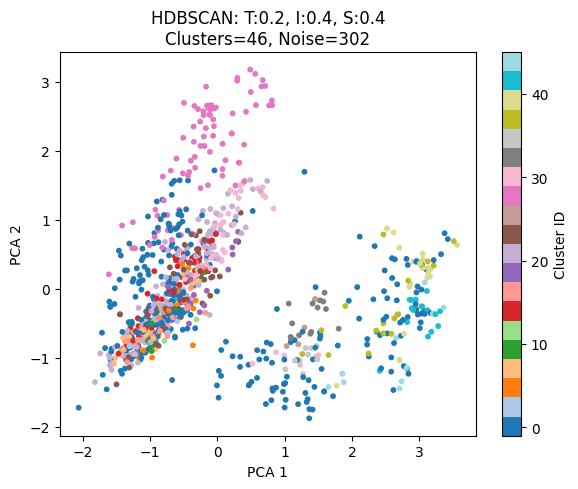

Text: 0.2, Image: 0.5, Structured: 0.3 → Clusters: 38, Noise: 311


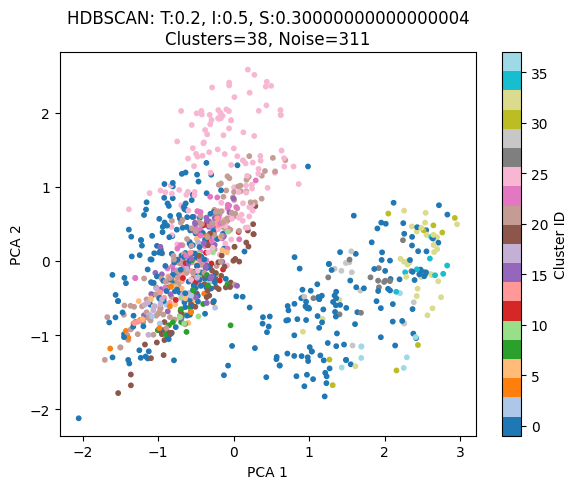

Text: 0.2, Image: 0.6, Structured: 0.2 → Clusters: 49, Noise: 317


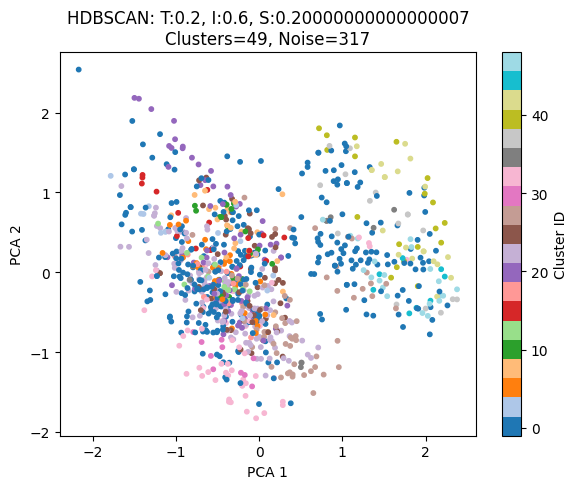

Text: 0.3, Image: 0.4, Structured: 0.3 → Clusters: 47, Noise: 329


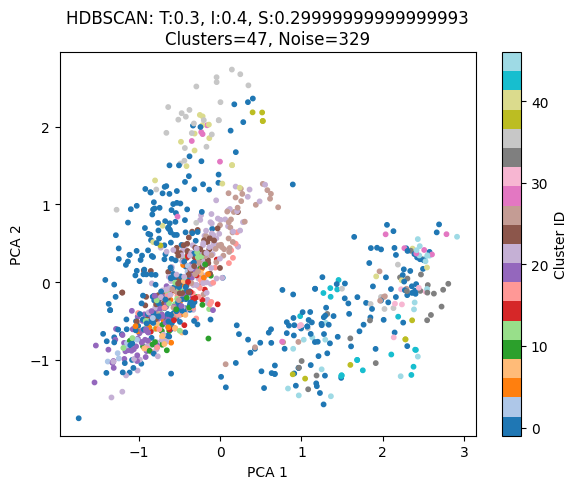

Text: 0.3, Image: 0.5, Structured: 0.2 → Clusters: 60, Noise: 368


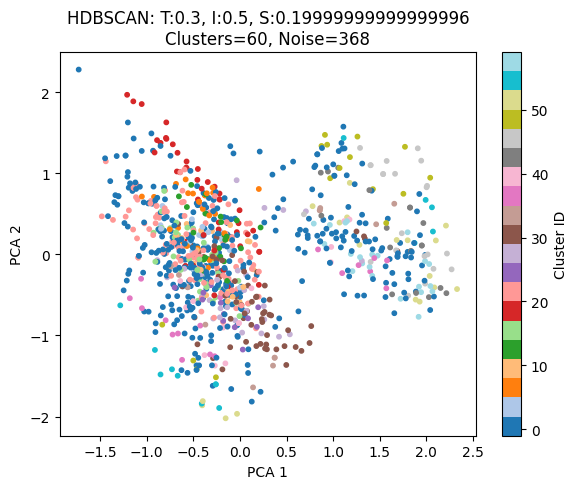

Text: 0.3, Image: 0.6, Structured: 0.1 → Clusters: 71, Noise: 362


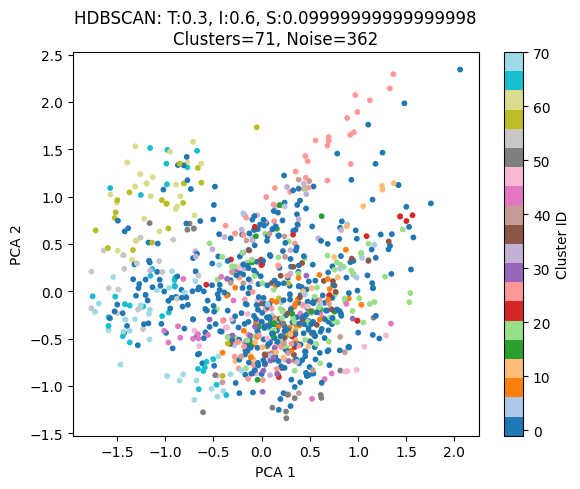

Text: 0.4, Image: 0.4, Structured: 0.2 → Clusters: 65, Noise: 356


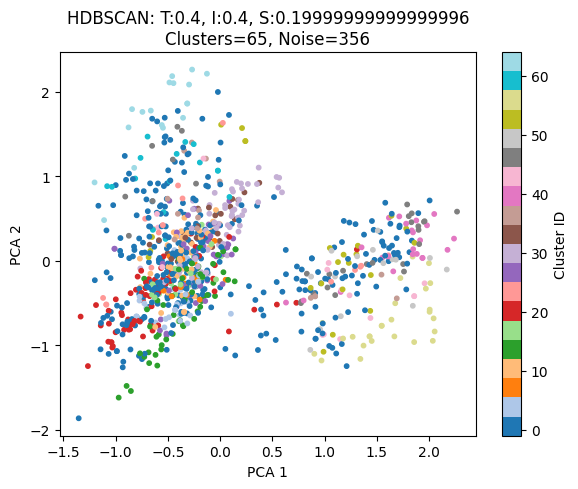

Text: 0.4, Image: 0.5, Structured: 0.1 → Clusters: 70, Noise: 380


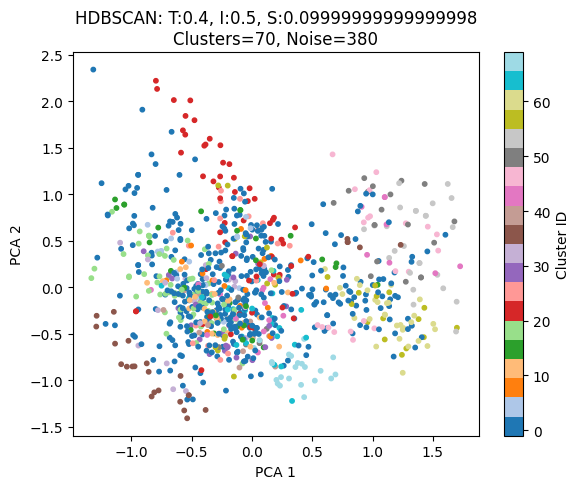

Text: 0.4, Image: 0.6, Structured: 0.0 → Clusters: 74, Noise: 433


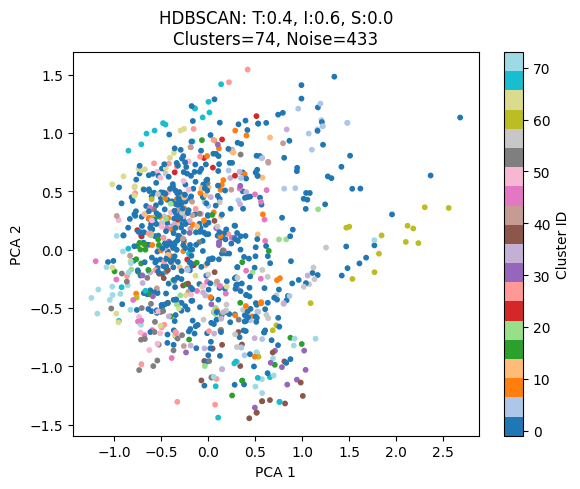

In [84]:
try_similarity_weights_hdbscan_with_visuals(
    text_sim_matrix,
    image_sim_matrix,
    structured_sim_matrix,
    df_filtered,
    min_cluster_size=4,
    min_samples=2)

### Evaluate on sample

In [85]:
results = []

# Set weights to loop over
text_weights = [0.2, 0.3, 0.4]
image_weights = [0.4, 0.5, 0.6]

# Manual labels
y_true = sample_df['manual_group_id'].values

for text_w in text_weights:
    for image_w in image_weights:
        struct_w = 1.0 - text_w - image_w
        if struct_w < 0:
            continue

        # Combine similarity matrices
        combined_sim = (
            text_w * text_sim_matrix +
            image_w * image_sim_matrix +
            struct_w * structured_sim_matrix
        )
        combined_sim = np.clip(combined_sim, 0, 1)
        combined_dist = 1 - combined_sim

        # Run HDBSCAN
        clusterer = hdbscan.HDBSCAN(min_cluster_size=4, min_samples=2, metric='precomputed')
        labels = clusterer.fit_predict(combined_dist)

        # Evaluate
        conf_matrix = pair_confusion_matrix(y_true, labels)
        TP = conf_matrix[1, 1]
        FP = conf_matrix[0, 1]
        FN = conf_matrix[1, 0]
        TN = conf_matrix[0, 0]

        micro_precision = TP / (TP + FP) if (TP + FP) > 0 else 0.0
        micro_accuracy = (TP + TN) / (TP + FP + FN + TN)
        n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
        n_noise = np.sum(labels == -1)

        results.append({
            'text_weight': text_w,
            'image_weight': image_w,
            'structured_weight': struct_w,
            'micro_precision': micro_precision,
            'micro_accuracy': micro_accuracy,
            'n_clusters': n_clusters,
            'n_noise': n_noise
        })

# Show results sorted by precision
results_df = pd.DataFrame(results).sort_values(by='micro_precision', ascending=False)
print(results_df)

   text_weight  image_weight  structured_weight  micro_precision  \
2          0.2           0.6                0.2         0.011026   
3          0.3           0.4                0.3         0.010327   
0          0.2           0.4                0.4         0.010086   
5          0.3           0.6                0.1         0.010024   
1          0.2           0.5                0.3         0.009887   
6          0.4           0.4                0.2         0.009864   
7          0.4           0.5                0.1         0.009473   
4          0.3           0.5                0.2         0.009089   
8          0.4           0.6                0.0         0.006704   

   micro_accuracy  n_clusters  n_noise  
2        0.869625          49      317  
3        0.860295          47      329  
0        0.874925          46      302  
5        0.845996          71      362  
1        0.866633          38      311  
6        0.847914          65      356  
7        0.832104          70   

### **Approach 3:** Cluster using only the image embeddings

**Trying multiple eps values**

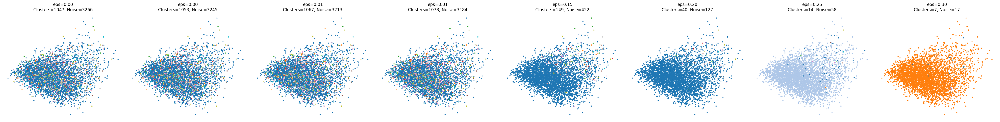

In [86]:
# Reduce dimensions using PCA for visualization
def reduce_with_pca(features, n_components=2):
    pca = PCA(n_components=n_components)
    return pca.fit_transform(features)

# Run DBSCAN at multiple eps values, store results
def run_dbscan_varying_eps(image_features, eps_values):
    reduced_features = reduce_with_pca(image_features, n_components=2)
    all_results = []

    fig, axs = plt.subplots(1, len(eps_values), figsize=(5 * len(eps_values), 5))
    if len(eps_values) == 1:
        axs = [axs]

    for i, eps in enumerate(eps_values):
        db = DBSCAN(eps=eps, min_samples=2, metric='cosine')
        labels = db.fit_predict(image_features)
        n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
        n_noise = sum(labels == -1)

        axs[i].scatter(reduced_features[:, 0], reduced_features[:, 1], c=labels, cmap='tab20', s=5)
        axs[i].set_title(f"eps={eps:.2f}\nClusters={n_clusters}, Noise={n_noise}")
        axs[i].axis('off')

        all_results.append({
            'eps': eps,
            'labels': labels,
            'n_clusters': n_clusters,
            'n_noise': n_noise
        })

    plt.tight_layout()
    plt.show()
    return all_results

image_features = np.load("image_features.npy")
results = run_dbscan_varying_eps(image_features, [0.001, 0.002, 0.005, 0.01, 0.15, 0.2, 0.25, 0.3])

For these clusterings we will compute the **Silhouette score**

In [87]:
#compute silhouette for the above clusterings
for res in results:
    labels = res['labels']
    eps = res['eps']
    mask = labels != -1

    if len(set(labels[mask])) < 2:
        print(f"eps={eps:.4f}: Only one cluster (or none) after removing noise. Cannot compute silhouette.")
        continue

    # Compute Silhouette Score using cosine distance on valid points only
    try:
        score = silhouette_score(
            image_features[mask], 
            labels[mask], 
            metric='cosine'
        )
        print(f"eps={eps:.4f}: Clusters={res['n_clusters']}, Noise={res['n_noise']}, Silhouette={score:.4f}")

    except Exception as e:
        print(f"eps={eps:.4f}: Error computing silhouette - {e}")

eps=0.0010: Clusters=1047, Noise=3266, Silhouette=0.9999
eps=0.0020: Clusters=1053, Noise=3245, Silhouette=0.9996
eps=0.0050: Clusters=1067, Noise=3213, Silhouette=0.9989
eps=0.0100: Clusters=1078, Noise=3184, Silhouette=0.9968
eps=0.1500: Clusters=149, Noise=422, Silhouette=-0.0884
eps=0.2000: Clusters=40, Noise=127, Silhouette=0.0816
eps=0.2500: Clusters=14, Noise=58, Silhouette=0.2422
eps=0.3000: Clusters=7, Noise=17, Silhouette=0.4852


We observe that lowering epsilon produces very high Silhouette scores (almost 1). However the noise is high, meaning that multiple products have not been grouped. Following we print the images of the products of a few clusters, for visual inspection and we evaluate on the annotated sample.

### **Evaluate on sample**

In [88]:
# Load CLIP image embeddings and product IDs
clip_embeddings = np.load("clip_embeddings.npy")
clip_ids = pd.read_csv("clip_ids.csv")["mirakl_product_id"].tolist()

# Align embeddings to sample_df
id_to_idx = {pid: i for i, pid in enumerate(clip_ids)}
sample_indices = sample_df['mirakl_product_id'].map(id_to_idx)

# Filter valid entries
valid_mask = sample_indices.notna()
sample_df = sample_df[valid_mask].reset_index(drop=True)
sample_indices = sample_indices[valid_mask].astype(int).tolist()
image_features = clip_embeddings[sample_indices]
manual_group_ids = sample_df['manual_group_id'].values

# Eps values to try
eps_values = [0.001, 0.002, 0.005, 0.01, 0.15, 0.2, 0.25, 0.3]
results2 = []

for eps in eps_values:
    db = DBSCAN(eps=eps, min_samples=2, metric='cosine')
    labels = db.fit_predict(image_features)

    # Pairwise micro-average precision & accuracy
    conf_matrix = pair_confusion_matrix(manual_group_ids, labels)
    TP = conf_matrix[1, 1]
    FP = conf_matrix[0, 1]
    FN = conf_matrix[1, 0]
    TN = conf_matrix[0, 0]

    micro_precision = TP / (TP + FP) if (TP + FP) > 0 else 0.0
    micro_accuracy = (TP + TN) / (TP + FP + FN + TN)

    results2.append({
        'eps': eps,
        'micro_precision': micro_precision,
        'micro_accuracy': micro_accuracy,
        'n_clusters': len(set(labels)) - (1 if -1 in labels else 0),
        'n_noise': np.sum(np.array(labels) == -1)
    })

# Create and display result table
results2_df = pd.DataFrame(results2).sort_values(by='micro_precision', ascending=False)
print(results2_df)

     eps  micro_precision  micro_accuracy  n_clusters  n_noise
4  0.150         0.001708        0.026754           2       10
5  0.200         0.001673        0.003782           1        1
6  0.250         0.001670        0.001670           1        0
7  0.300         0.001670        0.001670           1        0
2  0.005         0.001628        0.155138          37      871
3  0.010         0.001628        0.155138          37      871
0  0.001         0.001626        0.151258          36      873
1  0.002         0.001626        0.151258          36      873


### Visualizing some clusters for inspection

In [89]:
# For a specific eps, print the images of some products in the same cluster, for visual inspection
target_eps = 0.001
result = next(res for res in results if abs(res['eps'] - target_eps) < 1e-6)

labels_eps = result['labels']
df_filtered['cluster_label'] = labels_eps

# Exclude noise (-1)
valid_clusters = sorted(c for c in set(labels_eps) if c != -1)

# Take first 5 clusters
selected_clusters = valid_clusters[:10]

print(f"Selected clusters for visualization: {selected_clusters}")

Selected clusters for visualization: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]


In [90]:
# function to visualise these clusters as HTML
def show_clusters_as_html(df, cluster_ids):
    for cluster_id in cluster_ids:
        cluster_df = df[df['cluster_label'] == cluster_id]
        if cluster_df.empty:
            print(f"Cluster {cluster_id} is empty!")
            continue

        html = f"<h3 style='margin-top:20px'>Cluster {cluster_id} ({len(cluster_df)} items)</h3>"
        html += "<div style='display:flex;flex-wrap:wrap'>"

        for _, row in cluster_df.iterrows():
            name = row.get('product_name', '')
            
            # Choose the best available image
            for col in [
                'mainImage.original_url',
                'secondary_image_1.original_url',
                'secondary_image_2.original_url',
                'secondary_image_3.original_url'
            ]:
                img = row.get(col, '')
                if isinstance(img, str) and img.startswith('http'):
                    break
            else:
                img = ''
            
            html += f"""
                <div style='margin:10px;text-align:center'>
                    <img src='{img}' width='120' style='border-radius:8px'><br>
                    <div style='max-width:120px;font-size:12px'>{name}</div>
                </div>
            """
        html += "</div>"
        display(HTML(html))

In [91]:
show_clusters_as_html(df_filtered, selected_clusters)

From the images of the first 10 clusters, we observe that the products are indeed identical. As an additional inspection to check if the groups include different products, in the following code I extract the largest cluster that was created and print the images of its products:

In [92]:
#find the sizes of the clusters
non_noise = df_filtered[df_filtered['cluster_label'] != -1]
cluster_counts = non_noise['cluster_label'].value_counts()

print(cluster_counts)

biggest_cluster_label = cluster_counts.idxmax()
biggest_cluster_size = cluster_counts.max()

print(f"Biggest cluster label: {biggest_cluster_label}")
print(f"Size of biggest cluster: {biggest_cluster_size}")

cluster_label
547     7
9       7
495     6
670     6
510     6
       ..
392     2
393     2
394     2
395     2
1046    2
Name: count, Length: 1047, dtype: int64
Biggest cluster label: 547
Size of biggest cluster: 7


In [93]:
show_clusters_as_html(df_filtered, [biggest_cluster_label])

We observe that the products of the biggest cluster are indeed identical. However visual inspection is not an appropriate way to evaluate the clusterings (e.g. there might be multiple clusters that have *Adidas Campus 00s* which is not desirable) We also observe that some identical products have different names. 

### Alternative: Using PCA on images before clustering to reduce noise

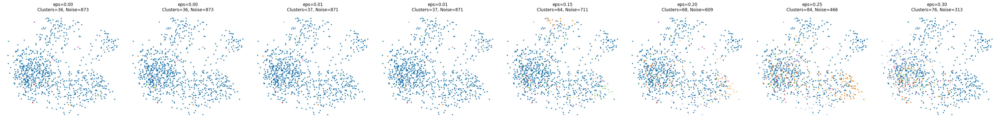

In [94]:
#same thing as before but using pca on images before dbscan to reduce noise
pca = PCA(n_components=50)
image_pca = pca.fit_transform(image_features)

# Reduce dimensions using PCA for visualization
def reduce_with_pca(features, n_components=2):
    pca = PCA(n_components=n_components)
    return pca.fit_transform(features)

# Run DBSCAN at multiple eps values, store results but now on Images reduced using PCA!
def run_dbscan_varying_eps(image_features, eps_values):
    reduced_features = reduce_with_pca(image_features, n_components=2)
    all_results = []

    fig, axs = plt.subplots(1, len(eps_values), figsize=(5 * len(eps_values), 5))
    if len(eps_values) == 1:
        axs = [axs]

    for i, eps in enumerate(eps_values):
        db = DBSCAN(eps=eps, min_samples=2, metric='cosine')
        labels = db.fit_predict(image_features)
        n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
        n_noise = sum(labels == -1)

        axs[i].scatter(reduced_features[:, 0], reduced_features[:, 1], c=labels, cmap='tab20', s=5)
        axs[i].set_title(f"eps={eps:.2f}\nClusters={n_clusters}, Noise={n_noise}")
        axs[i].axis('off')

        all_results.append({
            'eps': eps,
            'labels': labels,
            'n_clusters': n_clusters,
            'n_noise': n_noise
        })

    plt.tight_layout()
    plt.show()
    return all_results

# Example call (we must define image_features beforehand or load from .npy)
image_features = np.load("image_features.npy")
#eps_values = [0.001, 0.002, 0.005, 0.01, 0.15, 0.2, 0.25, 0.3] defined earlier
results = run_dbscan_varying_eps(image_pca, eps_values)

### **Evaluate on sample**

In [95]:
# Step 1: Load and align CLIP embeddings
clip_embeddings = np.load("clip_embeddings.npy")
clip_ids = pd.read_csv("clip_ids.csv")["mirakl_product_id"].tolist()

# Align to sample_df using mirakl_product_id
id_to_idx = {pid: i for i, pid in enumerate(clip_ids)}
sample_indices = sample_df['mirakl_product_id'].map(id_to_idx)

# Filter valid entries
valid_mask = sample_indices.notna()
sample_df = sample_df[valid_mask].reset_index(drop=True)
sample_indices = sample_indices[valid_mask].astype(int).tolist()
image_features = clip_embeddings[sample_indices]

# Step 2: Reduce with PCA
pca = PCA(n_components=50)
image_pca = pca.fit_transform(image_features)

# Step 3: Get ground-truth groupings
manual_group_ids = sample_df['manual_group_id'].values

# Step 4: Run DBSCAN on PCA-reduced features for multiple eps values
#eps_values = [0.001, 0.002, 0.005, 0.01, 0.15, 0.2, 0.25, 0.3]
results = []

for eps in eps_values:
    db = DBSCAN(eps=eps, min_samples=2, metric='cosine')
    labels = db.fit_predict(image_pca)

    # Evaluate with pair confusion matrix
    conf_matrix = pair_confusion_matrix(manual_group_ids, labels)
    TP = conf_matrix[1, 1]
    FP = conf_matrix[0, 1]
    FN = conf_matrix[1, 0]
    TN = conf_matrix[0, 0]

    micro_precision = TP / (TP + FP) if (TP + FP) > 0 else 0.0
    micro_accuracy = (TP + TN) / (TP + FP + FN + TN)

    results.append({
        'eps': eps,
        'micro_precision': micro_precision,
        'micro_accuracy': micro_accuracy,
        'n_clusters': len(set(labels)) - (1 if -1 in labels else 0),
        'n_noise': np.sum(np.array(labels) == -1)
    })

# Step 5: Display results sorted by precision
results_df = pd.DataFrame(results).sort_values(by='micro_precision', ascending=False)
print(results_df)

     eps  micro_precision  micro_accuracy  n_clusters  n_noise
7  0.300         0.005114        0.789644          76      314
6  0.250         0.003616        0.735415          84      467
5  0.200         0.002382        0.574919          68      609
4  0.150         0.001901        0.433303          64      711
2  0.005         0.001628        0.155138          37      871
3  0.010         0.001628        0.155138          37      871
0  0.001         0.001626        0.151258          36      873
1  0.002         0.001626        0.151258          36      873


### Alternative: Attempting HDBSCAN instead of DBSCAN

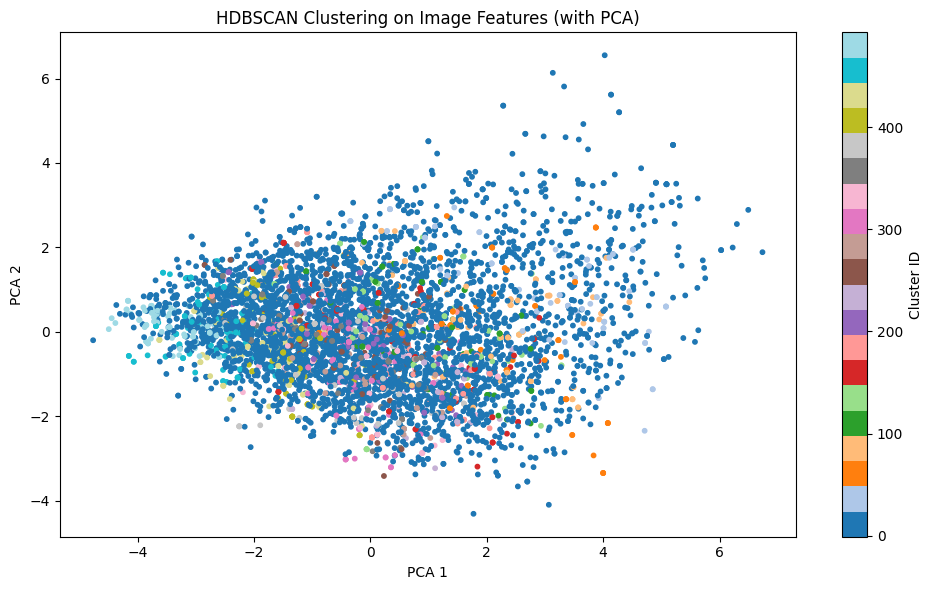

Clusters: 494, Noise Points: 3868


In [96]:
# Load image features
image_features = np.load("image_features.npy")  # adjust path as needed

# HDBSCAN clustering
clusterer = hdbscan.HDBSCAN(min_cluster_size=2, metric='euclidean')
labels = clusterer.fit_predict(image_features)

# PCA for visualization
pca = PCA(n_components=2)
pca_result = pca.fit_transform(image_features)

# Plot clusters
plt.figure(figsize=(10, 6))
plt.scatter(pca_result[:, 0], pca_result[:, 1], c=labels, cmap='tab20', s=10)
plt.title("HDBSCAN Clustering on Image Features (with PCA)")
plt.xlabel("PCA 1")
plt.ylabel("PCA 2")
plt.colorbar(label="Cluster ID")
plt.tight_layout()
plt.show()

# Summary
n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
n_noise = sum(labels == -1)
print(f"Clusters: {n_clusters}, Noise Points: {n_noise}")

We get more clusters which could be a good sign, still many noise points

### **Evaluate on sample**

In [97]:
# Step 1: Load and align CLIP embeddings
clip_embeddings = np.load("clip_embeddings.npy")
clip_ids = pd.read_csv("clip_ids.csv")["mirakl_product_id"].tolist()

# Align to sample_df
id_to_idx = {pid: i for i, pid in enumerate(clip_ids)}
sample_indices = sample_df['mirakl_product_id'].map(id_to_idx)

# Filter only valid entries
valid_mask = sample_indices.notna()
sample_df = sample_df[valid_mask].reset_index(drop=True)
sample_indices = sample_indices[valid_mask].astype(int).tolist()
image_features = clip_embeddings[sample_indices]
manual_group_ids = sample_df['manual_group_id'].values

# Step 2: HDBSCAN clustering on image features
clusterer = hdbscan.HDBSCAN(min_cluster_size=2, metric='euclidean')
labels = clusterer.fit_predict(image_features)

# Step 3: Evaluate clustering
conf_matrix = pair_confusion_matrix(manual_group_ids, labels)
TP = conf_matrix[1, 1]
FP = conf_matrix[0, 1]
FN = conf_matrix[1, 0]
TN = conf_matrix[0, 0]

micro_precision = TP / (TP + FP) if (TP + FP) > 0 else 0.0
micro_accuracy = (TP + TN) / (TP + FP + FN + TN)

# Step 4: Save labels and summary
sample_df['hdbscan_labels'] = labels
n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
n_noise = np.sum(labels == -1)

print(f"Clusters: {n_clusters}")
print(f"Noise Points: {n_noise}")
print(f"Micro-average Precision: {micro_precision:.4f}")
print(f"Micro-average Accuracy: {micro_accuracy:.4f}")

Clusters: 60
Noise Points: 603
Micro-average Precision: 0.0023
Micro-average Accuracy: 0.5841


Still very low micro-average precision.

We may also tune the alpha parameter, changing the weight of image versus metadata on the embeddings, in order to pick the best one. This code could be applied later to more elegant solutions

In [98]:
# functions that tune alpha through (grid) and visualise the results of several values of it
def try_similarity_weights_hdbscan(text_sim, image_sim, structured_sim, df, min_cluster_size=3, min_samples=2):
    results = []
    for text_w in [0.2, 0.3, 0.4]:
        for img_w in [0.4, 0.5, 0.6]:
            struc_w = 1.0 - text_w - img_w
            if struc_w < 0:
                continue
            # Combine weighted similarity matrix
            combined_sim = (
                text_w * text_sim +
                img_w * image_sim +
                struc_w * structured_sim
            )
            combined_sim = np.clip(combined_sim, 0, 1)
            combined_dist = 1 - combined_sim

            # HDBSCAN requires a condensed or full distance matrix
            clusterer = hdbscan.HDBSCAN(min_cluster_size=min_cluster_size,
                                        min_samples=min_samples,
                                        metric='precomputed')
            labels = clusterer.fit_predict(combined_dist)
            n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
            n_noise = sum(labels == -1)
            results.append((text_w, img_w, struc_w, n_clusters, n_noise))
            print(f"Text: {text_w:.1f}, Image: {img_w:.1f}, Structured: {struc_w:.1f} → Clusters: {n_clusters}, Noise: {n_noise}")
    return results

In [ ]:
###stoped here --andria

## Task 2: Match similar products with different variants

In the previous section we identified a method to cluster identical products using DBSCAN based on the similarity among products (using image features, product features, like brand, color, and product name). However the eps parameter was too small, meaning that only very similar products get clustered together (exact matches, near-duplicates). Now, we will investigate which values of eps will group variants. As a first step, we cluster using several values of eps and compute the Silhouette score on each.

In [220]:
from sklearn.cluster import DBSCAN
from sklearn.metrics import silhouette_score
import numpy as np
import pandas as pd

#define possible values of eps parameter
eps_values = np.arange(0.01, 0.51, 0.01)

results = []

for eps in eps_values:
    print(f"\nRunning DBSCAN for eps = {eps}")

    # Fit DBSCAN
    model = DBSCAN(eps=eps, min_samples=2, metric='precomputed')
    labels = model.fit_predict(combined_dist)

    # Exclude noise
    mask = labels != -1
    n_clusters = len(set(labels[mask]))

    if n_clusters < 2:
        #print(f"  Not enough clusters after noise filtering (n_clusters={n_clusters}). Skipping silhouette.")
        score = None
    else:
        # Compute silhouette (note: combined_dist is precomputed)
        np.fill_diagonal(combined_dist, 0)  # safety for silhouette_score
        try:
            score = silhouette_score(combined_dist[mask][:, mask], labels[mask], metric='precomputed')
            #print(f" Silhouette Score: {score:.4f}")
        except Exception as e:
            #print(f"  Error computing silhouette: {e}")
            score = None

    # Store results
    results.append({
        'eps': eps,
        'n_clusters': n_clusters,
        'silhouette_score': score,
        'noise_count': np.sum(labels == -1)
    })


Running DBSCAN for eps = 0.01

Running DBSCAN for eps = 0.02

Running DBSCAN for eps = 0.03

Running DBSCAN for eps = 0.04

Running DBSCAN for eps = 0.05

Running DBSCAN for eps = 0.060000000000000005

Running DBSCAN for eps = 0.06999999999999999

Running DBSCAN for eps = 0.08

Running DBSCAN for eps = 0.09

Running DBSCAN for eps = 0.09999999999999999

Running DBSCAN for eps = 0.11

Running DBSCAN for eps = 0.12

Running DBSCAN for eps = 0.13

Running DBSCAN for eps = 0.14

Running DBSCAN for eps = 0.15000000000000002

Running DBSCAN for eps = 0.16

Running DBSCAN for eps = 0.17

Running DBSCAN for eps = 0.18000000000000002

Running DBSCAN for eps = 0.19

Running DBSCAN for eps = 0.2

Running DBSCAN for eps = 0.21000000000000002

Running DBSCAN for eps = 0.22

Running DBSCAN for eps = 0.23

Running DBSCAN for eps = 0.24000000000000002

Running DBSCAN for eps = 0.25

Running DBSCAN for eps = 0.26

Running DBSCAN for eps = 0.27

Running DBSCAN for eps = 0.28

Running DBSCAN for eps = 0

In [222]:
#convert to dataframe for easier inspection
results_df = pd.DataFrame(results)
print(results_df)

     eps  n_clusters  silhouette_score  noise_count
0   0.01          28          0.998698          889
1   0.02          30          0.996469          885
2   0.03          33          0.980656          878
3   0.04          39          0.968567          864
4   0.05          45          0.943021          848
5   0.06          49          0.926639          834
6   0.07          59          0.899614          811
7   0.08          71          0.869475          783
8   0.09          83          0.844920          753
9   0.10          91          0.826481          730
10  0.11          98          0.805471          704
11  0.12         104          0.785698          679
12  0.13         117          0.762578          643
13  0.14         121          0.748148          630
14  0.15         128          0.733378          607
15  0.16         135          0.716053          586
16  0.17         138          0.701685          567
17  0.18         139          0.688664          550
18  0.19    

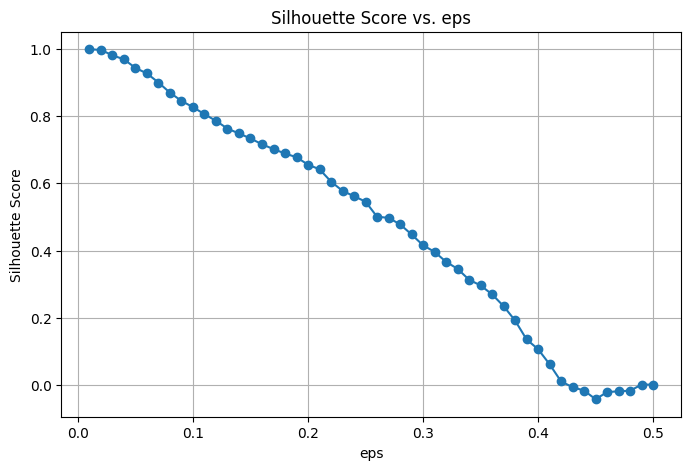

In [224]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
plt.plot(results_df['eps'], results_df['silhouette_score'], marker='o')
plt.title('Silhouette Score vs. eps')
plt.xlabel('eps')
plt.ylabel('Silhouette Score')
plt.grid(True)
plt.show()

For eps = 0.25 we observe, from the previous output, that less than 1000 of the data are noise (they were not grouped), but some of these might correspond to unique products? Try DBSCAN for this eps

In [229]:
from sklearn.cluster import DBSCAN
#arbitrarily chosen eps
chosen_eps = 0.25

dbscan_model = DBSCAN(eps=chosen_eps, min_samples=2, metric='precomputed')
labels_eps = dbscan_model.fit_predict(combined_dist)

# Assign to DataFrame
df_filtered['cluster_label'] = labels_eps

ValueError: Length of values (947) does not match length of index (5679)

In [ ]:
# Noise is labeled -1, exclude it
valid_clusters = sorted([c for c in set(labels_eps) if c != -1])

# Take the first 5
selected_clusters = valid_clusters[:10]

print(f"First 5 clusters (excluding noise): {selected_clusters}")

In [ ]:
show_clusters_as_html(df_filtered, selected_clusters, max_items=8)

We capture some variants, however we have some products that are not clustered correctly (e.g. see cluster 1)

## Task 1: Match identical products

#### **Approach 3:** Group products using image processing and descriptions

From previous EDA we observe that short descriptions in English have no missing values, while long descriptions are missing for almost all records. In this approach, we will vectorize short English descriptions and combine them with the image embeddings. Then we will use those vectors to cluster.

In [ ]:
# vectorize product descriptions

# Fill NaNs with empty strings and convert to str just in case
texts = df_filtered['shortDescription [en_GB]'].fillna('').astype(str)

# Initialize and fit the vectorizer
vectorizer = TfidfVectorizer(stop_words='english')
text_features = vectorizer.fit_transform(texts)

In [ ]:
# tfidf_matrix is a sparse matrix of shape (n_rows, n_terms)
print("TF-IDF matrix shape:", tfidf_matrix.shape)

To be able to combine the description embeddings with the image embeddings, we have to reduce both to the same dimension.

In [ ]:
#Let's try reducing to 300 dimensions for beginning
pca_dim = 300
image_vec = PCA(n_components=pca_dim).fit_transform(image_features)
text_vec = PCA(n_components=pca_dim).fit_transform(text_features.toarray())

#### **Approach 3.1:** Combine the embeddings using concatenation

In [ ]:
#combine  embeddings (we concatenate but we could also try element-wise multiplication)
combined_vec = np.concatenate([image_vec, text_vec], axis=1)

#### **DBSCAN**

In [ ]:
#cluster using DBSCAN

# We can tune eps and min_samples
db = DBSCAN(eps=0.5, min_samples=2, metric='euclidean')
cluster_labels = db.fit_predict(combined_vec)

# Add cluster labels back to DataFrame
df_filtered['cluster_label'] = cluster_labels

# See result
print(df_filtered[['product_name', 'cluster_label']].head())

Plot the above clustering:

In [ ]:
# Reduce to 2D for plotting
plot_embeddings = PCA(n_components=2).fit_transform(combined_vec)

db_labels = df_filtered['cluster_label'].to_numpy()

# Plot
plt.figure(figsize=(10, 6))
scatter = plt.scatter(plot_embeddings[:, 0], plot_embeddings[:, 1], c=labels, cmap='tab10', s=40, alpha=0.8)
plt.title("DBSCAN Clusters (image + text features)")
plt.xlabel("PCA Component 1")
plt.ylabel("PCA Component 2")
plt.colorbar(scatter, label="Cluster ID")
plt.grid(True)
plt.show()

Evaluate the performance of the clustering using the Silhouette score.

In [ ]:
from sklearn.metrics import silhouette_score
if len(set(db_labels)) > 1:  # silhouette score not valid if only 1 cluster
    score_dbscan = silhouette_score(combined_vec, db_labels)
    print("DBSCAN Silhouette Score:", round(score_dbscan, 4))

Silhouette score is small => seems like not a good clustering  
Let's display the images:

In [ ]:
# Exclude noise
valid_clusters = sorted(c for c in set(cluster_labels) if c != -1)

# Get first 10 clusters
selected_clusters = valid_clusters[:10]

print(f"First 10 clusters (excluding noise): {selected_clusters}")

In [ ]:
show_clusters_as_html(df_filtered, selected_clusters, max_items=8)

The first 10 clusters are correct.

#### **K-MEANS**

In [ ]:
from sklearn.cluster import KMeans

# Choose number of clusters (you can tune this)
k = 10

# Run KMeans
kmeans = KMeans(n_clusters=k, random_state=42)
cluster_labels = kmeans.fit_predict(combined_vec)

# Add cluster labels to DataFrame
df_filtered['cluster_label'] = cluster_labels

# Preview
print(df_filtered[['product_name', 'cluster_label']].head())

In [ ]:
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

# Reduce to 2D
plot_vec = PCA(n_components=2).fit_transform(combined_vec)

kmeans_labels = df_filtered['cluster_label'].to_numpy()

# Plot
plt.figure(figsize=(10, 6))
scatter = plt.scatter(plot_vec[:, 0], plot_vec[:, 1], c=cluster_labels, cmap='tab10', s=40, alpha=0.8)
plt.title("K-Means Clusters (image + text features)")
plt.xlabel("PCA Component 1")
plt.ylabel("PCA Component 2")
plt.colorbar(scatter, label="Cluster ID")
plt.grid(True)
plt.show()

In [ ]:
score_kmeans = silhouette_score(combined_vec, kmeans_labels)
print("KMeans Silhouette Score:", round(score_kmeans, 4))

Display the images of the first 10 clusters:

In [ ]:
# Get all unique cluster IDs
all_clusters = sorted(df_filtered['cluster_label'].unique())
print(f"All cluster IDs: {all_clusters}")

# Take first 10
selected_clusters = all_clusters[:10]

In [ ]:
show_clusters_as_html(df_filtered, selected_clusters,  max_items=8)

Not good clustering. 

Try to tune the number of clusters for K-Means:

In [ ]:
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt

inertias = []
k_range = range(2, 100)

for k in k_range:
    kmeans = KMeans(n_clusters=k, random_state=42)
    kmeans.fit(combined_vec)
    inertias.append(kmeans.inertia_)

# Plot
plt.figure(figsize=(8, 5))
plt.plot(k_range, inertias, marker='o')
plt.title("Elbow Method for Optimal k")
plt.xlabel("Number of clusters (k)")
plt.ylabel("Inertia (within-cluster sum of squares)")
plt.grid(True)
plt.show()

Inertia doesn't level off.

#### **Aglomerative**

In [ ]:
from sklearn.cluster import AgglomerativeClustering

# Choose number of clusters
n_clusters = 10  # You can tune this

# Fit the model
agg = AgglomerativeClustering(n_clusters=n_clusters, linkage='ward')
cluster_labels = agg.fit_predict(combined_vec)

# Assign to DataFrame
df_filtered['cluster_label'] = cluster_labels

In [ ]:
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

# Reduce to 2D
plot_vec = PCA(n_components=2).fit_transform(combined_vec)

agglo_labels = df_filtered['cluster_label'].to_numpy()

plt.figure(figsize=(10, 6))
scatter = plt.scatter(plot_vec[:, 0], plot_vec[:, 1], c=cluster_labels, cmap='tab10', s=40)
plt.title("Agglomerative Clustering (Bottom-Up)")
plt.xlabel("PCA Component 1")
plt.ylabel("PCA Component 2")
plt.colorbar(scatter, label="Cluster ID")
plt.grid(True)
plt.show()

In [ ]:
score_agglo = silhouette_score(combined_vec, agglo_labels)
print("Agglomerative Clustering Silhouette Score:", round(score_agglo, 4))

Display images:

In [ ]:
selected_clusters = sorted(df_filtered['cluster_label'].unique())
print(f"Clusters found: {selected_clusters}")

In [ ]:
show_clusters_as_html(df_filtered, selected_clusters, max_items=8)

#### **Approach 3.2:** Combine embeddings using element-wise multiplication

In [ ]:
#combine the image and description (reduced) embeddings
combined_vec2 = image_vec * text_vec

#### **DBSCAN**

In [ ]:
#cluster using DBSCAN

# We can tune eps and min_samples
db = DBSCAN(eps=0.5, min_samples=5, metric='euclidean')
cluster_labels = db.fit_predict(combined_vec2)

# Add cluster labels back to DataFrame
df_filtered['cluster'] = cluster_labels

# See result
print(df_filtered[['product_name', 'cluster']].head())

In [ ]:
# Reduce to 2D for plotting
plot_embeddings = PCA(n_components=2).fit_transform(combined_vec2)

db_labels = df_filtered['cluster'].to_numpy()

# Plot
plt.figure(figsize=(10, 6))
scatter = plt.scatter(plot_embeddings[:, 0], plot_embeddings[:, 1], c=labels, cmap='tab10', s=40, alpha=0.8)
plt.title("DBSCAN Clusters (image + text features)")
plt.xlabel("PCA Component 1")
plt.ylabel("PCA Component 2")
plt.colorbar(scatter, label="Cluster ID")
plt.grid(True)
plt.show()

In [ ]:
from sklearn.metrics import silhouette_score
if len(set(db_labels)) > 1:  # silhouette score not valid if only 1 cluster
    score_dbscan = silhouette_score(combined_vec2, db_labels)
    print("DBSCAN Silhouette Score:", round(score_dbscan, 4))

With the new combined embeddings we get a much better Silhouette score.

#### **K-MEANS**

In [ ]:
from sklearn.cluster import KMeans

# Choose number of clusters (you can tune this)
k = 10

# Run KMeans
kmeans = KMeans(n_clusters=k, random_state=42)
cluster_labels = kmeans.fit_predict(combined_vec2)

# Add cluster labels to DataFrame
df_filtered['cluster'] = cluster_labels

# Preview
print(df_filtered[['product_name', 'cluster']].head())

In [ ]:
# Reduce to 2D
plot_vec = PCA(n_components=2).fit_transform(combined_vec2)

kmeans_labels = df_filtered['cluster'].to_numpy()

# Plot
plt.figure(figsize=(10, 6))
scatter = plt.scatter(plot_vec[:, 0], plot_vec[:, 1], c=cluster_labels, cmap='tab10', s=40, alpha=0.8)
plt.title("K-Means Clusters (image + text features)")
plt.xlabel("PCA Component 1")
plt.ylabel("PCA Component 2")
plt.colorbar(scatter, label="Cluster ID")
plt.grid(True)
plt.show()

In [ ]:
score_kmeans = silhouette_score(combined_vec2, kmeans_labels)
print("KMeans Silhouette Score:", round(score_kmeans, 4))

In [ ]:
#try to tune number of clusters using the Elbow method

inertias = []
k_range = range(2, 100)

for k in k_range:
    kmeans = KMeans(n_clusters=k, random_state=42)
    kmeans.fit(combined_vec2)
    inertias.append(kmeans.inertia_)

# Plot
plt.figure(figsize=(8, 5))
plt.plot(k_range, inertias, marker='o')
plt.title("Elbow Method for Optimal k")
plt.xlabel("Number of clusters (k)")
plt.ylabel("Inertia (within-cluster sum of squares)")
plt.grid(True)
plt.show()

#### **Aglomerative**

In [ ]:
from sklearn.cluster import AgglomerativeClustering

# Choose number of clusters
n_clusters = 10  # You can tune this

# Fit the model
agg = AgglomerativeClustering(n_clusters=n_clusters, linkage='ward')
cluster_labels = agg.fit_predict(combined_vec2)

# Assign to DataFrame
df_filtered['cluster'] = cluster_labels

In [ ]:
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

# Reduce to 2D
plot_vec = PCA(n_components=2).fit_transform(combined_vec2)

agglo_labels = df_filtered['cluster'].to_numpy()

plt.figure(figsize=(10, 6))
scatter = plt.scatter(plot_vec[:, 0], plot_vec[:, 1], c=cluster_labels, cmap='tab10', s=40)
plt.title("Agglomerative Clustering (Bottom-Up)")
plt.xlabel("PCA Component 1")
plt.ylabel("PCA Component 2")
plt.colorbar(scatter, label="Cluster ID")
plt.grid(True)
plt.show()

In [ ]:
score_agglo = silhouette_score(combined_vec2, agglo_labels)
print("Agglomerative Clustering Silhouette Score:", round(score_agglo, 4))

In [ ]:
####so combining the embeddings by multiplying leads to better clustering
#need more investigation

In [ ]:
####FOR APPROAACH 4 TRY USING ONLY THE DESCRIPTION, BUT I THINK WE SHOULD DO THAT AFTER WE GET A GOOD CLUSTERING WHEN USING BOTH IMAGES AND DESCRIPTION

In [ ]:
## another attempt (Evi)   - started commenting and cleaning here!

## Attempting contextual embeddings for metadata

Using TFIDF may be suboptimal as "Nike Air Max" ≠ "Nike Airmax", "White and Black" ≠ "Black/White", 

However, Sentence-BERT understands the meaning of the full sentence. So we may use this transformer to encode the text metadata.

In [ ]:
# Install dependencies (if needed)
!pip install sentence-transformers hdbscan --quiet
!pip install tf-keras

In [232]:

import numpy as np
import pandas as pd
import json
from sentence_transformers import SentenceTransformer
from sklearn.preprocessing import normalize
import hdbscan
from collections import defaultdict

# === Step 1: Load Data and Image Embeddings ===
df = pd.read_json('sneakers_sample_19062025.txt', lines=False)
image_vecs = np.load("image_features.npy")

# Align DataFrame to match saved image embeddings
df = df.reset_index(drop=True).iloc[:len(image_vecs)]

# === Step 2: Extract Text Metadata ===
df["description"] = df["data"].apply(lambda x: x.get("shortDescription") if isinstance(x, dict) else "")
df["name"] = df["data"].apply(lambda x: x.get("name [en_GB]") if isinstance(x, dict) else "")
df["brand"] = df["data"].apply(lambda x: x.get("brand") if isinstance(x, dict) else "")
df["color"] = df["data"].apply(lambda x: x.get("color") if isinstance(x, dict) else "")

# === Step 3: Sentence-BERT for Text Embeddings ===
text_model = SentenceTransformer("all-MiniLM-L6-v2")
texts = (df["name"].fillna("") + " " + df["brand"].fillna("") + " " + df["color"].fillna("") + " " + df["description"].fillna("")).tolist()
text_vecs = text_model.encode(texts, normalize_embeddings=True)

# === Step 4: Combine Vectors by Concatenation ===
image_vecs = normalize(image_vecs)
alpha = 0.6  # weight emphasis for image vs text
combined_vecs = np.hstack([alpha * image_vecs, (1 - alpha) * text_vecs])
combined_vecs = normalize(combined_vecs)

# === Step 5: HDBSCAN Clustering ===
clusterer = hdbscan.HDBSCAN(min_cluster_size=2, metric='euclidean')
df["cluster_id"] = clusterer.fit_predict(combined_vecs)

# === Step 6: Export Cluster Groups to JSON ===
groups = defaultdict(list)
for _, row in df.iterrows():
    groups[int(row["cluster_id"])].append({
        "product_id": row.get("mirakl_product_id"),
        "name": row.get("name"),
        "image": row.get("data", {}).get("mainImage", {}).get("original_url")
    })

with open("sneaker_clusters.json", "w") as f:
    json.dump(groups, f, indent=2)

print(" Clustering complete! Saved to sneaker_clusters.json.")



 Clustering complete! Saved to sneaker_clusters.json.


We may open the json file to inspect the clusters

In [234]:
# Load saved clusters
with open("sneaker_clusters.json", "r") as f:
    clusters = json.load(f)

# Print a summary
print(f"Total groups (including noise): {len(clusters)}\n")

for cluster_id, items in clusters.items():
    print(f"\n Cluster {cluster_id} — {len(items)} items")
    for item in items[:3]:  # preview first 3
        print(f"  - {item['name']} ({item['product_id']})")


Total groups (including noise): 4


 Cluster 1 — 5486 items
  - Gel-rocket 11 mens volleyball/indoor shoes (d96975c5-0bea-41f6-a4a8-fdac53f374f3)
  - Mens filmore suede (6f302b78-9a86-484e-894f-bb39220931a3)
  - React vision worldwide mens (6b010b1d-7475-44dc-ad56-502769d2e742)

 Cluster -1 — 187 items
  - Adidas response (70006973-aa9f-4176-9f38-0ba2c5a1b06f)
  - Under armour ua m phantom 1 reissue (55dc4733-2492-4798-bf4e-63c6e39817b4)
  - Vans men atwood canvas (fdd0eed9-9e05-4ca9-a832-b9cca492151d)

 Cluster 0 — 3 items
  - Cortez womens shoes (5ea92e24-5ea6-4d33-bc51-73ef7e73be6c)
  - Beverly hills polo club women’s lifestyle wedge trainer sneakers with gold detailing (b9720763-1a33-44c6-a8d2-b8151bfee3df)
  - All star cruise (3b8c07ee-252a-4227-b990-3b4131500735)

 Cluster 2 — 3 items
  - New balance (229edeab-2f66-466b-9d6d-78165a285bdf)
  - B202111 (006be3d1-32d8-4f55-9d77-6043261a6a75)
  - Reverse sneakers (22429e41-14d9-419f-beee-04c497566eaf)


### We need a more strict method -- we can proceed with the following logic -- assume that variants/ identical products definitely have the same brand. 
### Therefore we may group by brand and then split those groups into clusters using embeddings -- this method can be more strict / loose depending on how many group-keys we use.

### Hence the attempt below.

## An attempt to find variants using both groupby operations and textual embeddings as well as image embeddings (only brand and category) (call this method *)

In [236]:
import numpy as np
import pandas as pd
import json
from sentence_transformers import SentenceTransformer
from sklearn.preprocessing import normalize
import hdbscan
from collections import defaultdict
from itertools import count
import itertools

# === Step 1: Load metadata and image embeddings ===
df_data = pd.read_json("sneakers_sample_19062025.txt", lines=False)

# Flatten fields
df_data["brand"] = df_data["data"].apply(lambda x: x.get("brand") if isinstance(x, dict) else "")
df_data["color"] = df_data["data"].apply(lambda x: x.get("color") if isinstance(x, dict) else "")
df_data["category"] = df_data["data"].apply(lambda x: x.get("category") if isinstance(x, dict) else "")
df_data["name [en_GB]"] = df_data["data"].apply(lambda x: x.get("name [en_GB]") if isinstance(x, dict) else "")
df_data["shortDescription [en_GB]"] = df_data["data"].apply(lambda x: x.get("shortDescription") if isinstance(x, dict) else "")

# Load image vectors
image_vecs_all = np.load("image_features.npy")
df_data = df_data.reset_index(drop=True).iloc[:len(image_vecs_all)]

# === Step 2: Grouping keys (ONLY brand and category for Method 1★) ===
group_keys = ['brand', 'category']
group_sizes = df_data.groupby(group_keys).size().reset_index(name='count')
duplicates = group_sizes[group_sizes["count"] > 1]
identical_groups = df_data.merge(duplicates[group_keys], on=group_keys, how="inner")
identical_groups["product_group_id"] = identical_groups.groupby(group_keys).ngroup()

# === Step 3: Encode text with sentence transformer ===
text_model = SentenceTransformer("all-MiniLM-L6-v2")    ## contextual embeddings! better

# === Step 4: Cluster each metadata-identical group ===
results_all = {}
method1stars_counter = count(start=0)
method1stars_map = {}
df_data["method1stars"] = pd.NA

for group_id, group_df in identical_groups.groupby("product_group_id"):
    indices = group_df.index.tolist()

    # Prepare text input
    names = group_df["data"].apply(lambda x: x.get("name [en_GB]", "") if isinstance(x, dict) else "")
    brands = group_df["data"].apply(lambda x: x.get("brand", "") if isinstance(x, dict) else "")
    colors = group_df["data"].apply(lambda x: x.get("color", "") if isinstance(x, dict) else "")
    descriptions = group_df["data"].apply(lambda x: x.get("shortDescription", "") if isinstance(x, dict) else "")
    texts = (names + " " + brands + " " + colors + " " + descriptions).fillna("").tolist()
    text_vecs = text_model.encode(texts, normalize_embeddings=True)

    # Prepare image vectors
    img_vecs = normalize(image_vecs_all[indices])

    # Combine image and text features
    alpha = 0.6   # as before -- this could be tuned later
    combined_vecs = normalize(np.hstack([alpha * img_vecs, (1 - alpha) * text_vecs]))

    # Run HDBSCAN clustering
    clusterer = hdbscan.HDBSCAN(min_cluster_size=2, metric='euclidean')
    labels = clusterer.fit_predict(combined_vecs)

    # Assign unique label to each noise point
    unique_id_gen = itertools.count(start=labels.max() + 1)
    labels = [label if label != -1 else next(unique_id_gen) for label in labels]

    # Assign consistent cluster ID (method1stars)
    for idx, label in zip(indices, labels):
        key = (group_id, label)
        if key not in method1stars_map:
            method1stars_map[key] = next(method1stars_counter)
        df_data.loc[idx, "method1stars"] = method1stars_map[key]

    # Optional: Save for visualization
    grouped_json = defaultdict(list)
    for row, label in zip(group_df.itertuples(), labels):
        grouped_json[int(label)].append({
            "product_id": row.mirakl_product_id,
            "name": row.data.get("name [en_GB]", "") if isinstance(row.data, dict) else "",
            "image": row.data.get("mainImage", {}).get("original_url") if isinstance(row.data, dict) else ""
        })
    results_all[f"group_{group_id}"] = grouped_json

# === Step 5: Save JSON and DataFrame === #### so as to not recalculate
with open("clustered_duplicate_groups_1stars.json", "w") as f:
    json.dump(results_all, f, indent=2)

df_data.to_csv("df_with_method1stars.csv", index=False)
print("Done! Method 1★ clusters assigned and exported.")


Done! Method 1★ clusters assigned and exported.


## Evaluating the method above (method *)

In [ ]:
## this code gives a NaN error --- resolved in the cell below

# import pandas as pd
# from sklearn.metrics import accuracy_score
# from collections import Counter
# import numpy as np

# # === Load clustered results (Method 1★) and ground truth ===
# df_clustered = pd.read_csv("df_with_method1stars.csv")
# df_gt = pd.read_csv("sample.csv")

# # === Join on common columns (e.g., product_id) ===
# df = df_clustered.merge(df_gt[["mirakl_product_id", "manual_group_id"]], on="mirakl_product_id", how="inner")

# # === Compute cluster purity for Method 1★ ===
# def compute_cluster_purity(df, cluster_col, gt_col):
#     cluster_purities = []
#     total = 0
#     for _, group in df.groupby(cluster_col):
#         most_common = group[gt_col].value_counts().iloc[0]
#         cluster_purities.append(most_common)
#         total += len(group)
#     return np.sum(cluster_purities) / total

# purity = compute_cluster_purity(df, cluster_col="method1stars", gt_col="manual_group_id")
# print(f"📊 Method 1★ Cluster Purity: {purity:.4f}")

# # === Compute micro-averaged accuracy for Method 1★ ===
# majority_map = (
#     df.groupby("method1stars")["manual_group_id"]
#     .agg(lambda x: x.value_counts().idxmax())
#     .to_dict()
# )
# df["predicted_manual_group_id"] = df["method1stars"].map(majority_map)
# micro_avg = accuracy_score(df["manual_group_id"], df["predicted_manual_group_id"])
# print(f"Method 1★ Micro-averaged Accuracy: {micro_avg:.4f}")


In [238]:
import pandas as pd
from sklearn.metrics import accuracy_score
import numpy as np

# === Load data ===
df_clustered = pd.read_csv("df_with_method1stars.csv")
df_gt = pd.read_csv("sample.csv")

# === Merge with ground truth ===
df = df_clustered.merge(df_gt[["mirakl_product_id", "manual_group_id"]], on="mirakl_product_id", how="inner")

# === Drop NaN method1stars before evaluation ===
df = df.dropna(subset=["method1stars"])

# Convert to integers to avoid dtype issues
df["method1stars"] = df["method1stars"].astype(int)
df["manual_group_id"] = df["manual_group_id"].astype(int)

# === Cluster Purity ===
def compute_cluster_purity(df, cluster_col, gt_col):    ### also a helper function for cluster purity
    cluster_purities = []
    total = 0
    for _, group in df.groupby(cluster_col):
        most_common = group[gt_col].value_counts().iloc[0]
        cluster_purities.append(most_common)
        total += len(group)
    return np.sum(cluster_purities) / total

purity = compute_cluster_purity(df, cluster_col="method1stars", gt_col="manual_group_id")
print(f"📊 Method 1★ Cluster Purity: {purity:.4f}")

# === Micro-averaged Accuracy ===
majority_map = (
    df.groupby("method1stars")["manual_group_id"]
    .agg(lambda x: x.value_counts().idxmax())
    .to_dict()
)
df["predicted_manual_group_id"] = df["method1stars"].map(majority_map)

# Ensure no NaNs in prediction
df = df.dropna(subset=["predicted_manual_group_id"])
df["predicted_manual_group_id"] = df["predicted_manual_group_id"].astype(int)

# Compute accuracy
micro_avg = accuracy_score(df["manual_group_id"], df["predicted_manual_group_id"])
print(f"Method 1★ Micro-averaged Accuracy: {micro_avg:.4f}")


📊 Method 1★ Cluster Purity: 0.4759
Method 1★ Micro-averaged Accuracy: 0.4759


## Visualising the results of method *

In [239]:
# === Load & Visualize Clusters by Group and Cluster ID ===

import json
from IPython.display import display, HTML

# Load clustered results (each metadata group clustered separately)
with open("clustered_duplicate_groups.json", "r") as f:
    clusters_by_group = json.load(f)

# Visualize clusters in notebook
def show_group_cluster(group_id, cluster_id=None, max_items=6):
    group_key = f"group_{group_id}"
    if group_key not in clusters_by_group:
        print(f" Group {group_id} not found.")
        return

    clusters = clusters_by_group[group_key]
    # FIX: don't convert keys to string
    cluster_ids = [cluster_id] if cluster_id is not None else list(clusters.keys())

    for cid in cluster_ids:
        if str(cid) not in clusters:
            print(f"  Cluster {cid} not found in {group_key}")
            continue
        items = clusters[str(cid)][:max_items]
        html = f"<h3 style='margin-top:20px'>Group {group_id} – Cluster {cid} ({len(clusters[str(cid)])} items)</h3><div style='display:flex;flex-wrap:wrap'>"
        for item in items:
            name = item.get('name', '')
            img = item.get('image', '')
            html += f"""
                <div style='margin:10px;text-align:center'>
                    <img src='{img}' width='120' style='border-radius:8px'><br>
                    <div style='max-width:120px;font-size:12px'>{name}</div>
                </div>
            """
        html += "</div>"
        display(HTML(html))


In [240]:
# 1. Show all clusters for first 3 groups
for gid in range(3):
    show_group_cluster(gid)

# 2. Show noise cluster only
for gid in range(3):
    show_group_cluster(gid, cluster_id=-1)

# 3. Show cluster 0 where it exists
for gid in range(len(clusters_by_group)):
    gkey = f"group_{gid}"
    if gkey in clusters_by_group and "0" in clusters_by_group[gkey]:
        show_group_cluster(gid, cluster_id=0)

# 4. Show largest cluster in each group
for gid in range(3):
    gkey = f"group_{gid}"
    if gkey in clusters_by_group:
        largest = max(clusters_by_group[gkey].items(), key=lambda x: len(x[1]))[0]
        show_group_cluster(gid, cluster_id=int(largest))

# 5. Show all clusters that have exactly 2 items
for gid in range(len(clusters_by_group)):
    gkey = f"group_{gid}"
    if gkey in clusters_by_group:
        for cid, items in clusters_by_group[gkey].items():
            if len(items) == 2:
                show_group_cluster(gid, cluster_id=int(cid))

## This method is still not strict enough - clusters non similar items together. We can be more strict with the group keys.


## An attempt to find variants using both groupby operations and textual embeddings as well as image embeddings (only brand and category and name en_gb)(call this method **) 

In [243]:
import numpy as np
import pandas as pd
import json
from sentence_transformers import SentenceTransformer
from sklearn.preprocessing import normalize
import hdbscan
from collections import defaultdict
from itertools import count
import itertools

# === Step 1: Load metadata and image embeddings ===
df_data = pd.read_json("sneakers_sample_19062025.txt", lines=False)

# Flatten fields
df_data["brand"] = df_data["data"].apply(lambda x: x.get("brand") if isinstance(x, dict) else "")
df_data["color"] = df_data["data"].apply(lambda x: x.get("color") if isinstance(x, dict) else "")
df_data["category"] = df_data["data"].apply(lambda x: x.get("category") if isinstance(x, dict) else "")
df_data["name [en_GB]"] = df_data["data"].apply(lambda x: x.get("name [en_GB]") if isinstance(x, dict) else "")
df_data["shortDescription [en_GB]"] = df_data["data"].apply(lambda x: x.get("shortDescription") if isinstance(x, dict) else "")

# Load image vectors
image_vecs_all = np.load("image_features.npy")
df_data = df_data.reset_index(drop=True).iloc[:len(image_vecs_all)]

# === Step 2: Grouping keys for detecting metadata duplicates ===
group_keys = ['brand', 'category', 'name [en_GB]']
group_sizes = df_data.groupby(group_keys).size().reset_index(name='count')
duplicates = group_sizes[group_sizes["count"] > 1]
identical_groups = df_data.merge(duplicates[group_keys], on=group_keys, how="inner")
identical_groups["product_group_id"] = identical_groups.groupby(group_keys).ngroup()

# === Step 3: Encode text with sentence transformer ===
text_model = SentenceTransformer("all-MiniLM-L6-v2")

# === Step 4: Cluster each metadata-identical group ===
results_all = {}
method2stars_counter = count(start=0)
method2stars_map = {}
df_data["method2stars"] = pd.NA

for group_id, group_df in identical_groups.groupby("product_group_id"):
    indices = group_df.index.tolist()

    # Prepare text input
    names = group_df["data"].apply(lambda x: x.get("name [en_GB]", "") if isinstance(x, dict) else "")
    brands = group_df["data"].apply(lambda x: x.get("brand", "") if isinstance(x, dict) else "")
    colors = group_df["data"].apply(lambda x: x.get("color", "") if isinstance(x, dict) else "")
    descriptions = group_df["data"].apply(lambda x: x.get("shortDescription", "") if isinstance(x, dict) else "")
    texts = (names + " " + brands + " " + colors + " " + descriptions).fillna("").tolist()
    text_vecs = text_model.encode(texts, normalize_embeddings=True)

    # Prepare image vectors
    img_vecs = normalize(image_vecs_all[indices])

    # Combine image and text features
    alpha = 0.6
    combined_vecs = normalize(np.hstack([alpha * img_vecs, (1 - alpha) * text_vecs]))

    # Run HDBSCAN clustering
    clusterer = hdbscan.HDBSCAN(min_cluster_size=2, metric='euclidean')
    labels = clusterer.fit_predict(combined_vecs)

    # Assign unique label to each noise point
    unique_id_gen = itertools.count(start=labels.max() + 1)
    labels = [label if label != -1 else next(unique_id_gen) for label in labels]

    # Assign consistent cluster ID (method2stars)   - this will be useful for evaluation later
    for idx, label in zip(indices, labels):
        key = (group_id, label)
        if key not in method2stars_map:
            method2stars_map[key] = next(method2stars_counter)
        df_data.loc[idx, "method2stars"] = method2stars_map[key]

    # Save for visualization 
    grouped_json = defaultdict(list)
    for row, label in zip(group_df.itertuples(), labels):
        grouped_json[int(label)].append({
            "product_id": row.mirakl_product_id,
            "name": row.data.get("name [en_GB]", "") if isinstance(row.data, dict) else "",
            "image": row.data.get("mainImage", {}).get("original_url") if isinstance(row.data, dict) else ""
        })
    results_all[f"group_{group_id}"] = grouped_json

# === Step 5: Save JSON and DataFrame ===
with open("clustered_duplicate_groups_2stars.json", "w") as f:
    json.dump(results_all, f, indent=2)

df_data.to_csv("df_with_method2stars.csv", index=False)
print("Done! Clusters assigned and exported.")


✅ Done! Clusters assigned and exported.


## Evaluating method **

In [ ]:
# again, ignore this cell -- NaN error resolved in next cell

# import pandas as pd
# from sklearn.metrics import accuracy_score
# from collections import Counter
# import numpy as np

# # === Load clustered results and ground truth ===
# df_clustered = pd.read_csv("df_with_method2stars.csv")
# df_gt = pd.read_csv("sample.csv")

# # === Join on common columns (e.g., product_id) ===
# # You can adapt if "product_id" is named differently in your data
# df = df_clustered.merge(df_gt[["mirakl_product_id", "manual_group_id"]], on="mirakl_product_id", how="inner")

# # === Compute cluster purity ===
# def compute_cluster_purity(df, cluster_col, gt_col):
#     cluster_purities = []
#     total = 0
#     for _, group in df.groupby(cluster_col):
#         most_common = group[gt_col].value_counts().iloc[0]
#         cluster_purities.append(most_common)
#         total += len(group)
#     return np.sum(cluster_purities) / total

# purity = compute_cluster_purity(df, cluster_col="method2stars", gt_col="manual_group_id")
# print(f"📊 Cluster Purity: {purity:.4f}")

# # === Compute micro-averaged accuracy ===
# # Predict each item to be in the most common manual_group_id of its cluster
# majority_map = (
#     df.groupby("method2stars")["manual_group_id"]
#     .agg(lambda x: x.value_counts().idxmax())
#     .to_dict()
# )
# df["predicted_manual_group_id"] = df["method2stars"].map(majority_map)
# micro_avg = accuracy_score(df["manual_group_id"], df["predicted_manual_group_id"])
# print(f"Micro-averaged Accuracy: {micro_avg:.4f}")


In [250]:
#### BEST METHOD OBTAINED 
### This ensures no NaN's

import pandas as pd
from sklearn.metrics import accuracy_score
import numpy as np

# Load merged DataFrame (already includes method2stars + manual_group_id)
df = pd.read_csv("df_with_method2stars.csv")
df_gt = pd.read_csv("sample.csv")
df = df.merge(df_gt[["mirakl_product_id", "manual_group_id"]], on="mirakl_product_id", how="inner")

# Drop rows with missing method2stars or manual_group_id
df = df.dropna(subset=["method2stars", "manual_group_id"])

# Ensure method2stars is integer
df["method2stars"] = df["method2stars"].astype(int)

# === Compute micro-averaged accuracy ===
majority_map = (
    df.groupby("method2stars")["manual_group_id"]
    .agg(lambda x: x.value_counts().idxmax())
    .to_dict()
)
df["predicted_manual_group_id"] = df["method2stars"].map(majority_map)

# Drop any remaining NaNs in prediction
df = df.dropna(subset=["predicted_manual_group_id"])

# Final accuracy
micro_avg = accuracy_score(df["manual_group_id"], df["predicted_manual_group_id"])
print(f"Micro-averaged Accuracy: {micro_avg:.4f}")

# === Compute cluster purity ===
def compute_cluster_purity(df, cluster_col, gt_col):
    cluster_purities = []
    total = 0
    for _, group in df.groupby(cluster_col):
        most_common = group[gt_col].value_counts().iloc[0]
        cluster_purities.append(most_common)
        total += len(group)
    return np.sum(cluster_purities) / total

purity = compute_cluster_purity(df, "method2stars", "manual_group_id")
print(f"Cluster Purity: {purity:.4f}")


Micro-averaged Accuracy: 0.9965
Cluster Purity: 0.9965


## Visualising method **

In [253]:
# === Load & Visualize Clusters by Group and Cluster ID ===

import json
from IPython.display import display, HTML

# Load clustered results (each metadata group clustered separately)
with open("clustered_duplicate_groups_2.json", "r") as f:
    clusters_by_group = json.load(f)



In [255]:
# 1. Show all clusters for first 3 groups
for gid in range(3):
    show_group_cluster(gid)

# 2. Show noise cluster only
for gid in range(3):
    show_group_cluster(gid, cluster_id=-1)

# 3. Show cluster 0 where it exists
for gid in range(len(clusters_by_group)):
    gkey = f"group_{gid}"
    if gkey in clusters_by_group and "0" in clusters_by_group[gkey]:
        show_group_cluster(gid, cluster_id=0)

# 4. Show largest cluster in each group
for gid in range(3):
    gkey = f"group_{gid}"
    if gkey in clusters_by_group:
        largest = max(clusters_by_group[gkey].items(), key=lambda x: len(x[1]))[0]
        show_group_cluster(gid, cluster_id=int(largest))

# 5. Show all clusters that have exactly 2 items
for gid in range(len(clusters_by_group)):
    gkey = f"group_{gid}"
    if gkey in clusters_by_group:
        for cid, items in clusters_by_group[gkey].items():
            if len(items) >= 2:     #only change
                show_group_cluster(gid, cluster_id=int(cid))

  Cluster -1 not found in group_0
  Cluster -1 not found in group_1
  Cluster -1 not found in group_2


### We can see in the clusters visualised as well that the sneakers clustered together are indeed variants (indicating high cluster purity).

### Tuning alpha or using a different group key combination with more elegant embeddings could lead to an even better clustering. Which eliminates some false negatives, which this method oversees.

## To find identical products (instead of variants) also used color as a group key (method ***) -- Note: This method cannot be evaluated on the sample as the sample contains clusters of variants and not identical sneakers. 

In [262]:
import numpy as np
import pandas as pd
import json
from sentence_transformers import SentenceTransformer
from sklearn.preprocessing import normalize
import hdbscan
from collections import defaultdict
from itertools import count
import itertools

# === Step 1: Load metadata and image embeddings ===
df_data = pd.read_json("sneakers_sample_19062025.txt", lines=False)

# Flatten fields
df_data["brand"] = df_data["data"].apply(lambda x: x.get("brand") if isinstance(x, dict) else "")
df_data["color"] = df_data["data"].apply(lambda x: x.get("color") if isinstance(x, dict) else "")
df_data["category"] = df_data["data"].apply(lambda x: x.get("category") if isinstance(x, dict) else "")
df_data["name [en_GB]"] = df_data["data"].apply(lambda x: x.get("name [en_GB]") if isinstance(x, dict) else "")
df_data["shortDescription [en_GB]"] = df_data["data"].apply(lambda x: x.get("shortDescription") if isinstance(x, dict) else "")

# Load image vectors
image_vecs_all = np.load("image_features.npy")
df_data = df_data.reset_index(drop=True).iloc[:len(image_vecs_all)]

# === Step 2: Grouping keys for detecting metadata duplicates ===
group_keys = ['brand', 'category', 'name [en_GB]','color']
group_sizes = df_data.groupby(group_keys).size().reset_index(name='count')
duplicates = group_sizes[group_sizes["count"] > 1]
identical_groups = df_data.merge(duplicates[group_keys], on=group_keys, how="inner")
identical_groups["product_group_id"] = identical_groups.groupby(group_keys).ngroup()

# === Step 3: Encode text with sentence transformer ===
text_model = SentenceTransformer("all-MiniLM-L6-v2")

# === Step 4: Cluster each metadata-identical group ===
results_all = {}
method3stars_counter = count(start=0)
method3stars_map = {}
df_data["method3stars"] = pd.NA

for group_id, group_df in identical_groups.groupby("product_group_id"):
    indices = group_df.index.tolist()

    # Prepare text input
    names = group_df["data"].apply(lambda x: x.get("name [en_GB]", "") if isinstance(x, dict) else "")
    brands = group_df["data"].apply(lambda x: x.get("brand", "") if isinstance(x, dict) else "")
    colors = group_df["data"].apply(lambda x: x.get("color", "") if isinstance(x, dict) else "")
    descriptions = group_df["data"].apply(lambda x: x.get("shortDescription", "") if isinstance(x, dict) else "")
    texts = (names + " " + brands + " " + colors + " " + descriptions).fillna("").tolist()
    text_vecs = text_model.encode(texts, normalize_embeddings=True)

    # Prepare image vectors
    img_vecs = normalize(image_vecs_all[indices])

    # Combine image and text features
    alpha = 0.6
    combined_vecs = normalize(np.hstack([alpha * img_vecs, (1 - alpha) * text_vecs]))

    # Run HDBSCAN clustering
    clusterer = hdbscan.HDBSCAN(min_cluster_size=2, metric='euclidean')
    labels = clusterer.fit_predict(combined_vecs)

    # Assign unique label to each noise point
    unique_id_gen = itertools.count(start=labels.max() + 1)
    labels = [label if label != -1 else next(unique_id_gen) for label in labels]

    # Assign consistent cluster ID (method3stars)
    for idx, label in zip(indices, labels):
        key = (group_id, label)
        if key not in method3stars_map:
            method3stars_map[key] = next(method3stars_counter)
        df_data.loc[idx, "method3stars"] = method3stars_map[key]

    grouped_json = defaultdict(list)
    for row, label in zip(group_df.itertuples(), labels):
        grouped_json[int(label)].append({
            "product_id": row.mirakl_product_id,
            "name": row.data.get("name [en_GB]", "") if isinstance(row.data, dict) else "",
            "image": row.data.get("mainImage", {}).get("original_url") if isinstance(row.data, dict) else ""
        })
    results_all[f"group_{group_id}"] = grouped_json

# === Step 5: Save JSON and DataFrame ===
with open("clustered_duplicate_groups_3stars.json", "w") as f:
    json.dump(results_all, f, indent=2)

df_data.to_csv("df_with_method3stars.csv", index=False)
print("Done! Method 3★ clustering saved.")


Done! Method 3★ clustering saved.


## Visualising this method

In [265]:
# === Load & Visualize Clusters by Group and Cluster ID ===

import json
from IPython.display import display, HTML

# Load clustered results (each metadata group clustered separately)
with open("identical_groups.json", "r") as f:
    clusters_by_group = json.load(f)



In [267]:
# 1. Show all clusters for first 3 groups
for gid in range(3):
    show_group_cluster(gid)

# 2. Show noise cluster only
for gid in range(3):
    show_group_cluster(gid, cluster_id=-1)

# 3. Show cluster 0 where it exists
for gid in range(len(clusters_by_group)):
    gkey = f"group_{gid}"
    if gkey in clusters_by_group and "0" in clusters_by_group[gkey]:
        show_group_cluster(gid, cluster_id=0)

# 4. Show largest cluster in each group
for gid in range(3):
    gkey = f"group_{gid}"
    if gkey in clusters_by_group:
        largest = max(clusters_by_group[gkey].items(), key=lambda x: len(x[1]))[0]
        show_group_cluster(gid, cluster_id=int(largest))

# 5. Show all clusters that have exactly 2 items
for gid in range(len(clusters_by_group)):
    gkey = f"group_{gid}"
    if gkey in clusters_by_group:
        for cid, items in clusters_by_group[gkey].items():
            if len(items) == 2:
                show_group_cluster(gid, cluster_id=int(cid))

## From manual inspection this has some promising results. However, we have no way of evaluating this method as it aims to cluster identical sneakers.

## Method **** : imitate method ** but on grayscaled images

In [ ]:
# ### the below code creates and stores grayscaled embeddings so we do not have to generate them every time - just once and then load
# ### can comment this out later 
# import numpy as np
# import torch
# from PIL import Image
# from torchvision import models, transforms
# from sklearn.preprocessing import normalize
# import requests
# from io import BytesIO
# import os

# # === Setup model ===
# device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
# resnet = models.resnet50(weights=models.ResNet50_Weights.DEFAULT)
# resnet = torch.nn.Sequential(*list(resnet.children())[:-1]).to(device).eval()

# gray_transform = transforms.Compose([
#     transforms.Resize((224, 224)),
#     transforms.Grayscale(num_output_channels=3),  # Still 3 channels
#     transforms.ToTensor(),
#     transforms.Normalize(mean=[0.485, 0.456, 0.406],
#                          std=[0.229, 0.224, 0.225])
# ])

# # === Extract grayscale image embeddings ===
# embeddings = []
# valid_indices = []

# for idx, row in df_data.iterrows():
#     try:
#         url = row["data"].get("mainImage", {}).get("original_url")
#         if not isinstance(url, str) or not url.startswith("http"):
#             print(f" Skipping idx {idx} – invalid URL")
#             continue
#         response = requests.get(url, timeout=10)
#         if response.status_code != 200 or b"<html" in response.content[:100].lower():
#             print(f" Bad response for idx {idx}")
#             continue
#         img = Image.open(BytesIO(response.content)).convert("RGB")
#         gray_tensor = gray_transform(img).unsqueeze(0).to(device)
#         with torch.no_grad():
#             vec = resnet(gray_tensor).squeeze().cpu().numpy()
#         embeddings.append(vec)
#         valid_indices.append(idx)
#         print(f"Done idx {idx}")
#     except Exception as e:
#         print(f" Exception at idx {idx}: {e}")
#         continue

# if not embeddings:
#     raise ValueError("No valid grayscale image embeddings were extracted. Check image URLs or connection.")

# # === Save outputs ===
# embeddings = np.vstack(embeddings)
# np.save("grayscale_clip_embeddings.npy", embeddings)
# pd.Series(valid_indices).to_csv("grayscale_clip_valid_indices.csv", index=False)

# print(" Saved grayscale embeddings and indices.")


In [270]:
import numpy as np
import pandas as pd
import json
from sentence_transformers import SentenceTransformer
from sklearn.preprocessing import normalize
import hdbscan
from collections import defaultdict
from itertools import count
import itertools

# === Step 1: Load metadata and grayscale embeddings ===
df_data = pd.read_json("sneakers_sample_19062025.txt", lines=False)

# Flatten fields
df_data["brand"] = df_data["data"].apply(lambda x: x.get("brand") if isinstance(x, dict) else "")
df_data["color"] = df_data["data"].apply(lambda x: x.get("color") if isinstance(x, dict) else "")
df_data["category"] = df_data["data"].apply(lambda x: x.get("category") if isinstance(x, dict) else "")
df_data["name [en_GB]"] = df_data["data"].apply(lambda x: x.get("name [en_GB]") if isinstance(x, dict) else "")
df_data["shortDescription [en_GB]"] = df_data["data"].apply(lambda x: x.get("shortDescription") if isinstance(x, dict) else "")

# Load grayscale embeddings and valid indices
grayscale_embeddings = np.load("grayscale_clip_embeddings.npy")
valid_indices = pd.read_csv("grayscale_clip_valid_indices.csv", header=None)[0].tolist()

# Align df_data
df_valid = df_data.loc[valid_indices].copy().reset_index(drop=True)

# === Step 2: Grouping keys for detecting metadata duplicates ===
group_keys = ['brand', 'category', 'name [en_GB]']
group_sizes = df_valid.groupby(group_keys).size().reset_index(name='count')
duplicates = group_sizes[group_sizes["count"] > 1]
identical_groups = df_valid.merge(duplicates[group_keys], on=group_keys, how="inner")
identical_groups["product_group_id"] = identical_groups.groupby(group_keys).ngroup()

# === Step 3: Encode text with sentence transformer ===
text_model = SentenceTransformer("all-MiniLM-L6-v2")

# === Step 4: Cluster each metadata-identical group ===
results_all = {}
method2stars_counter = count(start=0)
method2stars_map = {}
df_valid["method2stars"] = pd.NA

for group_id, group_df in identical_groups.groupby("product_group_id"):
    indices = group_df.index.tolist()
    
    # Text features
    names = group_df["data"].apply(lambda x: x.get("name [en_GB]", "") if isinstance(x, dict) else "")
    brands = group_df["data"].apply(lambda x: x.get("brand", "") if isinstance(x, dict) else "")
    colors = group_df["data"].apply(lambda x: x.get("color", "") if isinstance(x, dict) else "")
    descriptions = group_df["data"].apply(lambda x: x.get("shortDescription", "") if isinstance(x, dict) else "")
    texts = (names + " " + brands + " " + colors + " " + descriptions).fillna("").tolist()
    text_vecs = text_model.encode(texts, normalize_embeddings=True)

    # Image vectors for this group (from grayscale embeddings)
    img_vecs = normalize(grayscale_embeddings[indices])

    # Combine image and text vectors
    alpha = 0.6  # weight for image vectors
    combined_vecs = normalize(np.hstack([alpha * img_vecs, (1 - alpha) * text_vecs]))

    # Run HDBSCAN clustering
    clusterer = hdbscan.HDBSCAN(min_cluster_size=2, metric='euclidean')
    labels = clusterer.fit_predict(combined_vecs)

    # Handle noise points
    unique_id_gen = itertools.count(start=labels.max() + 1)
    labels = [label if label != -1 else next(unique_id_gen) for label in labels]

    # Assign consistent cluster ID (method2stars)
    for idx, label in zip(indices, labels):
        key = (group_id, label)
        if key not in method2stars_map:
            method2stars_map[key] = next(method2stars_counter)
        df_valid.loc[idx, "method2stars"] = method2stars_map[key]

    # Save grouped results for visualization
    grouped_json = defaultdict(list)
    for row, label in zip(group_df.itertuples(), labels):
        grouped_json[int(label)].append({
            "product_id": row.mirakl_product_id,
            "name": row.data.get("name [en_GB]", "") if isinstance(row.data, dict) else "",
            "image": row.data.get("mainImage", {}).get("original_url") if isinstance(row.data, dict) else ""
        })
    results_all[f"group_{group_id}"] = grouped_json

# === Step 5: Save JSON and DataFrame ===
with open("clustered_duplicate_groups_2stars_gray.json", "w") as f:
    json.dump(results_all, f, indent=2)

df_valid.to_csv("df_with_method2stars_gray.csv", index=False)
print("Done! Grayscale clusters assigned and exported.")


Done! Grayscale clusters assigned and exported.


## Visualising method ****

In [272]:
import json
from IPython.display import display, HTML

# === Load saved cluster results ===
with open("clustered_duplicate_groups_2stars_gray.json", "r") as f:
    clusters_by_group = json.load(f)

# === Visualize all clusters ===
max_items = 6  # Number of items to display per cluster

for group_key, clusters in clusters_by_group.items():
    for cid_str, items in clusters.items():
        html = f"<h3 style='margin-top:20px'>{group_key} – Cluster {cid_str} ({len(items)} items)</h3><div style='display:flex;flex-wrap:wrap'>"
        for item in items[:max_items]:
            name = item.get('name', '')
            img = item.get('image', '')
            html += f"""
                <div style='margin:10px;text-align:center'>
                    <img src='{img}' width='120' style='border-radius:8px'><br>
                    <div style='max-width:120px;font-size:12px'>{name}</div>
                </div>
            """
        html += "</div>"
        display(HTML(html))


IOPub message rate exceeded.
The Jupyter server will temporarily stop sending output
to the client in order to avoid crashing it.
To change this limit, set the config variable
`--ServerApp.iopub_msg_rate_limit`.

Current values:
ServerApp.iopub_msg_rate_limit=1000.0 (msgs/sec)
ServerApp.rate_limit_window=3.0 (secs)



In [274]:
import json
from IPython.display import display, HTML

def visualize_clusters(json_path="clustered_duplicate_groups_2stars_gray.json", min_items=2, max_items_display=6):
    """
    Displays image clusters from a JSON file, showing only clusters with more than `min_items` items.
    
    Parameters:
        json_path (str): Path to the JSON file containing grouped clusters.
        min_items (int): Minimum number of items required in a cluster to be shown.
        max_items_display (int): Maximum number of images to display per cluster.
    """
    with open(json_path, "r") as f:
        clusters_by_group = json.load(f)

    for group_key, clusters in clusters_by_group.items():
        for cid_str, items in clusters.items():
            if len(items) < min_items:
                continue  # Skip small clusters
            html = f"<h3 style='margin-top:20px'>{group_key} – Cluster {cid_str} ({len(items)} items)</h3><div style='display:flex;flex-wrap:wrap'>"
            for item in items[:max_items_display]:
                name = item.get('name', '')
                img = item.get('image', '')
                html += f"""
                    <div style='margin:10px;text-align:center'>
                        <img src='{img}' width='120' style='border-radius:8px'><br>
                        <div style='max-width:120px;font-size:12px'>{name}</div>
                    </div>
                """
            html += "</div>"
            display(HTML(html))


In [276]:
visualize_clusters("clustered_duplicate_groups_2stars_gray.json", min_items=3, max_items_display=6)


## Evaluating method ****

In [279]:
import pandas as pd
from sklearn.metrics import accuracy_score
import numpy as np

# === Load grayscale-based clustering result and ground truth ===
df = pd.read_csv("df_with_method2stars_gray.csv")
df_gt = pd.read_csv("sample.csv")

# === Merge with ground truth groupings ===
df = df.merge(df_gt[["mirakl_product_id", "manual_group_id"]], on="mirakl_product_id", how="inner")

# Drop rows with missing method2stars or manual_group_id
df = df.dropna(subset=["method2stars", "manual_group_id"])

# Ensure method2stars is integer
df["method2stars"] = df["method2stars"].astype(int)

# === Compute micro-averaged accuracy ===
majority_map = (
    df.groupby("method2stars")["manual_group_id"]
    .agg(lambda x: x.value_counts().idxmax())
    .to_dict()
)
df["predicted_manual_group_id"] = df["method2stars"].map(majority_map)

# Drop any remaining NaNs in prediction
df = df.dropna(subset=["predicted_manual_group_id"])

# Final accuracy
micro_avg = accuracy_score(df["manual_group_id"], df["predicted_manual_group_id"])
print(f"Micro-averaged Accuracy (grayscale): {micro_avg:.4f}")


purity = compute_cluster_purity(df, "method2stars", "manual_group_id")
print(f"Cluster Purity (grayscale): {purity:.4f}")


Micro-averaged Accuracy (grayscale): 0.9843
Cluster Purity (grayscale): 0.9843


### This method seems to perform well, but does not outperform method **

<!-- ## Method ***** -->

In [ ]:
# import numpy as np
# import pandas as pd
# from sentence_transformers import SentenceTransformer
# from sklearn.preprocessing import normalize
# import hdbscan
# import itertools

# # === Load metadata and embeddings ===
# df_data = pd.read_json("sneakers_sample_19062025.txt", lines=False)
# grayscale_embeddings = np.load("grayscale_clip_embeddings.npy")
# valid_indices = pd.read_csv("grayscale_clip_valid_indices.csv", header=None)[0].tolist()

# # === Fix index mismatch if needed ===
# if len(valid_indices) > grayscale_embeddings.shape[0]:
#     valid_indices = valid_indices[:grayscale_embeddings.shape[0]]
# elif len(valid_indices) < grayscale_embeddings.shape[0]:
#     grayscale_embeddings = grayscale_embeddings[:len(valid_indices)]

# # === Align df_data with embeddings ===
# df_valid = df_data.iloc[valid_indices].copy().reset_index(drop=True)
# df_valid["grayscale_row"] = np.arange(len(df_valid))

# # === Flatten text fields ===
# df_valid["brand"] = df_valid["data"].apply(lambda x: x.get("brand") if isinstance(x, dict) else "")
# df_valid["color"] = df_valid["data"].apply(lambda x: x.get("color") if isinstance(x, dict) else "")
# df_valid["category"] = df_valid["data"].apply(lambda x: x.get("category") if isinstance(x, dict) else "")
# df_valid["name"] = df_valid["data"].apply(lambda x: x.get("name [en_GB]") if isinstance(x, dict) else "")
# df_valid["desc"] = df_valid["data"].apply(lambda x: x.get("shortDescription") if isinstance(x, dict) else "")

# # === Build text input ===
# texts = (df_valid["name"].fillna("") + " " +
#          df_valid["brand"].fillna("") + " " +
#          df_valid["color"].fillna("") + " " +
#          df_valid["desc"].fillna("")).tolist()

# # === Encode text ===
# text_model = SentenceTransformer("all-MiniLM-L6-v2")
# text_vecs = text_model.encode(texts, normalize_embeddings=True)

# # === Normalize image vectors ===
# img_vecs = normalize(grayscale_embeddings)

# # === Combine vectors ===
# alpha = 0.6
# combined_vecs = normalize(np.hstack([alpha * img_vecs, (1 - alpha) * text_vecs]))

# # === Cluster all products together ===
# clusterer = hdbscan.HDBSCAN(min_cluster_size=2, metric='euclidean')
# labels = clusterer.fit_predict(combined_vecs)

# # === Replace noise points with unique cluster IDs ===
# unique_id_gen = itertools.count(start=labels.max() + 1)
# labels = [label if label != -1 else next(unique_id_gen) for label in labels]
# df_valid["method2stars"] = labels

# # Save clustered file
# df_valid.to_csv("df_with_method2stars_global.csv", index=False)
# print(" Clustered full dataset and saved to df_with_method2stars_global.csv")

<!-- ## Evaluating Method ***** -->

In [ ]:
# from sklearn.metrics import accuracy_score

# # === Load evaluation sample ===
# df_sample = pd.read_csv("sample.csv")

# # === Merge clustering result with ground truth ===
# df_eval = df_valid.merge(df_sample[["mirakl_product_id", "manual_group_id"]], on="mirakl_product_id", how="inner")

# # Drop NaNs and ensure integer labels
# df_eval = df_eval.dropna(subset=["method2stars", "manual_group_id"])
# df_eval["method2stars"] = df_eval["method2stars"].astype(int)

# # Majority-vote mapping from cluster → most common manual group
# majority_map = (
#     df_eval.groupby("method2stars")["manual_group_id"]
#     .agg(lambda x: x.value_counts().idxmax())
#     .to_dict()
# )
# df_eval["predicted_manual_group_id"] = df_eval["method2stars"].map(majority_map)

# # Drop any remaining NaNs
# df_eval = df_eval.dropna(subset=["predicted_manual_group_id"])

# # === Accuracy and purity ===
# micro_avg = accuracy_score(df_eval["manual_group_id"], df_eval["predicted_manual_group_id"])
# print(f"Micro-averaged Accuracy: {micro_avg:.4f}")

# def compute_cluster_purity(df, cluster_col, gt_col):
#     total = 0
#     correct = 0
#     for _, group in df.groupby(cluster_col):
#         total += len(group)
#         correct += group[gt_col].value_counts().iloc[0]
#     return correct / total

# purity = compute_cluster_purity(df_eval, "method2stars", "manual_group_id")
# print(f"Cluster Purity: {purity:.4f}")


## Comparing this to using no images - just text metadata embeddings (identical products, include colour as a group key)

In [283]:
import numpy as np
import pandas as pd
import json
from sentence_transformers import SentenceTransformer
from sklearn.preprocessing import normalize
import hdbscan
from collections import defaultdict
from IPython.display import display, HTML

# === Step 1: Load metadata ===
df_data = pd.read_json("sneakers_sample_19062025.txt", lines=False)

# Flatten fields for grouping and processing
df_data["brand"] = df_data["data"].apply(lambda x: x.get("brand") if isinstance(x, dict) else "")
df_data["color"] = df_data["data"].apply(lambda x: x.get("color") if isinstance(x, dict) else "")
df_data["category"] = df_data["data"].apply(lambda x: x.get("category") if isinstance(x, dict) else "")
df_data["name [en_GB]"] = df_data["data"].apply(lambda x: x.get("name [en_GB]") if isinstance(x, dict) else "")
df_data["shortDescription [en_GB]"] = df_data["data"].apply(lambda x: x.get("shortDescription") if isinstance(x, dict) else "")

# === Step 2: Group by metadata keys (excluding image info) ===
group_keys = ['color', 'brand', 'category', 'name [en_GB]']
group_sizes = df_data.groupby(group_keys).size().reset_index(name='count')
duplicates = group_sizes[group_sizes["count"] > 1]
identical_groups = df_data.merge(duplicates[group_keys], on=group_keys, how="inner")
identical_groups["product_group_id"] = identical_groups.groupby(group_keys).ngroup()

# === Step 3: Prepare sentence transformer ===
text_model = SentenceTransformer("all-MiniLM-L6-v2")

# === Step 4: Cluster text-only features per group ===
results_all = {}

for group_id, group_df in identical_groups.groupby("product_group_id"):
    # Extract text
    names = group_df["data"].apply(lambda x: x.get("name [en_GB]", "") if isinstance(x, dict) else "")
    brands = group_df["data"].apply(lambda x: x.get("brand", "") if isinstance(x, dict) else "")
    colors = group_df["data"].apply(lambda x: x.get("color", "") if isinstance(x, dict) else "")
    descriptions = group_df["data"].apply(lambda x: x.get("shortDescription", "") if isinstance(x, dict) else "")
    texts = (names + " " + brands + " " + colors + " " + descriptions).fillna("").tolist()
    text_vecs = text_model.encode(texts, normalize_embeddings=True)

    # Cluster text embeddings
    clusterer = hdbscan.HDBSCAN(min_cluster_size=2, metric='euclidean')
    labels = clusterer.fit_predict(text_vecs)
    group_df = group_df.copy()
    group_df["cluster_id"] = labels

    # Save clusters as JSON
    grouped_json = defaultdict(list)
    for _, row in group_df.iterrows():
        grouped_json[int(row["cluster_id"])].append({
            "product_id": row.get("mirakl_product_id"),
            "name": row.get("data", {}).get("name [en_GB]", ""),
            "image": row.get("data", {}).get("mainImage", {}).get("original_url")
        })

    results_all[f"group_{group_id}"] = grouped_json

# === Step 5: Save results ===
with open("text_only_clustered_groups.json", "w") as f:
    json.dump(results_all, f, indent=2)

print("Text-only clustering complete!")

# === Step 6: Visualize results ===
with open("text_only_clustered_groups.json", "r") as f:
    clusters_by_group = json.load(f)


Text-only clustering complete!


## Evaluating this method

In [286]:
# Step 1: Flatten clusters
flattened = []
for group_key, clusters in clusters_by_group.items():
    for cluster_id, items in clusters.items():
        if str(cluster_id) == "-1":
            continue
        for item in items:
            pid = item.get("product_id")
            if pid:
                flattened.append({
                    "product_id": pid,
                    "predicted_cluster": f"{group_key}_cluster_{cluster_id}"
                })

cluster_df = pd.DataFrame(flattened)

# Step 2: If empty, stop here
if cluster_df.empty:
    print("No non-noise clusters found. Check HDBSCAN min_cluster_size or vector quality.")
else:
    print(f"Flattened predicted clusters: {len(cluster_df)} rows")

    # Step 3: Merge and evaluate (same as before)
    eval_df = pd.merge(
        cluster_df,
        sample_df[["mirakl_product_id", "manual_group_id"]],
        left_on="product_id",
        right_on="mirakl_product_id",
        how="inner"
    ).copy()
    eval_df.rename(columns={"manual_group_id": "true_group"}, inplace=True)

    print(f"Matched ground truth samples: {len(eval_df)} / {len(sample_df)}")

    # Accuracy functions...


No non-noise clusters found. Check HDBSCAN min_cluster_size or vector quality.


### This means this algorithm is too "strict" - only gives noise

## Visualising this method

In [290]:
# === Visualize lots of clusters ===

# Show all clusters for first 5 groups
for gid in range(5):
    show_group_cluster(gid)

# Show noise cluster (-1) for first 5 groups
for gid in range(5):
    show_group_cluster(gid, cluster_id=-1)

# Show cluster 0 where it exists
for gid in range(len(clusters_by_group)):
    gkey = f"group_{gid}"
    if gkey in clusters_by_group and "0" in clusters_by_group[gkey]:
        show_group_cluster(gid, cluster_id=0)

# Show largest cluster in each of the first 10 groups
for gid in range(10):
    gkey = f"group_{gid}"
    if gkey in clusters_by_group:
        largest = max(clusters_by_group[gkey].items(), key=lambda x: len(x[1]))[0]
        show_group_cluster(gid, cluster_id=int(largest))

# Show all clusters that have exactly 2 items
for gid in range(len(clusters_by_group)):
    gkey = f"group_{gid}"
    if gkey in clusters_by_group:
        for cid, items in clusters_by_group[gkey].items():
            if len(items) == 2:
                show_group_cluster(gid, cluster_id=int(cid))


In [292]:
# 1. Show all clusters for first 3 groups
for gid in range(3):
    show_group_cluster(gid)

# 2. Show noise cluster only
for gid in range(3):
    show_group_cluster(gid, cluster_id=-1)

# 3. Show cluster 0 where it exists
for gid in range(len(clusters_by_group)):
    gkey = f"group_{gid}"
    if gkey in clusters_by_group and "0" in clusters_by_group[gkey]:
        show_group_cluster(gid, cluster_id=0)

# 4. Show largest cluster in each group
for gid in range(3):
    gkey = f"group_{gid}"
    if gkey in clusters_by_group:
        largest = max(clusters_by_group[gkey].items(), key=lambda x: len(x[1]))[0]
        show_group_cluster(gid, cluster_id=int(largest))

# 5. Show all clusters that have exactly 2 items
for gid in range(len(clusters_by_group)):
    gkey = f"group_{gid}"
    if gkey in clusters_by_group:
        for cid, items in clusters_by_group[gkey].items():
            if len(items) == 2:
                show_group_cluster(gid, cluster_id=int(cid))

## Comparing this to using no images - just text metadata embeddings (finding variants - do not include colour as a group key)

In [ ]:
import numpy as np
import pandas as pd
import json
from sentence_transformers import SentenceTransformer
from sklearn.preprocessing import normalize
import hdbscan
from collections import defaultdict
from IPython.display import display, HTML

# === Step 1: Load metadata ===
df_data = pd.read_json("sneakers_sample_19062025.txt", lines=False)

# Flatten fields for grouping and processing
df_data["brand"] = df_data["data"].apply(lambda x: x.get("brand") if isinstance(x, dict) else "")
df_data["color"] = df_data["data"].apply(lambda x: x.get("color") if isinstance(x, dict) else "")
df_data["category"] = df_data["data"].apply(lambda x: x.get("category") if isinstance(x, dict) else "")
df_data["name [en_GB]"] = df_data["data"].apply(lambda x: x.get("name [en_GB]") if isinstance(x, dict) else "")
df_data["shortDescription [en_GB]"] = df_data["data"].apply(lambda x: x.get("shortDescription") if isinstance(x, dict) else "")

# === Step 2: Group by metadata keys (excluding image info) ===
group_keys = ['brand', 'category', 'name [en_GB]']
group_sizes = df_data.groupby(group_keys).size().reset_index(name='count')
duplicates = group_sizes[group_sizes["count"] > 1]
identical_groups = df_data.merge(duplicates[group_keys], on=group_keys, how="inner")
identical_groups["product_group_id"] = identical_groups.groupby(group_keys).ngroup()

# === Step 3: Prepare sentence transformer ===
text_model = SentenceTransformer("all-MiniLM-L6-v2")

# === Step 4: Cluster text-only features per group ===
results_all = {}

for group_id, group_df in identical_groups.groupby("product_group_id"):
    # Extract text
    names = group_df["data"].apply(lambda x: x.get("name [en_GB]", "") if isinstance(x, dict) else "")
    brands = group_df["data"].apply(lambda x: x.get("brand", "") if isinstance(x, dict) else "")
    colors = group_df["data"].apply(lambda x: x.get("color", "") if isinstance(x, dict) else "")
    descriptions = group_df["data"].apply(lambda x: x.get("shortDescription", "") if isinstance(x, dict) else "")
    texts = (names + " " + brands + " " + colors + " " + descriptions).fillna("").tolist()
    text_vecs = text_model.encode(texts, normalize_embeddings=True)

    # Cluster text embeddings
    clusterer = hdbscan.HDBSCAN(min_cluster_size=2, metric='euclidean')
    labels = clusterer.fit_predict(text_vecs)
    group_df = group_df.copy()
    group_df["cluster_id"] = labels

    # Save clusters as JSON
    grouped_json = defaultdict(list)
    for _, row in group_df.iterrows():
        grouped_json[int(row["cluster_id"])].append({
            "product_id": row.get("mirakl_product_id"),
            "name": row.get("data", {}).get("name [en_GB]", ""),
            "image": row.get("data", {}).get("mainImage", {}).get("original_url")
        })

    results_all[f"group_{group_id}"] = grouped_json

# === Step 5: Save results ===
with open("text_only_clustered_groups_2.json", "w") as f:
    json.dump(results_all, f, indent=2)

print("Text-only clustering complete!")

In [306]:
# === Step 6: Visualize results ===
with open("text_only_clustered_groups_2.json", "r") as f:
    clusters_by_group = json.load(f)

# === Example usage ===
show_group_cluster(0)
show_group_cluster(1, cluster_id=0)

  Cluster 0 not found in group_1


## Evaluation

In [308]:
# === Step 7: Evaluate clustering accuracy ===

import pandas as pd
from collections import Counter
import json

# Load clustering output
with open("text_only_clustered_groups_2.json", "r") as f:
    clusters_by_group = json.load(f)

# Flatten predicted clusters
flattened = []
for group_key, clusters in clusters_by_group.items():
    for cluster_id, items in clusters.items():
        if str(cluster_id) == "-1":
            continue  # skip noise
        for item in items:
            pid = item.get("product_id")
            if pid:
                flattened.append({
                    "product_id": pid,
                    "predicted_cluster": f"{group_key}_cluster_{cluster_id}"
                })

cluster_df = pd.DataFrame(flattened)

# If nothing clustered (all noise), stop early
if cluster_df.empty:
    print("No non-noise clusters found. Check HDBSCAN settings or text embedding quality.")
else:
    print(f"Flattened predicted clusters: {len(cluster_df)} rows")

    # === Load ground truth ===
    # sample_df = pd.read_csv("sample_ground_truth.csv")  # if not already loaded
    required_cols = {"mirakl_product_id", "manual_group_id"}
    if not required_cols.issubset(sample_df.columns):
        raise ValueError(f"sample_df must contain columns: {required_cols}")

    # === Merge predictions with true labels ===
    eval_df = pd.merge(
        cluster_df,
        sample_df[["mirakl_product_id", "manual_group_id"]],
        left_on="product_id",
        right_on="mirakl_product_id",
        how="inner"
    ).copy()
    eval_df.rename(columns={"manual_group_id": "true_group"}, inplace=True)

    print(f"Matched ground truth samples: {len(eval_df)} / {len(sample_df)}")

    # === Define evaluation metrics ===
    def microavg_within_cluster_accuracy(df, true_col="true_group", pred_col="predicted_cluster"):
        total_correct = 0
        total_items = len(df)
        for _, cdf in df.groupby(pred_col):
            most_common = Counter(cdf[true_col]).most_common(1)[0][1]
            total_correct += most_common
        return total_correct / total_items if total_items else float("nan")

    def average_per_cluster_accuracy(df, true_col="true_group", pred_col="predicted_cluster"):
        accuracies = []
        for _, cdf in df.groupby(pred_col):
            total = len(cdf)
            if total == 0:
                continue
            most_common = Counter(cdf[true_col]).most_common(1)[0][1]
            accuracies.append(most_common / total)
        return sum(accuracies) / len(accuracies) if accuracies else float("nan")

    # === Report results ===
    micro_score = microavg_within_cluster_accuracy(eval_df)
    avg_score = average_per_cluster_accuracy(eval_df)

    print(f"\n Evaluation Results (Text-only Clustering – Metadata Grouping + SentenceTransformer)")
    print(f" Micro-averaged within-cluster accuracy: {micro_score:.3f}")
    print(f" Average per-cluster accuracy (cluster purity): {avg_score:.3f}")


Flattened predicted clusters: 283 rows
Matched ground truth samples: 35 / 947

 Evaluation Results (Text-only Clustering – Metadata Grouping + SentenceTransformer)
 Micro-averaged within-cluster accuracy: 1.000
 Average per-cluster accuracy (cluster purity): 1.000


## Visualising the method

In [311]:
# === Load & Visualize Clusters by Group and Cluster ID ===

import json
from IPython.display import display, HTML

# Load clustered results (each metadata group clustered separately)
with open("text_only_clustered_groups_2.json", "r") as f:
    clusters_by_group = json.load(f)


In [313]:
# 1. Show all clusters for first 3 groups
for gid in range(3):
    show_group_cluster(gid)

# 2. Show noise cluster only
for gid in range(3):
    show_group_cluster(gid, cluster_id=-1)

# 3. Show cluster 0 where it exists
for gid in range(len(clusters_by_group)):
    gkey = f"group_{gid}"
    if gkey in clusters_by_group and "0" in clusters_by_group[gkey]:
        show_group_cluster(gid, cluster_id=0)

# 4. Show largest cluster in each group
for gid in range(3):
    gkey = f"group_{gid}"
    if gkey in clusters_by_group:
        largest = max(clusters_by_group[gkey].items(), key=lambda x: len(x[1]))[0]
        show_group_cluster(gid, cluster_id=int(largest))

# 5. Show all clusters that have exactly 2 items
for gid in range(len(clusters_by_group)):
    gkey = f"group_{gid}"
    if gkey in clusters_by_group:
        for cid, items in clusters_by_group[gkey].items():
            if len(items) == 2:
                show_group_cluster(gid, cluster_id=int(cid))

## Comparing this to using no images - just text metadata embeddings (finding variants - do not include colour as a group key) - but this time excluding  nameen_gb as a group key

In [315]:
import numpy as np
import pandas as pd
import json
from sentence_transformers import SentenceTransformer
from sklearn.preprocessing import normalize
import hdbscan
from collections import defaultdict
from IPython.display import display, HTML

# === Step 1: Load metadata ===
df_data = pd.read_json("sneakers_sample_19062025.txt", lines=False)

# Flatten fields for grouping and processing
df_data["brand"] = df_data["data"].apply(lambda x: x.get("brand") if isinstance(x, dict) else "")
df_data["color"] = df_data["data"].apply(lambda x: x.get("color") if isinstance(x, dict) else "")
df_data["category"] = df_data["data"].apply(lambda x: x.get("category") if isinstance(x, dict) else "")
df_data["name [en_GB]"] = df_data["data"].apply(lambda x: x.get("name [en_GB]") if isinstance(x, dict) else "")
df_data["shortDescription [en_GB]"] = df_data["data"].apply(lambda x: x.get("shortDescription") if isinstance(x, dict) else "")

# === Step 2: Group by metadata keys (excluding image info) ===
group_keys = ['brand', 'category']
group_sizes = df_data.groupby(group_keys).size().reset_index(name='count')
duplicates = group_sizes[group_sizes["count"] > 1]
identical_groups = df_data.merge(duplicates[group_keys], on=group_keys, how="inner")
identical_groups["product_group_id"] = identical_groups.groupby(group_keys).ngroup()

# === Step 3: Prepare sentence transformer ===
text_model = SentenceTransformer("all-MiniLM-L6-v2")

# === Step 4: Cluster text-only features per group ===
results_all = {}

for group_id, group_df in identical_groups.groupby("product_group_id"):
    # Extract text
    names = group_df["data"].apply(lambda x: x.get("name [en_GB]", "") if isinstance(x, dict) else "")
    brands = group_df["data"].apply(lambda x: x.get("brand", "") if isinstance(x, dict) else "")
    colors = group_df["data"].apply(lambda x: x.get("color", "") if isinstance(x, dict) else "")
    descriptions = group_df["data"].apply(lambda x: x.get("shortDescription", "") if isinstance(x, dict) else "")
    texts = (names + " " + brands + " " + colors + " " + descriptions).fillna("").tolist()
    text_vecs = text_model.encode(texts, normalize_embeddings=True)

    # Cluster text embeddings
    clusterer = hdbscan.HDBSCAN(min_cluster_size=2, metric='euclidean')
    labels = clusterer.fit_predict(text_vecs)
    group_df = group_df.copy()
    group_df["cluster_id"] = labels

    # Save clusters as JSON
    grouped_json = defaultdict(list)
    for _, row in group_df.iterrows():
        grouped_json[int(row["cluster_id"])].append({
            "product_id": row.get("mirakl_product_id"),
            "name": row.get("data", {}).get("name [en_GB]", ""),
            "image": row.get("data", {}).get("mainImage", {}).get("original_url")
        })

    results_all[f"group_{group_id}"] = grouped_json

# === Step 5: Save results ===
with open("text_only_clustered_groups_3.json", "w") as f:
    json.dump(results_all, f, indent=2)

print("Text-only clustering complete!")

Text-only clustering complete!


In [317]:
# === Step 6: Visualize results ===
with open("text_only_clustered_groups_3.json", "r") as f:
    clusters_by_group = json.load(f)

# === Example usage ===
show_group_cluster(0)
show_group_cluster(1, cluster_id=0)

## Evaluation

In [320]:
# === Step 7: Evaluate clustering performance ===

import pandas as pd
from collections import Counter
import json

# Load clustering output
with open("text_only_clustered_groups_3.json", "r") as f:
    clusters_by_group = json.load(f)

# Flatten all clusters into rows: (product_id, predicted_cluster)
flattened = []
for group_key, clusters in clusters_by_group.items():
    for cluster_id, items in clusters.items():
        if str(cluster_id) == "-1":
            continue  # skip noise
        for item in items:
            pid = item.get("product_id")
            if pid:
                flattened.append({
                    "product_id": pid,
                    "predicted_cluster": f"{group_key}_cluster_{cluster_id}"
                })

cluster_df = pd.DataFrame(flattened)

# Check if anything was clustered
if cluster_df.empty:
    print("No non-noise clusters found. Clustering might be too strict or vectors too similar.")
else:
    print(f"Flattened predicted clusters: {len(cluster_df)} rows")

    # === Load or verify ground truth ===
    # sample_df = pd.read_csv("your_ground_truth.csv")  # Uncomment if not in memory

    required_cols = {"mirakl_product_id", "manual_group_id"}
    if not required_cols.issubset(sample_df.columns):
        raise ValueError(f"sample_df must contain columns: {required_cols}")

    # === Merge predicted clusters with true group labels ===
    eval_df = pd.merge(
        cluster_df,
        sample_df[["mirakl_product_id", "manual_group_id"]],
        left_on="product_id",
        right_on="mirakl_product_id",
        how="inner"
    ).copy()
    eval_df.rename(columns={"manual_group_id": "true_group"}, inplace=True)

    print(f"Matched ground truth samples: {len(eval_df)} / {len(sample_df)}")

    # === Evaluation metrics ===
    def microavg_within_cluster_accuracy(df, true_col="true_group", pred_col="predicted_cluster"):
        total_correct = 0
        total_items = len(df)
        for _, cdf in df.groupby(pred_col):
            most_common = Counter(cdf[true_col]).most_common(1)[0][1]
            total_correct += most_common
        return total_correct / total_items if total_items else float("nan")

    def average_per_cluster_accuracy(df, true_col="true_group", pred_col="predicted_cluster"):
        accuracies = []
        for _, cdf in df.groupby(pred_col):
            total = len(cdf)
            if total == 0:
                continue
            most_common = Counter(cdf[true_col]).most_common(1)[0][1]
            accuracies.append(most_common / total)
        return sum(accuracies) / len(accuracies) if accuracies else float("nan")

    # === Report results ===
    micro_score = microavg_within_cluster_accuracy(eval_df)
    avg_score = average_per_cluster_accuracy(eval_df)

    print(f"\n Evaluation Results (Text-only Clustering – Brand+Category Grouping)")
    print(f" Micro-averaged within-cluster accuracy: {micro_score:.3f}")
    print(f" Average per-cluster accuracy (cluster purity): {avg_score:.3f}")


Flattened predicted clusters: 3497 rows
Matched ground truth samples: 566 / 947

 Evaluation Results (Text-only Clustering – Brand+Category Grouping)
 Micro-averaged within-cluster accuracy: 0.896
 Average per-cluster accuracy (cluster purity): 0.947


In [ ]:
#####   evievievi stopped here!!!

In [ ]:
#### EVALUATION FUNCTION - elina

In [ ]:
# sneaker_clusters.json - inital use of sentence bert
# clustered_duplicate_groups.json - groupby, text, img (brand&categ)
# clustered_duplicate_groups_2.json - groupby, text, img (brand&categ&name en_gb)
# identical_groups.json - identical instead of variants, also used color as group key
# text_only_clustered_groups.json - no img- just text metadata emb (identical, incl color as group key)
# text_only_clustered_groups_2.json - no img- just text metadata emb (finding variants, not incl color as group key)
# text_only_clustered_groups_3.json - no img- just text metadata emb (finding variants, not incl color as group key, also excluding nameen_gb as a group key)

In [ ]:
import os
import json
import numpy as np
import pandas as pd
from sklearn.metrics import pairwise_distances

# Load aligned embedding source
image_vecs_all = np.load("image_features.npy")
df_data = df_data.iloc[:len(image_vecs_all)]  # align with embeddings
valid_ids = df_data["mirakl_product_id"].astype(str).tolist()
id_to_index = {pid: i for i, pid in enumerate(valid_ids)}

# All files and labels
clustering_files = {
    "sneaker_clusters.json": "initial_use_of_sentence_bert",
    "clustered_duplicate_groups.json": "groupby_text_img_brand_cat",
    "clustered_duplicate_groups_2.json": "groupby_text_img_brand_cat_name",
    "identical_groups.json": "identical_grouping_with_color",
    "text_only_clustered_groups.json": "text_only_identical_with_color",
    "text_only_clustered_groups_2.json": "text_only_variants_no_color",
    "text_only_clustered_groups_3.json": "text_only_variants_no_color_no_name"
}

# Evaluate function
def evaluate_cluster_json(file_path, approach_name):
    with open(file_path) as f:
        data = json.load(f)

    results = []

    # Case 1: flat dict of clusters (e.g., sneaker_clusters.json)
    if isinstance(data, dict) and isinstance(next(iter(data.values())), list):
        for cluster_id, items in data.items():
            pids = [item["product_id"] for item in items if isinstance(item, dict) and "product_id" in item]
            matched = [id_to_index[pid] for pid in pids if pid in id_to_index]

            if not matched:
                continue

            vecs = image_vecs_all[matched]
            dist = pairwise_distances(vecs)
            avg_dist = np.mean(dist[np.triu_indices_from(dist, k=1)]) if len(matched) > 1 else 0.0

            results.append({
                "approach": approach_name,
                "group": f"cluster_{cluster_id}",
                "size": len(pids),
                "valid_ids": len(matched),
                "noise_ratio": round(1 - len(matched) / len(pids), 3),
                "avg_intra_dist": round(avg_dist, 3) if avg_dist > 0 else None
            })
        return results

    # Case 2: nested group → cluster → items
    if isinstance(data, dict):
        for group_id, cluster_dict in data.items():
            if not isinstance(cluster_dict, dict):
                continue
            for cluster_id, items in cluster_dict.items():
                cluster_name = f"{group_id}_cluster_{cluster_id}"
                pids = [item["product_id"] for item in items if isinstance(item, dict) and "product_id" in item]
                matched = [id_to_index[pid] for pid in pids if pid in id_to_index]

                if not matched:
                    continue

                vecs = image_vecs_all[matched]
                dist = pairwise_distances(vecs)
                avg_dist = np.mean(dist[np.triu_indices_from(dist, k=1)]) if len(matched) > 1 else 0.0

                results.append({
                    "approach": approach_name,
                    "group": cluster_name,
                    "size": len(pids),
                    "valid_ids": len(matched),
                    "noise_ratio": round(1 - len(matched) / len(pids), 3),
                    "avg_intra_dist": round(avg_dist, 3) if avg_dist > 0 else None,
                    "num_clusters": 1  # one row = one cluster
                })

        return results

    # Case 3: fallback
    print(f"⚠️ Unknown format in {file_path}")
    return results


# Run all evaluations
all_results = []
for fname, approach in clustering_files.items():
    print(f"🔍 Evaluating {fname}")
    try:
        all_results.extend(evaluate_cluster_json(fname, approach))
    except Exception as e:
        print(f"⚠️ Error evaluating {fname}: {e}")

# Combine and save
df_eval = pd.DataFrame(all_results)
df_eval.to_csv("clustering_evaluation_results.csv", index=False)

# Summary table
summary = df_eval.groupby("approach").agg({
    "num_clusters": "sum",
    "size": "mean",
    "valid_ids": "mean",
    "noise_ratio": "mean",
    "avg_intra_dist": "mean"
}).round(3)

display(df_eval.head(10))
display(summary)


In [ ]:
# size -> Average number of products per cluster across all clusters in an approach.
# valid_ids -> Same as size, but filtered to those with valid image embeddings (in image_vecs_all).
# noise_ratio -> Proportion of items that were not included in intra-cluster distance computation (e.g., no image embeddings).
# avg_intra_dist -> Average Euclidean distance between all image embeddings within a cluster (lower is tighter).

In [ ]:
# A noise_ratio of 0.0 means all product_ids in the JSON matched your image_vecs_all index (id_to_index).
# This is expected for approaches that used those exact product_ids from the dataset that was used to generate image_features.npy.
# For example, in initial_use_of_sentence_bert, every product had a corresponding image embedding.
# On the other hand, if even one product_id didn’t have an image vector, it would contribute to a non-zero noise_ratio.

### noise_ratio is only meaningful for approaches that rely on image embeddings.

# Why Noise Ratio is 0.0 for Text-only Approaches?
# That’s misleading. It should not even be computed or should be set to None for text-only approaches.

# Your current code computes it blindly for all approaches. If the IDs happen to match by chance, it'll show a value — but it's not meaningful.

In [ ]:
# guys vlakies pano nomizo nothing meaningful en lali TIPOTE

In [ ]:
import json
import numpy as np
import pandas as pd
from sklearn.metrics.pairwise import cosine_distances
from tqdm import tqdm

from sentence_transformers import SentenceTransformer

#text_embeddings = text_vecs # i think text embeddings same in all approaches, correct me an ime lathos
from sentence_transformers import SentenceTransformer
model = SentenceTransformer("all-MiniLM-L6-v2")

df_data["text_input"] = (
    df_data["brand"].fillna("") + " " +
    df_data["name [en_GB]"].fillna("") + " " +
    df_data["category"].fillna("") + " " +
    df_data["color"].fillna("")
)

text_embeddings = model.encode(
    df_data["text_input"].tolist(),
    batch_size=64,
    show_progress_bar=True
)

np.save("text_embeddings.npy", text_embeddings)

image_embeddings = image_features

# Map product_id to index in embeddings
product_ids = df_data["mirakl_product_id"].astype(str).tolist()
id_to_index = {pid: idx for idx, pid in enumerate(product_ids)}

# JSON cluster files and their labels
clustering_files = {
    "initial_use_of_sentence_bert": "sneaker_clusters.json",
    "groupby_text_img_brand_cat": "clustered_duplicate_groups.json",
    "groupby_text_img_brand_cat_name": "clustered_duplicate_groups_2.json",
    "identical_grouping_with_color": "identical_groups.json",
    "text_only_identical_with_color": "text_only_clustered_groups.json",
    "text_only_variants_no_color": "text_only_clustered_groups_2.json",
    "text_only_variants_no_color_no_name": "text_only_clustered_groups_3.json",
}

# What embedding type each approach used
embedding_source = {
    "initial_use_of_sentence_bert": "both",
    "groupby_text_img_brand_cat": "both",
    "groupby_text_img_brand_cat_name": "both",
    "identical_grouping_with_color": "text",
    "text_only_identical_with_color": "text",
    "text_only_variants_no_color": "text",
    "text_only_variants_no_color_no_name": "text"
}

# Helper: get the right embedding vector
def get_embedding(pid, source):
    if pid not in id_to_index:
        return None
    idx = id_to_index[pid]
    if source == "text":
        return text_embeddings[idx]
    elif source == "image":
        return image_embeddings[idx]
    elif source == "both":
        return np.concatenate([text_embeddings[idx], image_embeddings[idx]])
    return None

# Helper: compute mean pairwise distance within a cluster
def compute_cluster_consistency(embeddings):
    if len(embeddings) <= 1:
        return None
    dists = cosine_distances(embeddings)
    return np.mean(dists[np.triu_indices_from(dists, k=1)])

# Store results
all_results = []

for approach, file_name in tqdm(clustering_files.items(), desc="Evaluating clustering methods"):
    emb_type = embedding_source[approach]

    try:
        with open(file_name) as f:
            clusters = json.load(f)
    except Exception as e:
        print(f"❌ Error loading {file_name}: {e}")
        continue

    # Normalize structure: flat dict becomes single group
    if isinstance(clusters, dict) and isinstance(next(iter(clusters.values())), list):
        cluster_groups = {"group_0": clusters}
    else:
        cluster_groups = clusters

    cluster_consistencies = []

    for group_id, group_clusters in cluster_groups.items():
        if not isinstance(group_clusters, dict):
            continue
        for cluster_id, items in group_clusters.items():
            if cluster_id == "-1" or not isinstance(items, list):
                continue

            embeddings = []
            for item in items:
                pid = item.get("product_id") if isinstance(item, dict) else item
                emb = get_embedding(pid, emb_type)
                if emb is not None:
                    embeddings.append(emb)

            if len(embeddings) > 1:
                score = compute_cluster_consistency(np.array(embeddings))
                if score is not None:
                    cluster_consistencies.append(score)

    avg_score = np.mean(cluster_consistencies) if cluster_consistencies else None

    all_results.append({
        "approach": approach,
        "embedding_used": emb_type,
        "avg_intra_cluster_distance": round(avg_score, 4) if avg_score is not None else None,
        "num_clusters_evaluated": len(cluster_consistencies)
    })

# Create final DataFrame
df_consistency = pd.DataFrame(all_results).sort_values("avg_intra_cluster_distance")
print(df_consistency)


trying to visualise the above clusters (so as to manually check afterwards)

In [ ]:
## no output

In [ ]:
import json
import pandas as pd
from IPython.display import display, HTML

# === Fallback image columns (adjust if needed) ===
fallback_cols = [
    "image_url", 
    "mainImage", 
    "media.main", 
    "data.mainImage.original_url"
]

# === Define clustering files ===
clustering_files = {
    "initial_use_of_sentence_bert": "sneaker_clusters.json",
    "groupby_text_img_brand_cat": "clustered_duplicate_groups.json",
    "groupby_text_img_brand_cat_name": "clustered_duplicate_groups_2.json",
    "identical_grouping_with_color": "identical_groups.json",
    "text_only_identical_with_color": "text_only_clustered_groups.json",
    "text_only_variants_no_color": "text_only_clustered_groups_2.json",
    "text_only_variants_no_color_no_name": "text_only_clustered_groups_3.json",
}

# === Embedding type metadata (optional, unused here) ===
embedding_source = {
    "initial_use_of_sentence_bert": "both",
    "groupby_text_img_brand_cat": "both",
    "groupby_text_img_brand_cat_name": "both",
    "identical_grouping_with_color": "text",
    "text_only_identical_with_color": "text",
    "text_only_variants_no_color": "text",
    "text_only_variants_no_color_no_name": "text"
}

# === Extract valid image URL from row ===
def extract_image_url(row):
    for col in fallback_cols:
        value = row.get(col)
        if isinstance(value, dict):
            # Try to get nested URL (like 'mainImage': {'original_url': ...})
            if "original_url" in value and isinstance(value["original_url"], str):
                return value["original_url"]
        elif isinstance(value, str) and value.startswith("http"):
            return value
    return ""  # fallback

# === HTML Cluster Display Function ===
def show_cluster_images(group_clusters, group_id="group_0", method="", max_items=6):
    for cluster_id, items in group_clusters.items():
        if cluster_id == "-1" or not isinstance(items, list):
            continue

        html = f"<h2 style='margin-top:30px;color:#aa00ff'>Approach: {method} – {group_id} – Cluster {cluster_id} ({len(items)} items)</h2>"
        html += "<div style='display:flex;flex-wrap:wrap;background-color:#111;padding:15px;border-radius:10px'>"

        for item in items[:max_items]:
            pid = item.get("product_id") if isinstance(item, dict) else item
            row = df_data[df_data["mirakl_product_id"].astype(str) == str(pid)]
            if row.empty:
                continue
            row = row.squeeze()

            name = row.get("name [en_GB]", "")
            img_url = extract_image_url(row)

            
            print(f"📷 {method} | PID: {pid} | URL: {img_url} | Name: {name}")

            html += f"""
                <div style='margin:10px;text-align:center;color:white'>
                    <img src="{img_url}" width="140" style="border-radius:12px;box-shadow:0 2px 8px rgba(0,0,0,0.5)'><br>
                    <div style="max-width:140px;font-size:13px;margin-top:5px">{name}</div>
                </div>
            """

        html += "</div>"
        display(HTML(html))

# === Loop through all clustering methods and visualize ===
for approach, cluster_file in clustering_files.items():
    try:
        with open(cluster_file) as f:
            clusters = json.load(f)
    except Exception as e:
        print(f"⚠️ Could not load {cluster_file}: {e}")
        continue

    # Normalize structure to: {group_id: {cluster_id: [items]}}
    if isinstance(clusters, dict) and isinstance(next(iter(clusters.values())), list):
        clusters = {"group_0": clusters}

    for group_id, group_clusters in clusters.items():
        if isinstance(group_clusters, dict):
            show_cluster_images(group_clusters, group_id, method=approach)


In [ ]:
### need to verify this is what we aim to do and run


In [ ]:
from collections import Counter
import pandas as pd

def microavg_within_cluster_accuracy(df, true_col="true_group", pred_col="predicted_cluster"):
    total_correct = 0
    total_items = len(df)

    for _, cluster_df in df.groupby(pred_col):
        if len(cluster_df) == 0:
            continue
        true_labels = cluster_df[true_col]
        most_common_label_count = Counter(true_labels).most_common(1)[0][1]
        total_correct += most_common_label_count

    return total_correct / total_items

In [ ]:
merged_df = pd.merge(predicted_df, manual_df, on="product_id", how="inner")
# predicted_df must have `predicted_cluster`; manual_df must have `manual_group_id` (rename to true_group)
merged_df.rename(columns={"manual_group_id": "true_group"}, inplace=True)

score = microavg_within_cluster_accuracy(merged_df, true_col="true_group", pred_col="predicted_cluster")
print(f"Micro-averaged within-cluster accuracy: {score:.3f}")

# Task 3: Feature extraction from product images - on sneaker data - ignore

Using Logistic Regression

In [ ]:
!pip install torch torchvision pillow

In [ ]:
import numpy as np
import pandas as pd
import json
import os
from tqdm import tqdm
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
import tensorflow as tf
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input
from tensorflow.keras.preprocessing.image import load_img, img_to_array

# === Step 1: Load metadata ===
df = pd.read_json("sneakers_sample_19062025.txt", lines=False)
df["brand"] = df["data"].apply(lambda x: x.get("brand", "") if isinstance(x, dict) else "")
df["color"] = df["data"].apply(lambda x: x.get("color", "") if isinstance(x, dict) else "")
df["category"] = df["data"].apply(lambda x: x.get("category", "") if isinstance(x, dict) else "")
df["image_url"] = df["data"].apply(lambda x: x.get("mainImage", {}).get("original_url") if isinstance(x, dict) else "")
df = df.dropna(subset=["image_url"]).reset_index(drop=True)

# === Step 2: Download & preprocess a few images ===
from PIL import Image
import requests
from io import BytesIO

def load_and_preprocess_image(url):
    try:
        response = requests.get(url, timeout=10)
        img = load_img(BytesIO(response.content), target_size=(224, 224))
        img_array = img_to_array(img)
        return preprocess_input(img_array)
    except:
        return None

# Keep only rows we can fetch
image_arrays = []
valid_indices = []

for i, row in tqdm(df.iterrows(), total=len(df)):
    arr = load_and_preprocess_image(row["image_url"])
    if arr is not None:
        image_arrays.append(arr)
        valid_indices.append(i)

df = df.iloc[valid_indices].reset_index(drop=True)
X_images = np.array(image_arrays)

# === Step 3: Extract features using MobileNetV2 ===
model = MobileNetV2(weights="imagenet", include_top=False, pooling="avg", input_shape=(224, 224, 3))
image_features = model.predict(X_images, batch_size=32, verbose=1)

In [ ]:
# === Step 4: Train classifiers for each label ===
def train_predict(label_name):
    print(f"\n🔎 Predicting: {label_name}")
    y = df[label_name]
    le = LabelEncoder()
    y_encoded = le.fit_transform(y)

    X_train, X_test, y_train, y_test = train_test_split(image_features, y_encoded, test_size=0.2, random_state=42)
    clf = LogisticRegression(max_iter=1000)
    clf.fit(X_train, y_train)
    preds = clf.predict(X_test)
    acc = accuracy_score(y_test, preds)
    print(f"✅ Accuracy for '{label_name}': {acc:.4f}")
    return clf, le

# Train for brand, color, category
brand_clf, brand_encoder = train_predict("brand")
color_clf, color_encoder = train_predict("color")
category_clf, category_encoder = train_predict("category")

Random Forest and LightGBM

In [ ]:
from sklearn.ensemble import RandomForestClassifier

def train_predict_rf(label_name):
    print(f"\n🌲 Random Forest – Predicting: {label_name}")
    y = df[label_name]
    le = LabelEncoder()
    y_encoded = le.fit_transform(y)

    X_train, X_test, y_train, y_test = train_test_split(image_features, y_encoded, test_size=0.2, random_state=42)
    clf = RandomForestClassifier(n_estimators=100, random_state=42)
    clf.fit(X_train, y_train)
    preds = clf.predict(X_test)
    acc = accuracy_score(y_test, preds)
    print(f"✅ Accuracy for '{label_name}' (RF): {acc:.4f}")
    return clf, le

# Train for brand, color, category
brand_rf_clf, brand_rf_enc = train_predict_rf("brand")
color_rf_clf, color_rf_enc = train_predict_rf("color")
category_rf_clf, category_rf_enc = train_predict_rf("category")


In [ ]:
from lightgbm import LGBMClassifier

def train_predict_lgbm(label_name):
    print(f"\n💡 LightGBM – Predicting: {label_name}")
    y = df[label_name]
    le = LabelEncoder()
    y_encoded = le.fit_transform(y)

    X_train, X_test, y_train, y_test = train_test_split(image_features, y_encoded, test_size=0.2, random_state=42)
    clf = LGBMClassifier(n_estimators=100, random_state=42, verbose = -1)  # verbose = -1 to avoid warnings!
    clf.fit(X_train, y_train)
    preds = clf.predict(X_test)
    acc = accuracy_score(y_test, preds)
    print(f"✅ Accuracy for '{label_name}' (LGBM): {acc:.4f}")
    return clf, le

# Train for brand, color, category
brand_lgbm_clf, brand_lgbm_enc = train_predict_lgbm("brand")
color_lgbm_clf, color_lgbm_enc = train_predict_lgbm("color")
category_lgbm_clf, category_lgbm_enc = train_predict_lgbm("category")


## Task 3 on dress data

In [ ]:
# Read data
df = pd.read_json('women_dress.json', lines=False)

print(df.head())

In [ ]:
import pandas as pd
import json

# === Step 1: Load dresses file ===
df_dresses = pd.read_json("women_dress.json", lines=False)

# === Step 2: Flatten fields like you did for sneakers ===
df_dresses["brand"] = df_dresses["data"].apply(lambda x: x.get("brand") if isinstance(x, dict) else "")
df_dresses["color"] = df_dresses["data"].apply(lambda x: x.get("color") if isinstance(x, dict) else "")
df_dresses["category"] = df_dresses["data"].apply(lambda x: x.get("category") if isinstance(x, dict) else "")
df_dresses["size"] = df_dresses["data"].apply(lambda x: x.get("size") if isinstance(x, dict) else "")
df_dresses["name [en_GB]"] = df_dresses["data"].apply(lambda x: x.get("name [en_GB]") if isinstance(x, dict) else "")
df_dresses["shortDescription [en_GB]"] = df_dresses["data"].apply(lambda x: x.get("shortDescription [en_GB]") if isinstance(x, dict) else "")
df_dresses["image"] = df_dresses["data"].apply(lambda x: x.get("mainImage", {}).get("original_url") if isinstance(x, dict) else "")

# Optional: check the first few rows
df_dresses.head()


In [ ]:
import json
import pandas as pd

# === Step 1: Load the dresses JSON file ===
with open("women_dress.json", "r", encoding="utf-8") as f:
    raw_dresses = json.load(f)

# === Step 2: Initialize lists ===
meta_rows = []
data_rows = []
sources_rows = []

# Fields to exclude from metadata
exclude_fields = {
    "creation_date", "update_date",
    "validation", "synchronization",
    "catalogs", "selling_authorization", "product_urls"
}

# === Step 3: Iterate and split fields ===
for entry in raw_dresses:
    # Top-level fields (meta)
    meta = {
        key: entry[key] for key in entry
        if key not in exclude_fields and key not in ["data", "sources"]
    }
    meta_rows.append(meta)

    # Nested 'data' dictionary
    if "data" in entry:
        data_rows.append(entry["data"])

    # Nested 'sources' list
    if "sources" in entry and isinstance(entry["sources"], list):
        for source in entry["sources"]:
            source["mirakl_product_id"] = entry.get("mirakl_product_id")
            sources_rows.append(source)

# === Step 4: Convert to DataFrames ===
df_dresses_meta = pd.DataFrame(meta_rows)
df_dresses_data = pd.json_normalize(data_rows)
df_dresses_sources = pd.DataFrame(sources_rows)

# === Step 5: Preview structure ===
print("Meta columns:", df_dresses_meta.columns.tolist())
print("Data columns:", df_dresses_data.columns.tolist())
print("Sources sample:")
display(df_dresses_sources.head())


In [ ]:
df_dresses_data

In [ ]:
df_dresses_data.columns

In [ ]:
df_dresses_data.info

In [ ]:
df_dresses_data.isna().sum()

In [ ]:
#### idea  -- since many are NAN's

!pip install -q transformers torch torchvision pillow requests

from transformers import CLIPProcessor, CLIPModel
from PIL import Image
import torch, requests
from io import BytesIO

# Load CLIP model + processor
clip_model = CLIPModel.from_pretrained("openai/clip-vit-base-patch32")
clip_processor = CLIPProcessor.from_pretrained("openai/clip-vit-base-patch32")

# Attribute prompts
attribute_prompts = {    ##### these need to be adapted to what we want the "classes to be"
    "Occasion": ["a dress for a party", "a casual dress", "a formal dress", "a wedding dress", "a beach dress"],
    "Sleeve Length": ["a dress with short sleeves", "a dress with long sleeves", "a dress with no sleeves", "a dress with 3/4 sleeves"],
    "Neckline": ["a dress with a V-neck", "a dress with a round neck", "a dress with a high neck", "a dress with a square neckline"],
    "Pattern": ["a plain dress", "a floral patterned dress", "a striped dress", "a polka dot dress", "an abstract patterned dress"]
}

# Function to predict attributes from an image URL
def extract_attributes_from_url(image_url):
    try:
        img_data = requests.get(image_url, timeout=5).content
        image = Image.open(BytesIO(img_data)).convert("RGB")
    except:
        return {"error": "Image could not be loaded."}
    
    result = {}
    for attr, prompts in attribute_prompts.items():
        inputs = clip_processor(text=prompts, images=image, return_tensors="pt", padding=True)
        with torch.no_grad():
            outputs = clip_model(**inputs)
        probs = outputs.logits_per_image.softmax(dim=1)[0]
        result[attr] = prompts[probs.argmax().item()]
    return result

image_url = "https://example.com/dress.jpg"  # add url from json file here - or the df i create above
print(extract_attributes_from_url(image_url))


In [ ]:
import pandas as pd
import torch
from transformers import CLIPProcessor, CLIPModel
from PIL import Image
import requests
from io import BytesIO
from tqdm import tqdm

# Load CLIP model + processor (one-time)
clip_model = CLIPModel.from_pretrained("openai/clip-vit-base-patch32")
clip_processor = CLIPProcessor.from_pretrained("openai/clip-vit-base-patch32")

# Define prompts per attribute category
attribute_prompts = {
    "Occasion": ["a party dress", "a casual dress", "a formal dress", "a wedding dress", "a beach dress"],
    "Sleeve Length": ["a short sleeve dress", "a long sleeve dress", "a sleeveless dress", "a 3/4 sleeve dress"],
    "Neckline": ["a V-neck dress", "a round neck dress", "a high neck dress", "a square neck dress"],
    "Pattern": ["a plain dress", "a floral dress", "a striped dress", "a polka dot dress", "an abstract dress"]
}

# Function to extract visual attributes using CLIP
def extract_attributes_from_url(image_url):
    try:
        img_data = requests.get(image_url, timeout=5).content
        image = Image.open(BytesIO(img_data)).convert("RGB")
    except:
        return {"error": "Image could not be loaded"}
    
    result = {}
    for attr, prompts in attribute_prompts.items():
        inputs = clip_processor(text=prompts, images=image, return_tensors="pt", padding=True)
        with torch.no_grad():
            outputs = clip_model(**inputs)
        probs = outputs.logits_per_image.softmax(dim=1)[0]
        result[attr] = prompts[probs.argmax().item()]
    return result

# Apply to your DataFrame (change limit if needed)
tqdm.pandas()
attribute_results = df_dresses_data["mainImage.original_url"].progress_apply(extract_attributes_from_url)

# Flatten dictionary results into separate columns
attribute_df = pd.json_normalize(attribute_results)
df_dresses_with_attributes = pd.concat([df_dresses_data.reset_index(drop=True), attribute_df], axis=1)

# Save output
df_dresses_with_attributes.to_csv("dresses_with_visual_attributes.csv", index=False)
print("✅ Attribute prediction complete and saved.")


In [ ]:
# import numpy as np
# import pandas as pd
# import json
# import os
# from tqdm import tqdm
# from sklearn.linear_model import LogisticRegression
# from sklearn.metrics import accuracy_score
# from sklearn.model_selection import train_test_split
# from sklearn.preprocessing import LabelEncoder
# import tensorflow as tf
# from tensorflow.keras.applications import MobileNetV2
# from tensorflow.keras.applications.mobilenet_v2 import preprocess_input
# from tensorflow.keras.preprocessing.image import load_img, img_to_array
# from PIL import Image
# import requests
# from io import BytesIO

# # Assume df_dresses_data is already loaded from the previous step
# # Sample 1000 rows with non-null mainImage.original_url
# sample_df_dresses = df_dresses_data.dropna(subset=["mainImage.original_url"]).sample(n=5000, random_state=42).reset_index(drop=True)

# # Download and preprocess images
# def load_and_preprocess_image(url):
#     try:
#         response = requests.get(url, timeout=10)
#         img = load_img(BytesIO(response.content), target_size=(224, 224))
#         img_array = img_to_array(img)
#         return preprocess_input(img_array)
#     except:
#         return None

# image_arrays = []
# valid_indices = []

# for i, row in tqdm(sample_df_dresses.iterrows(), total=len(sample_df_dresses)):
#     arr = load_and_preprocess_image(row["mainImage.original_url"])
#     if arr is not None:
#         image_arrays.append(arr)
#         valid_indices.append(i)

# df = sample_df_dresses.iloc[valid_indices].reset_index(drop=True)
# X_images = np.array(image_arrays)

# # Extract features using MobileNetV2
# model = MobileNetV2(weights="imagenet", include_top=False, pooling="avg", input_shape=(224, 224, 3))
# image_features = model.predict(X_images, batch_size=32, verbose=1)



In [ ]:
# # Define a general function to train and evaluate different classifiers
# import lightgbm as lgb

# def train_and_evaluate_models(label_name, features, df_subset):
#     print(f"\n🔎 Training models to predict: {label_name}")
    
#     y = df_subset[label_name].astype(str)
#     le = LabelEncoder()
#     y_encoded = le.fit_transform(y)

#     X_train, X_test, y_train, y_test = train_test_split(features, y_encoded, test_size=0.2, random_state=42)

#     results = {}


#     # Random Forest
#     rf = RandomForestClassifier(n_estimators=100, random_state=42)
#     rf.fit(X_train, y_train)
#     rf_preds = rf.predict(X_test)
#     results['random_forest'] = {
#         'model': rf,
#         'accuracy': accuracy_score(y_test, rf_preds),
#         'report': classification_report(y_test, rf_preds, target_names=le.classes_, output_dict=True)
#     }

#     # LightGBM
#     lgbm = lgb.LGBMClassifier(random_state=42)
#     lgbm.fit(X_train, y_train)
#     lgbm_preds = lgbm.predict(X_test)
#     results['lightgbm'] = {
#         'model': lgbm,
#         'accuracy': accuracy_score(y_test, lgbm_preds),
#         'report': classification_report(y_test, lgbm_preds, target_names=le.classes_, output_dict=True)
#     }

#     print(f"✅ Accuracy Scores for {label_name}:")
#     for model_name, res in results.items():
#         print(f"  {model_name}: {res['accuracy']:.4f}")

#     return results, le

# # Run all 2 classifiers on each label
# multi_model_results = {}
# for label in ["occasion", "sleeveLength", "fit", "dressType"]:   # examples, we may use different ones  
#     multi_model_results[label], _ = train_and_evaluate_models(label, image_features, df)   